C# SQL PROJECT

QUAN LY KHACH SAN APP

STEP 1 : download 3 phần mềm Visual Studio. Sql server. Ssms


SSMS

https://learn.microsoft.com/en-us/ssms/install/install

SQL SERVER

https://www.microsoft.com/en-us/sql-server/sql-server-downloads

VISUAL STUDIO

https://visualstudio.microsoft.com/thank-you-downloading-visual-studio/?sku=Community&channel=Stable&version=VS18&source=VSFeaturesPage&passive=true&tailored=.net&cid=2503#newtovs

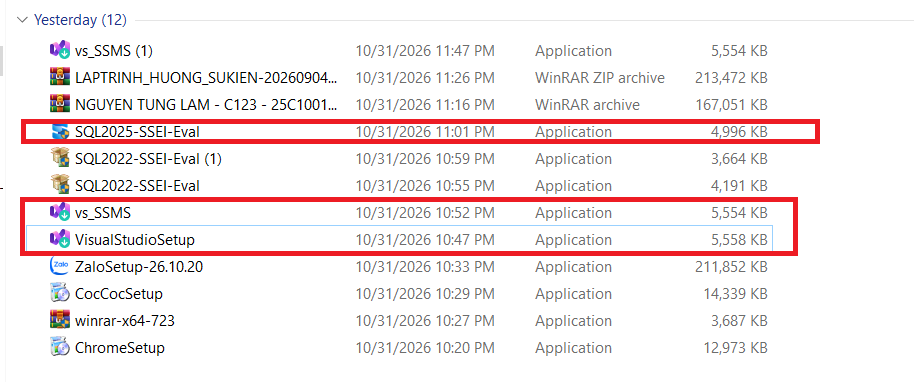

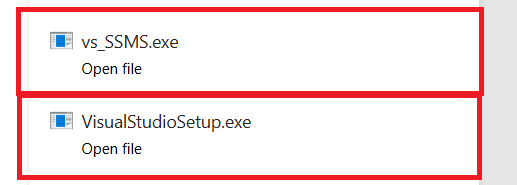

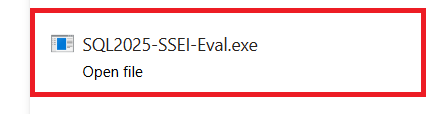

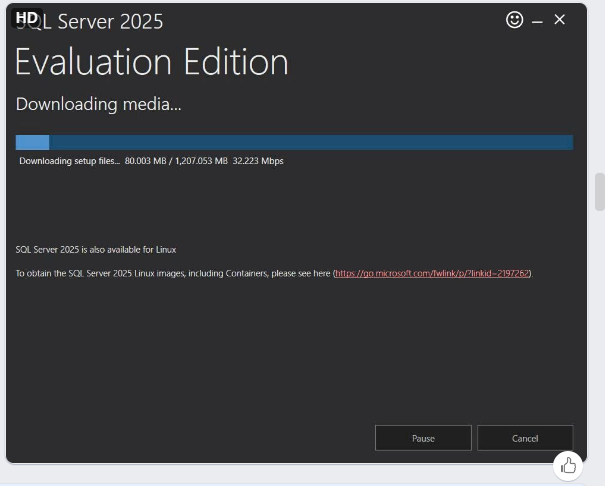

DUNG EVALUATION EDITION

Bước 2 là tạo 1 cái Folder trắng tinh

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN

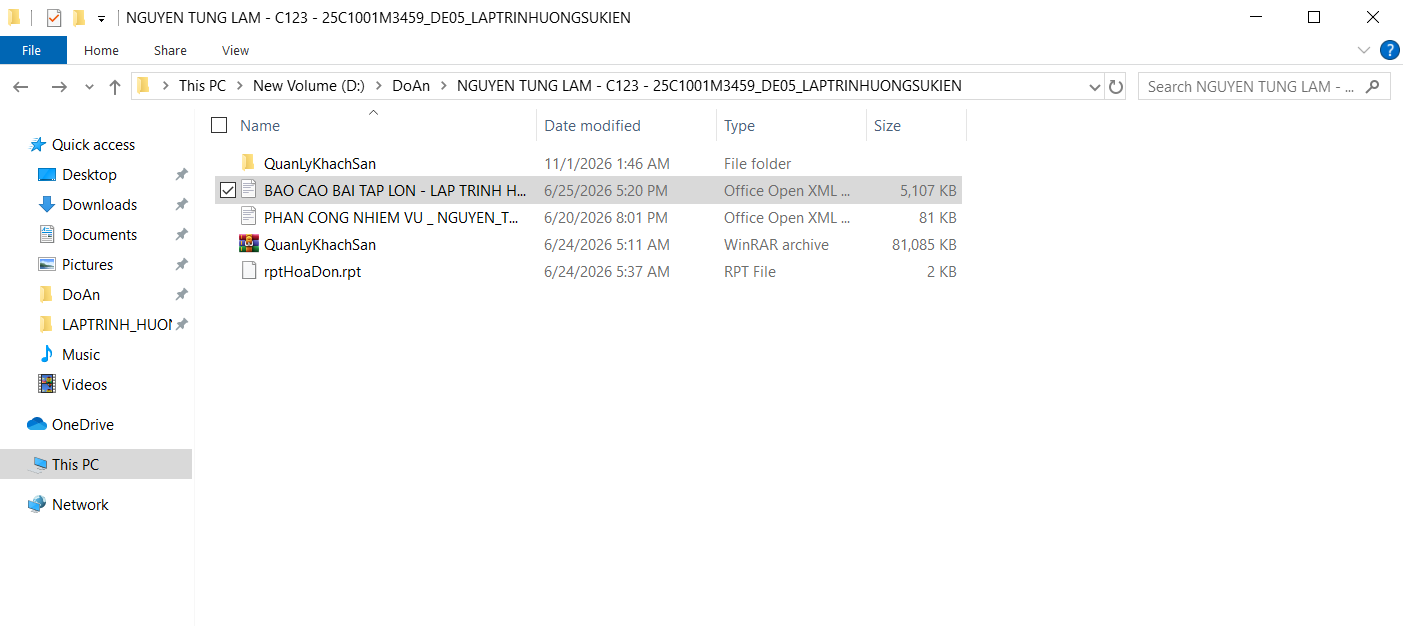

BUOC 3 : DOWNLOAD GITHUB PROJECT VE

https://github.com/LamNT411/QuanLyKhachSan

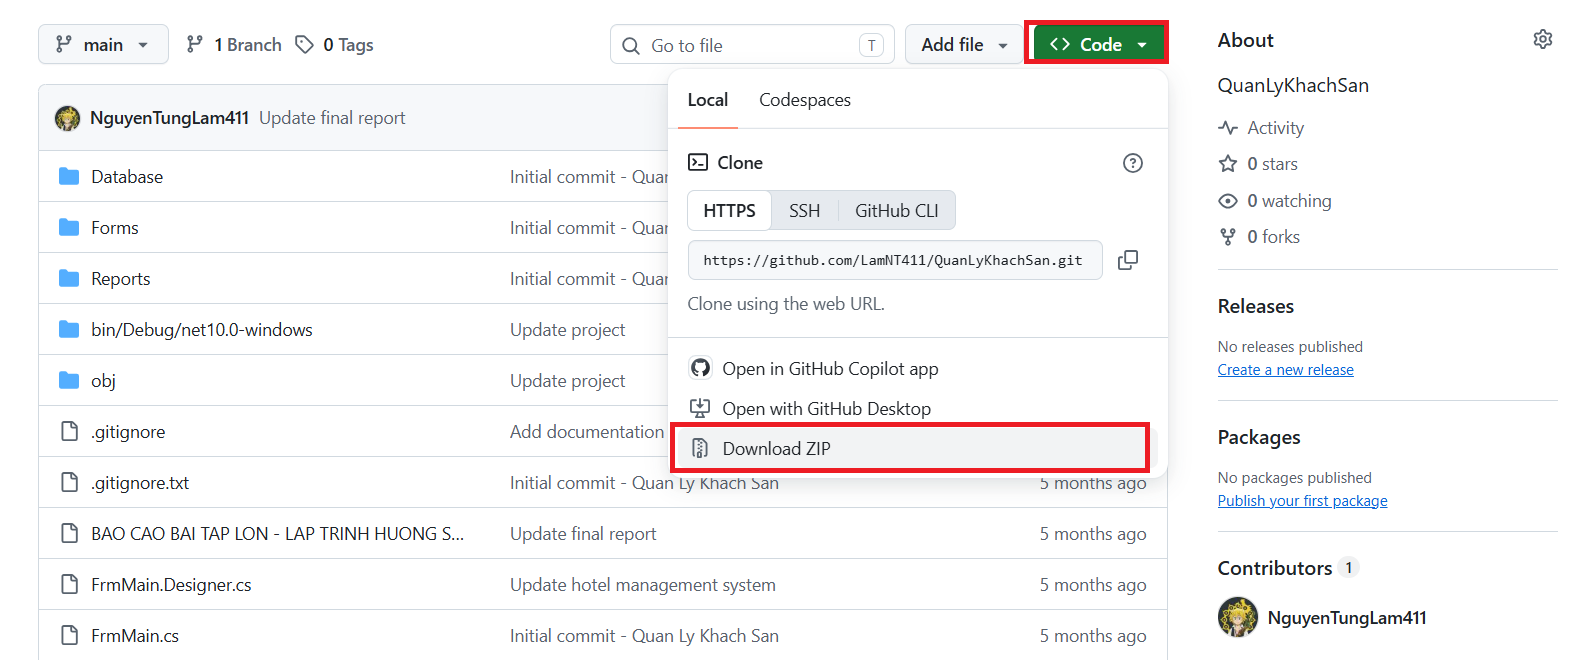

PASTE TAT CA VAO PROJECT FOLDER

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN

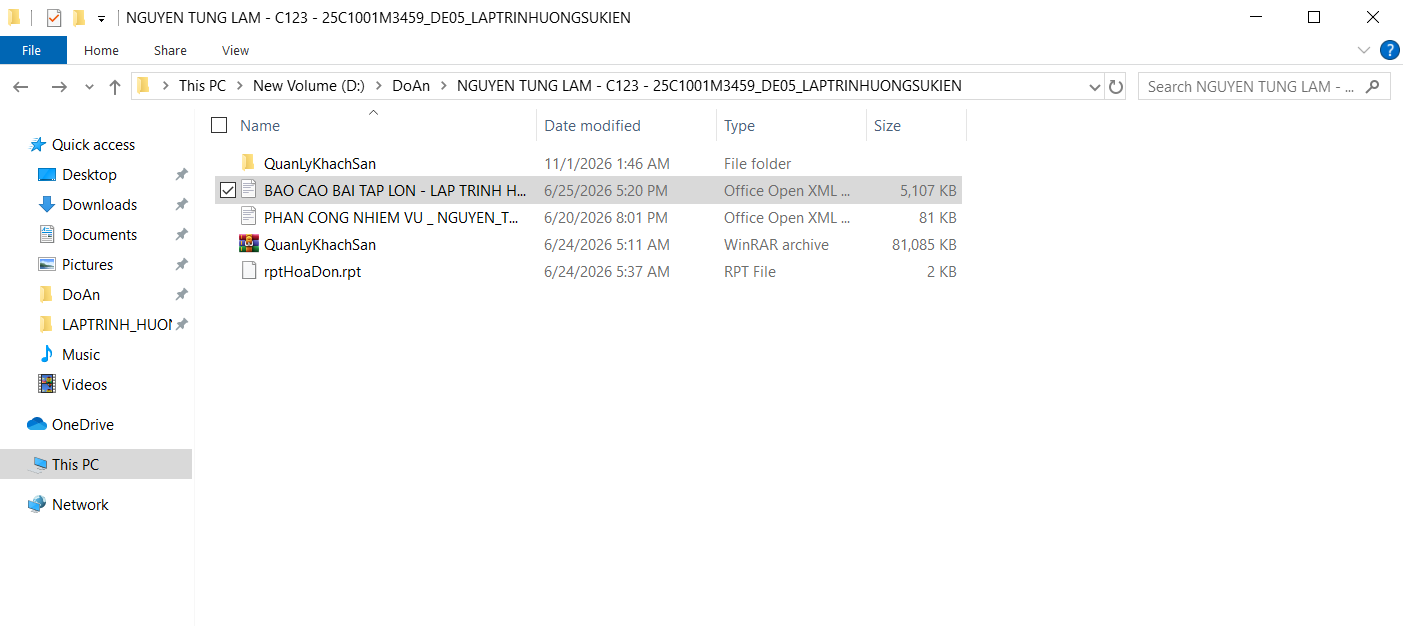

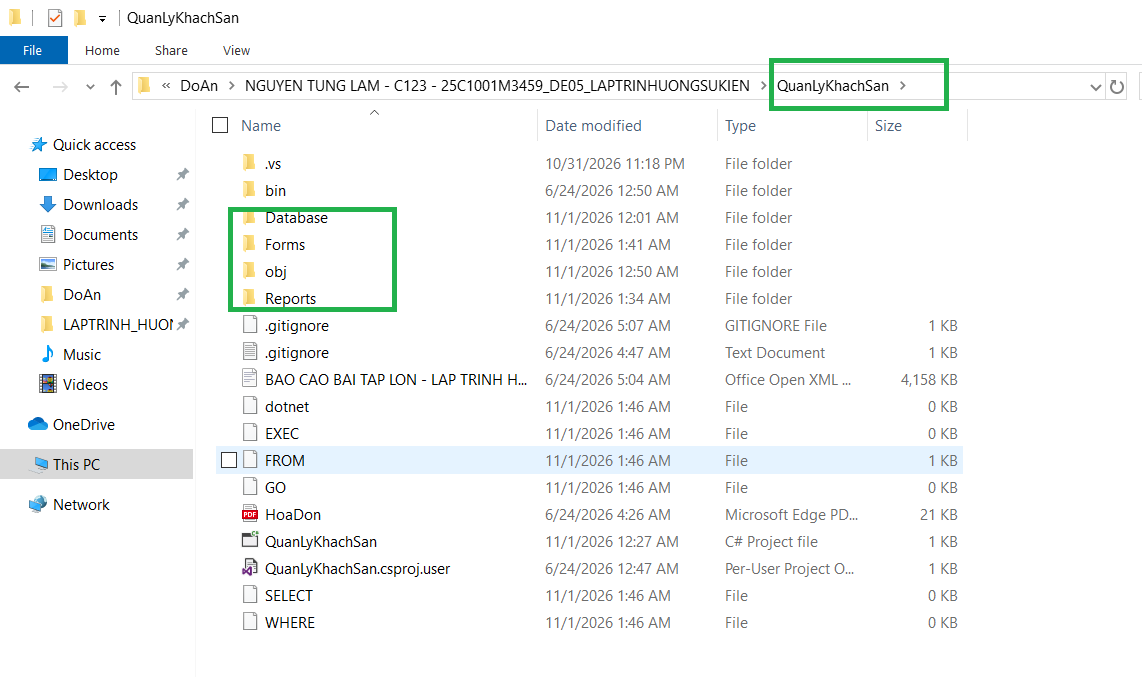

BUOC 4 : MO VISUAL STUDIO . EDIT LAI CODE CHO HOAN CHINH

NOTE 1 : FILE TREE

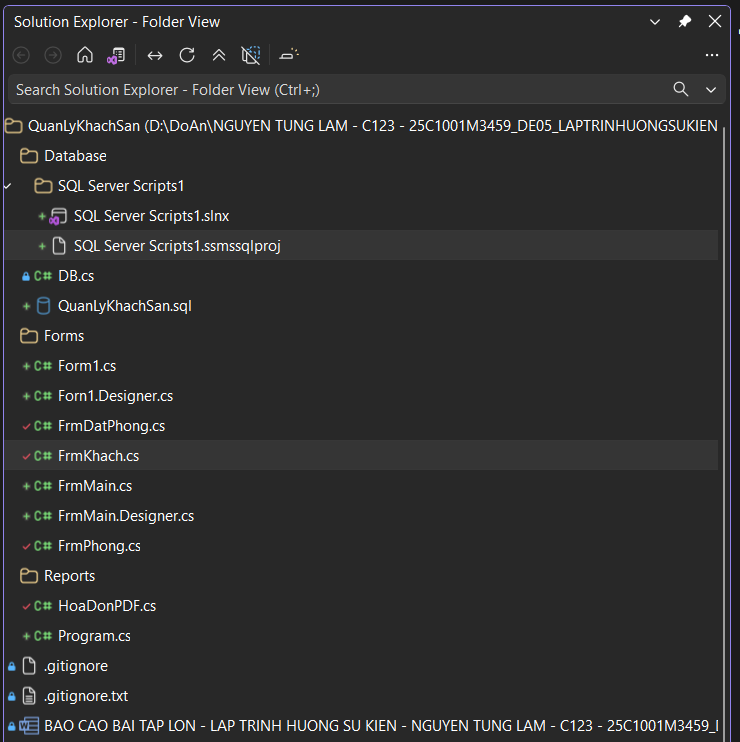

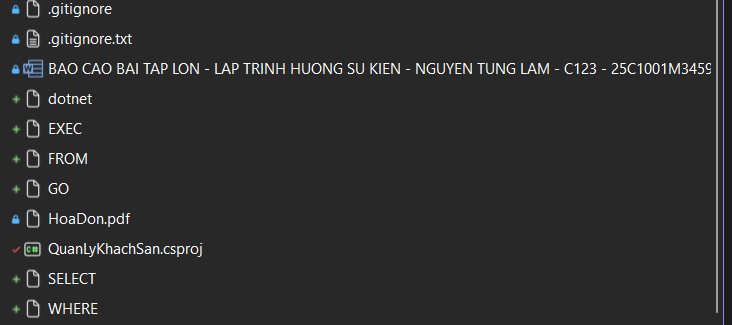

CODE

Program.cs

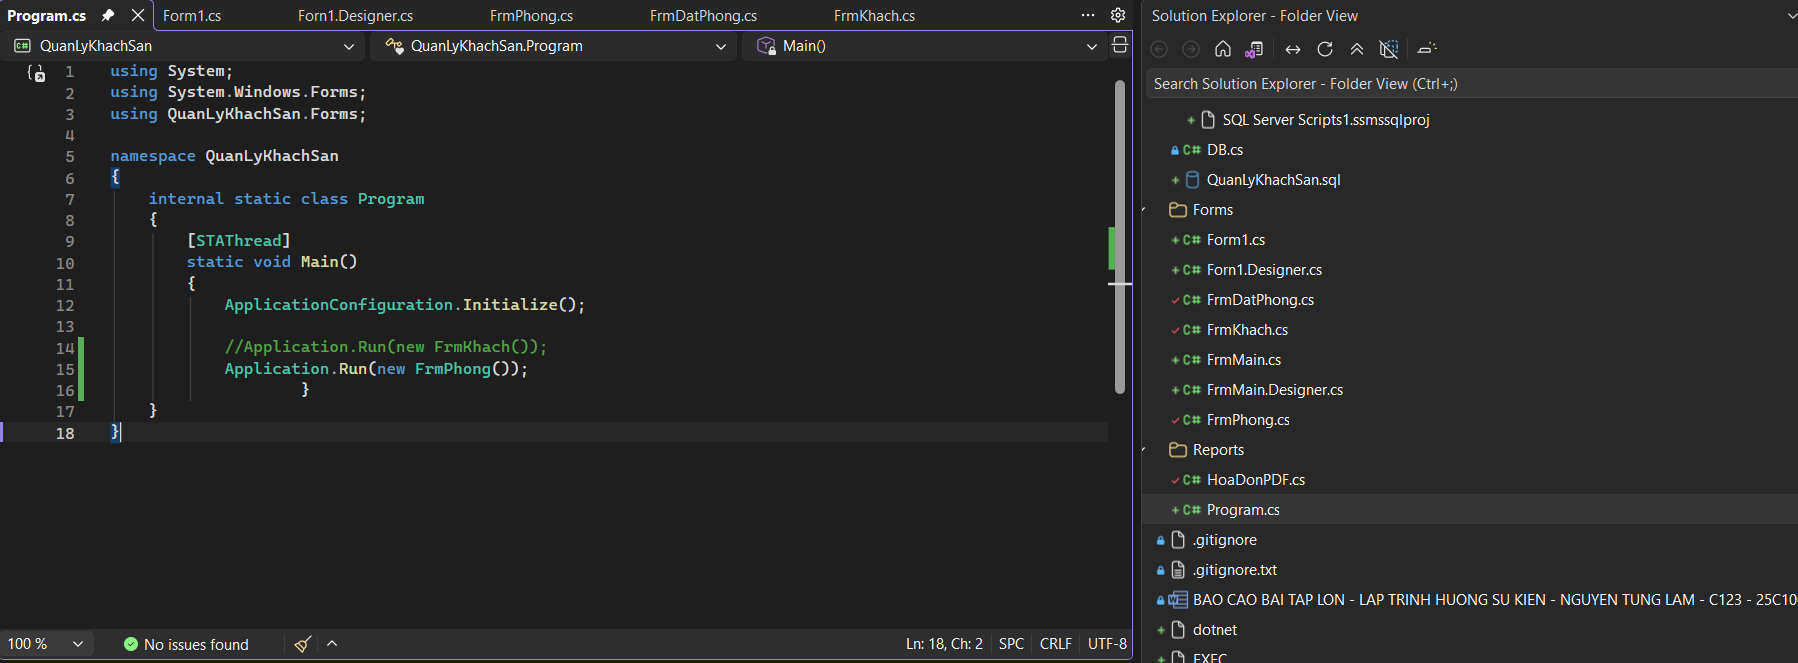

In [ ]:
using System;
using System.Windows.Forms;
using QuanLyKhachSan.Forms;

namespace QuanLyKhachSan
{
    internal static class Program
    {
        [STAThread]
        static void Main()
        {
            ApplicationConfiguration.Initialize();

            //Application.Run(new FrmKhach());
            Application.Run(new FrmPhong());
                    }
    }
}

Form1.cs

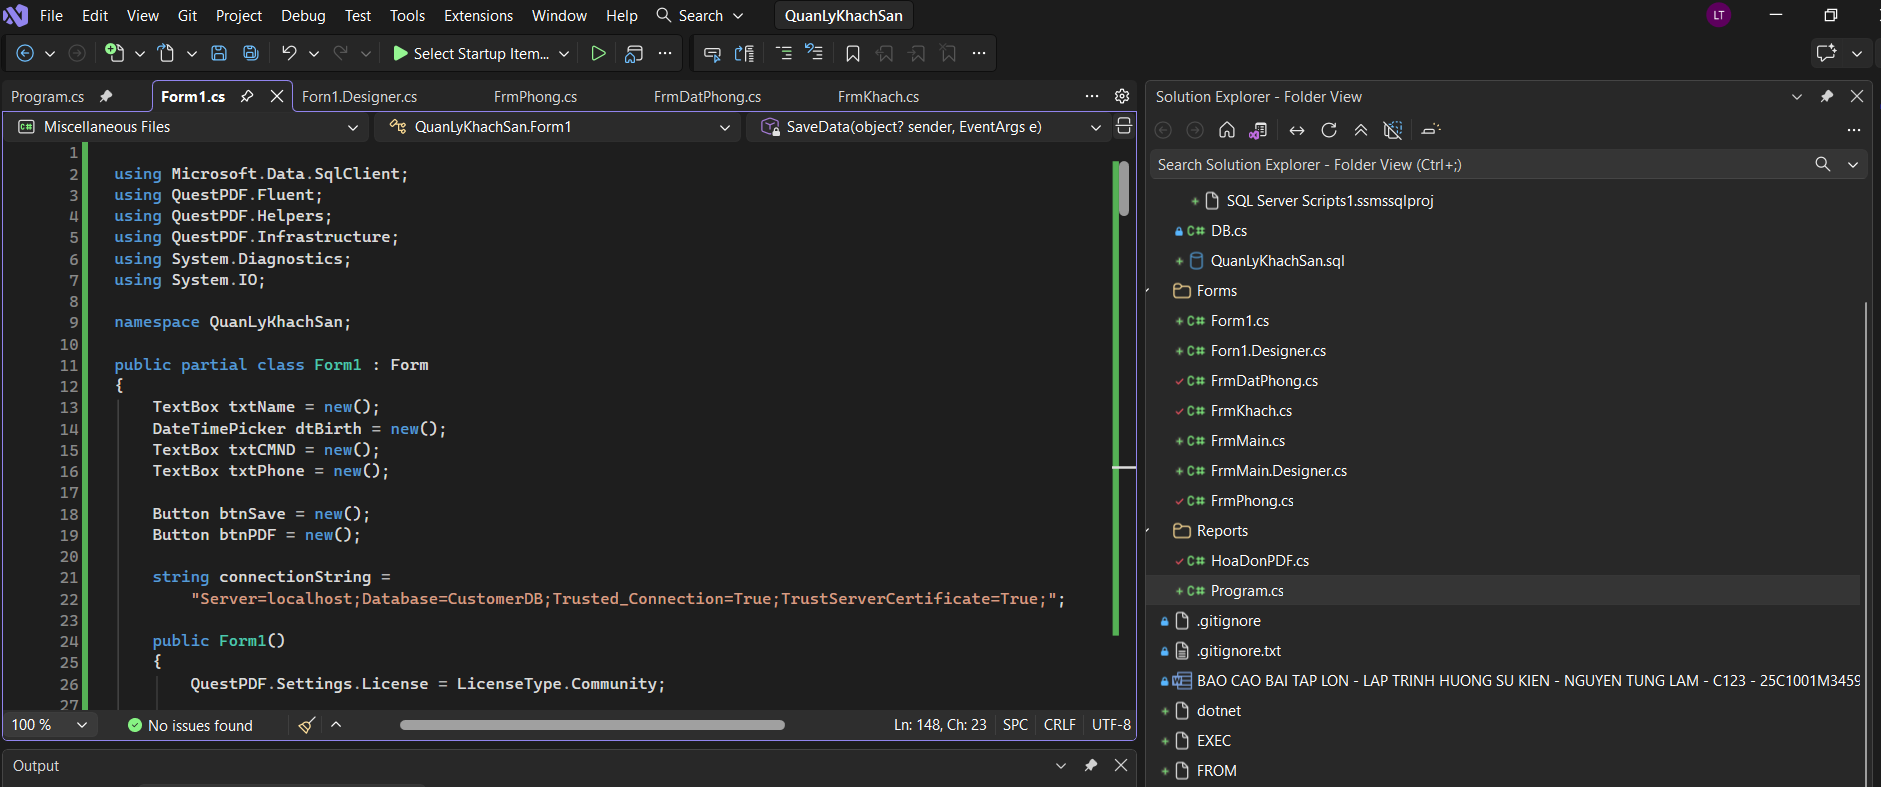

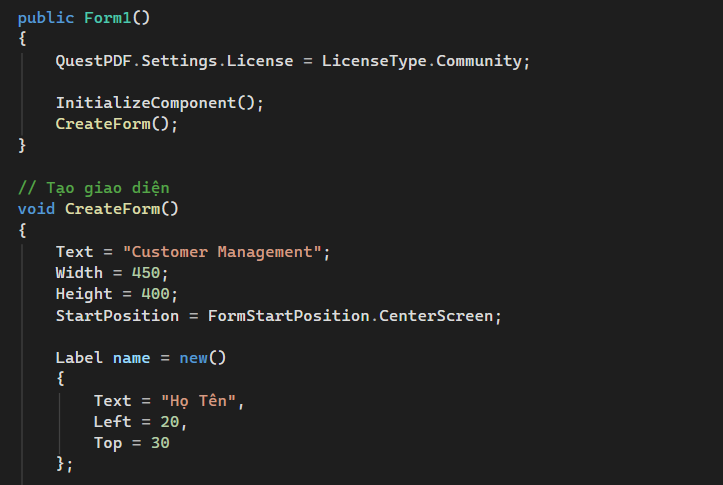

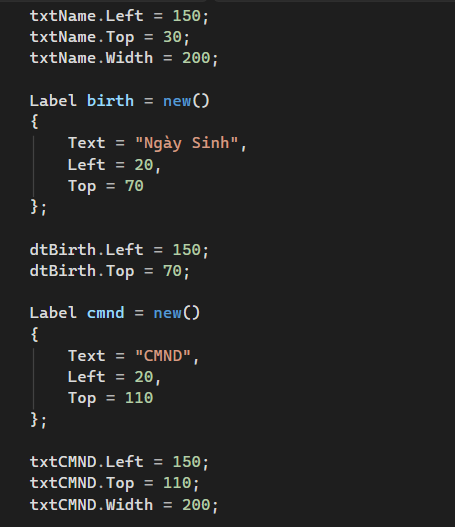

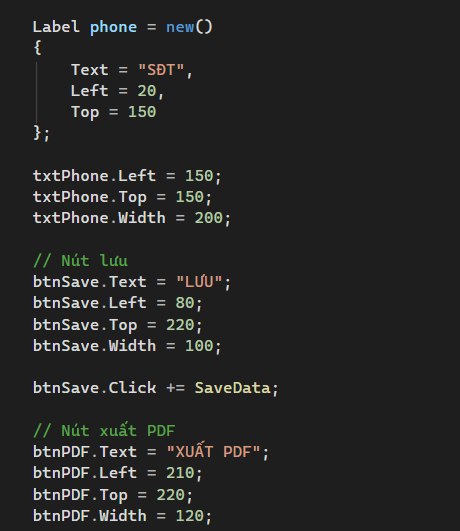

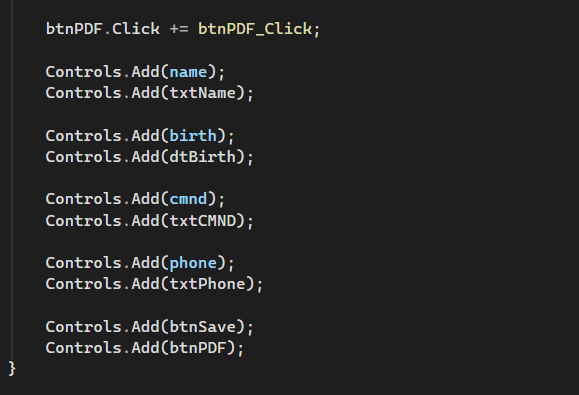

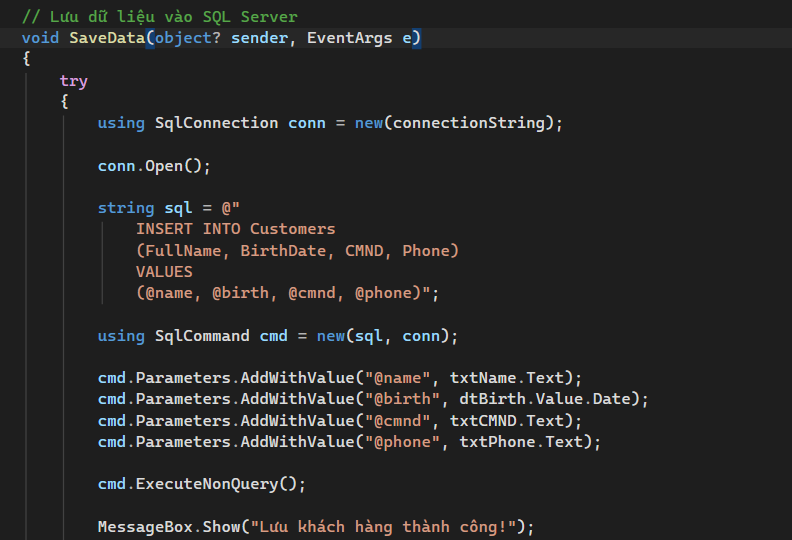

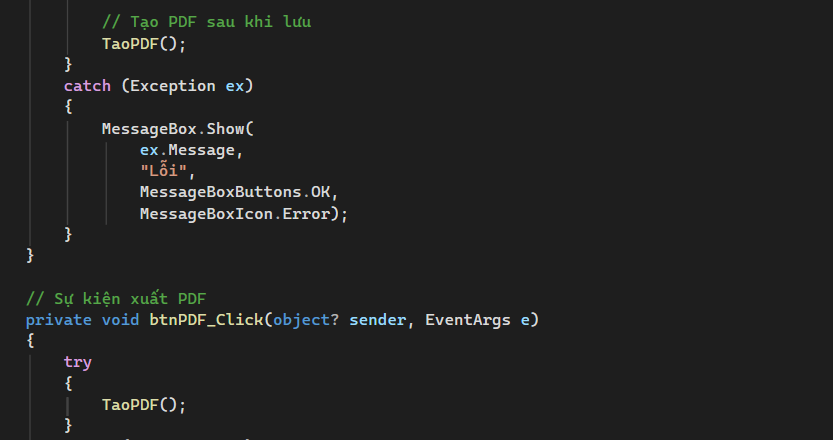

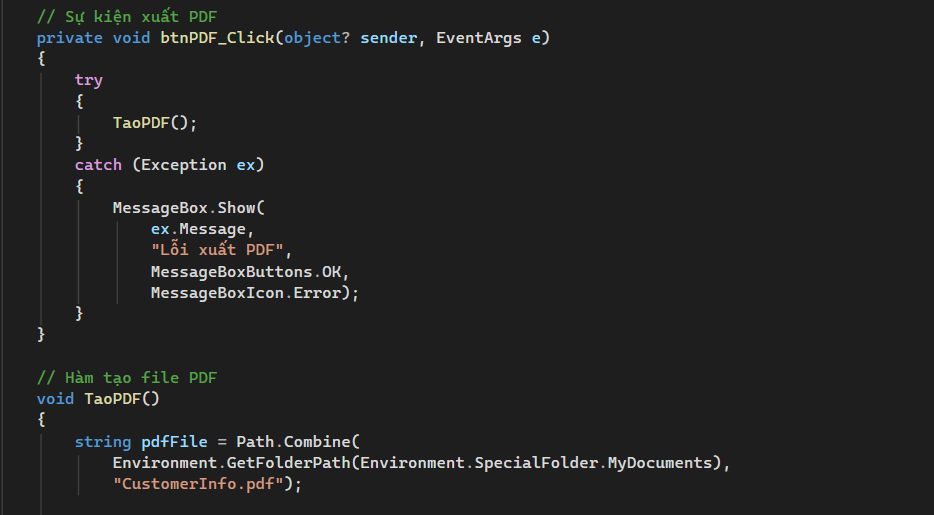

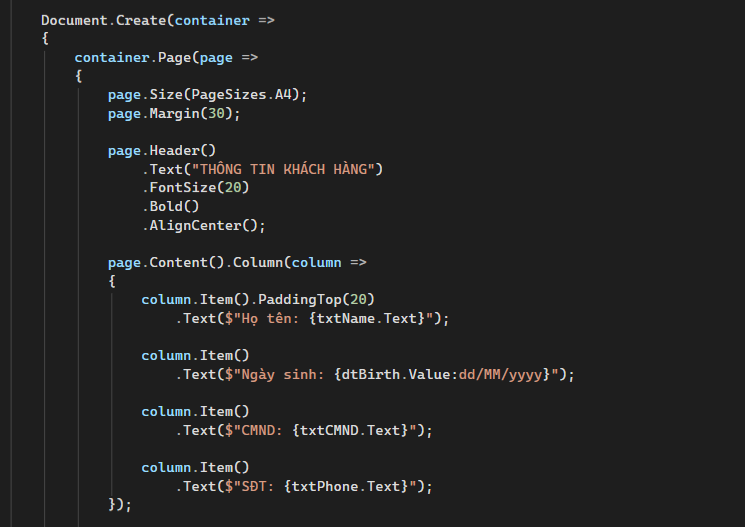

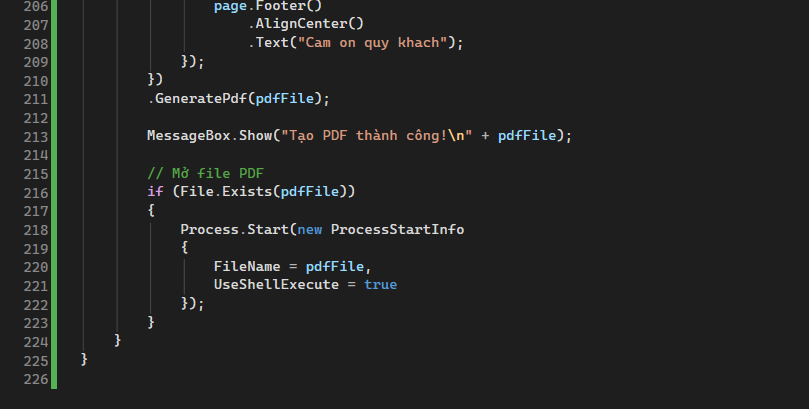

In [ ]:

using Microsoft.Data.SqlClient;
using QuestPDF.Fluent;
using QuestPDF.Helpers;
using QuestPDF.Infrastructure;
using System.Diagnostics;
using System.IO;

namespace QuanLyKhachSan;

public partial class Form1 : Form
{
    TextBox txtName = new();
    DateTimePicker dtBirth = new();
    TextBox txtCMND = new();
    TextBox txtPhone = new();

    Button btnSave = new();
    Button btnPDF = new();

    string connectionString =
        "Server=localhost;Database=CustomerDB;Trusted_Connection=True;TrustServerCertificate=True;";

    public Form1()
    {
        QuestPDF.Settings.License = LicenseType.Community;

        InitializeComponent();
        CreateForm();
    }

    // Tạo giao diện
    void CreateForm()
    {
        Text = "Customer Management";
        Width = 450;
        Height = 400;
        StartPosition = FormStartPosition.CenterScreen;

        Label name = new()
        {
            Text = "Họ Tên",
            Left = 20,
            Top = 30
        };

        txtName.Left = 150;
        txtName.Top = 30;
        txtName.Width = 200;

        Label birth = new()
        {
            Text = "Ngày Sinh",
            Left = 20,
            Top = 70
        };

        dtBirth.Left = 150;
        dtBirth.Top = 70;

        Label cmnd = new()
        {
            Text = "CMND",
            Left = 20,
            Top = 110
        };

        txtCMND.Left = 150;
        txtCMND.Top = 110;
        txtCMND.Width = 200;

        Label phone = new()
        {
            Text = "SĐT",
            Left = 20,
            Top = 150
        };

        txtPhone.Left = 150;
        txtPhone.Top = 150;
        txtPhone.Width = 200;

        // Nút lưu
        btnSave.Text = "LƯU";
        btnSave.Left = 80;
        btnSave.Top = 220;
        btnSave.Width = 100;

        btnSave.Click += SaveData;

        // Nút xuất PDF
        btnPDF.Text = "XUẤT PDF";
        btnPDF.Left = 210;
        btnPDF.Top = 220;
        btnPDF.Width = 120;

        btnPDF.Click += btnPDF_Click;

        Controls.Add(name);
        Controls.Add(txtName);

        Controls.Add(birth);
        Controls.Add(dtBirth);

        Controls.Add(cmnd);
        Controls.Add(txtCMND);

        Controls.Add(phone);
        Controls.Add(txtPhone);

        Controls.Add(btnSave);
        Controls.Add(btnPDF);
    }

    // Lưu dữ liệu vào SQL Server
    void SaveData(object? sender, EventArgs e)
    {
        try
        {
            using SqlConnection conn = new(connectionString);

            conn.Open();

            string sql = @"
                INSERT INTO Customers
                (FullName, BirthDate, CMND, Phone)
                VALUES
                (@name, @birth, @cmnd, @phone)";

            using SqlCommand cmd = new(sql, conn);

            cmd.Parameters.AddWithValue("@name", txtName.Text);
            cmd.Parameters.AddWithValue("@birth", dtBirth.Value.Date);
            cmd.Parameters.AddWithValue("@cmnd", txtCMND.Text);
            cmd.Parameters.AddWithValue("@phone", txtPhone.Text);

            cmd.ExecuteNonQuery();

            MessageBox.Show("Lưu khách hàng thành công!");

            // Tạo PDF sau khi lưu
            TaoPDF();
        }
        catch (Exception ex)
        {
            MessageBox.Show(
                ex.Message,
                "Lỗi",
                MessageBoxButtons.OK,
                MessageBoxIcon.Error);
        }
    }

    // Sự kiện xuất PDF
    private void btnPDF_Click(object? sender, EventArgs e)
    {
        try
        {
            TaoPDF();
        }
        catch (Exception ex)
        {
            MessageBox.Show(
                ex.Message,
                "Lỗi xuất PDF",
                MessageBoxButtons.OK,
                MessageBoxIcon.Error);
        }
    }

    // Hàm tạo file PDF
    void TaoPDF()
    {
        string pdfFile = Path.Combine(
            Environment.GetFolderPath(Environment.SpecialFolder.MyDocuments),
            "CustomerInfo.pdf");

        Document.Create(container =>
        {
            container.Page(page =>
            {
                page.Size(PageSizes.A4);
                page.Margin(30);

                page.Header()
                    .Text("THÔNG TIN KHÁCH HÀNG")
                    .FontSize(20)
                    .Bold()
                    .AlignCenter();

                page.Content().Column(column =>
                {
                    column.Item().PaddingTop(20)
                        .Text($"Họ tên: {txtName.Text}");

                    column.Item()
                        .Text($"Ngày sinh: {dtBirth.Value:dd/MM/yyyy}");

                    column.Item()
                        .Text($"CMND: {txtCMND.Text}");

                    column.Item()
                        .Text($"SĐT: {txtPhone.Text}");
                });

                page.Footer()
                    .AlignCenter()
                    .Text("Cam on quy khach");
            });
        })
        .GeneratePdf(pdfFile);

        MessageBox.Show("Tạo PDF thành công!\n" + pdfFile);

        // Mở file PDF
        if (File.Exists(pdfFile))
        {
            Process.Start(new ProcessStartInfo
            {
                FileName = pdfFile,
                UseShellExecute = true
            });
        }
    }
}


Form1.Designer.cs

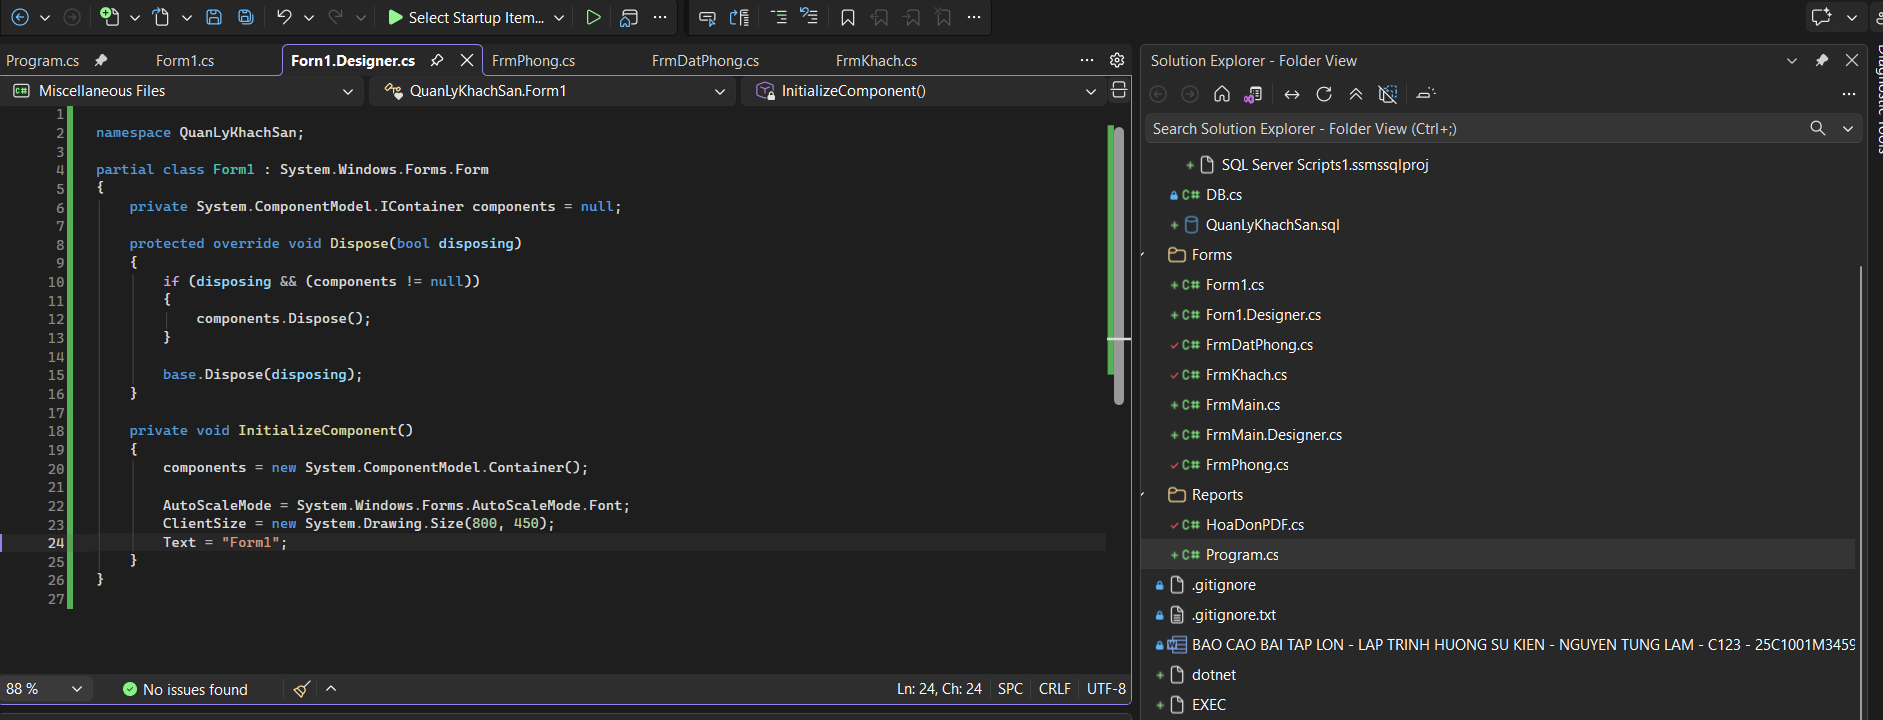

In [ ]:

namespace QuanLyKhachSan;

partial class Form1 : System.Windows.Forms.Form
{
    private System.ComponentModel.IContainer components = null;

    protected override void Dispose(bool disposing)
    {
        if (disposing && (components != null))
        {
            components.Dispose();
        }

        base.Dispose(disposing);
    }

    private void InitializeComponent()
    {
        components = new System.ComponentModel.Container();

        AutoScaleMode = System.Windows.Forms.AutoScaleMode.Font;
        ClientSize = new System.Drawing.Size(800, 450);
        Text = "Form1";
    }
}


FrmDatPhong.cs

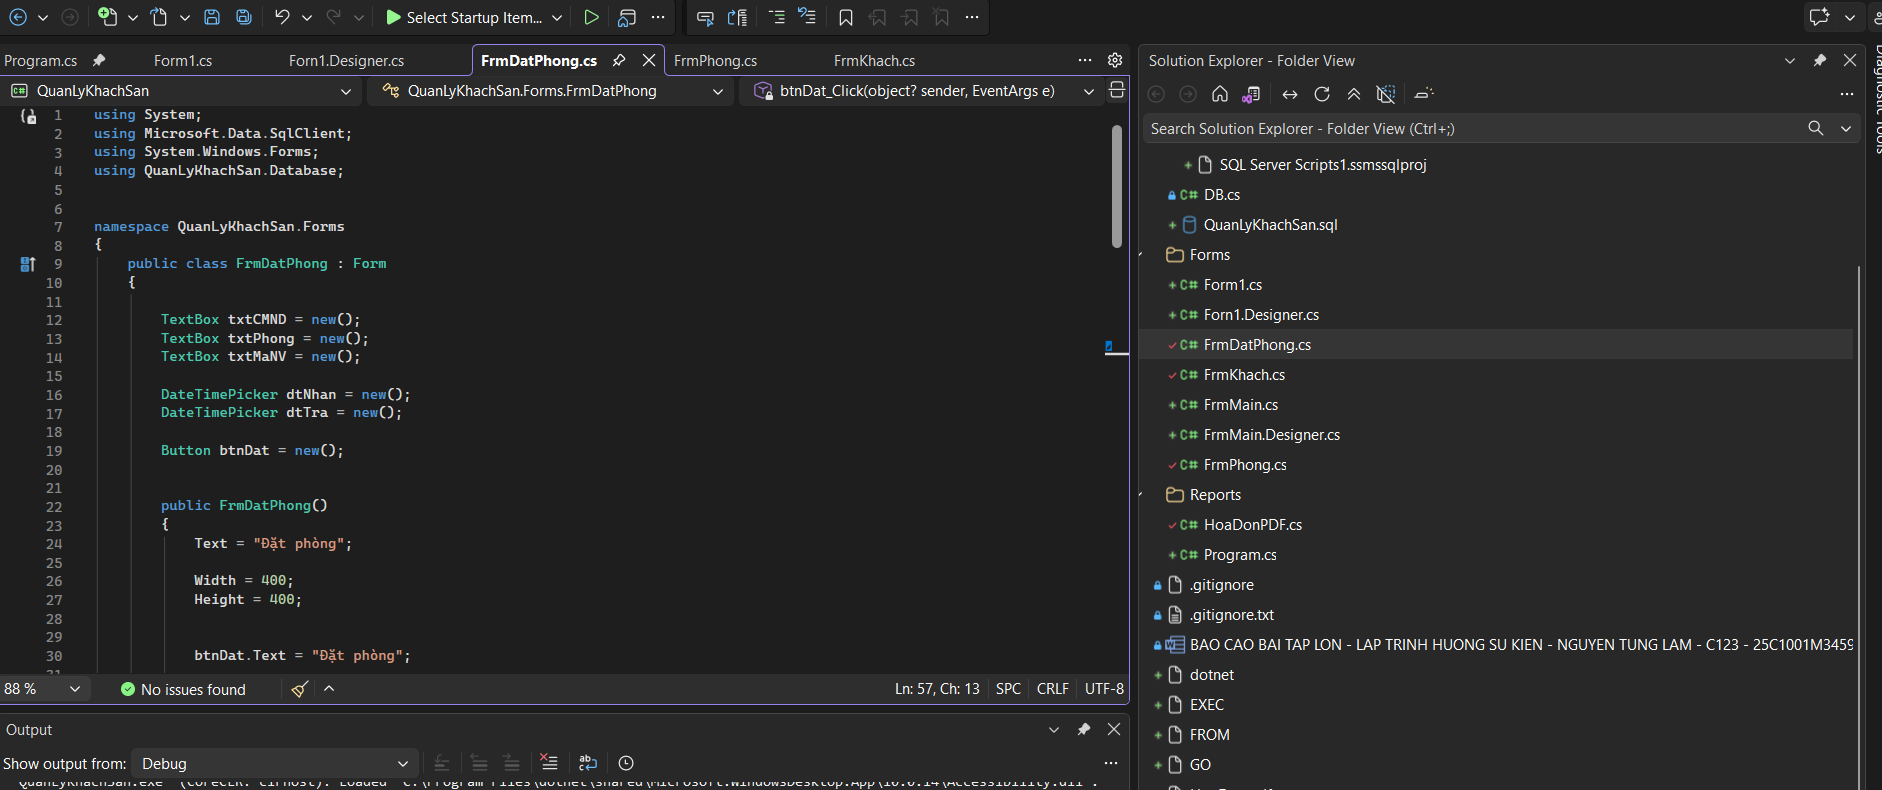

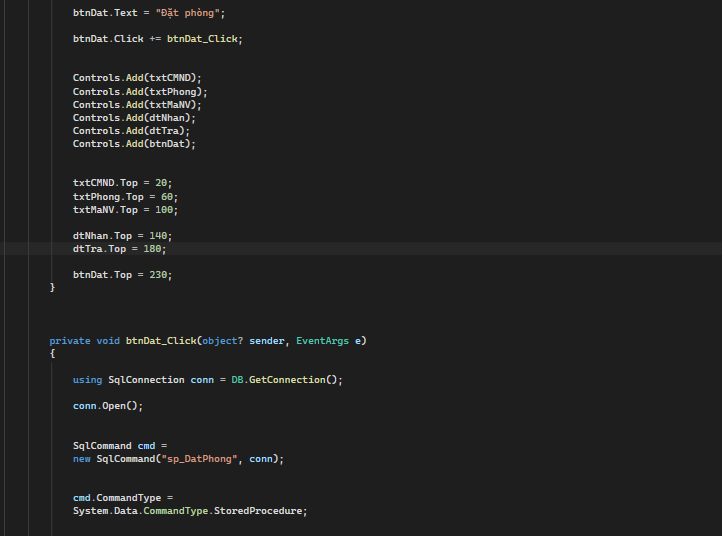

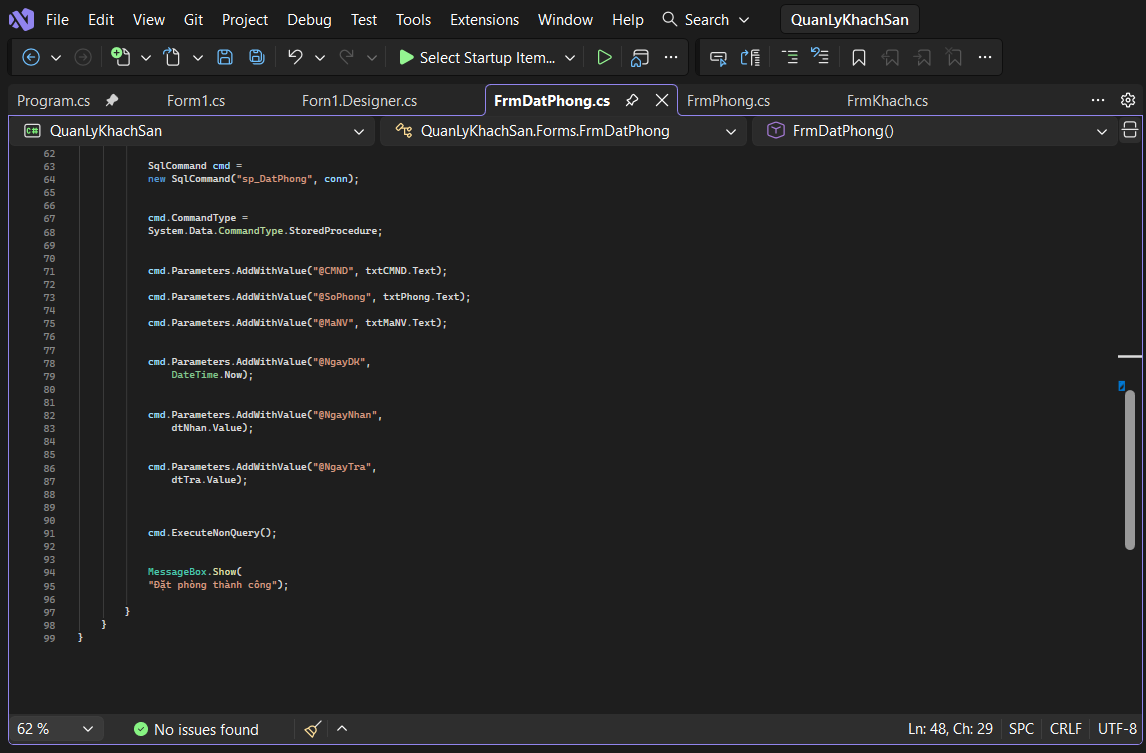

In [ ]:
using System;
using Microsoft.Data.SqlClient;
using System.Windows.Forms;
using QuanLyKhachSan.Database;


namespace QuanLyKhachSan.Forms
{
    public class FrmDatPhong : Form
    {

        TextBox txtCMND = new();
        TextBox txtPhong = new();
        TextBox txtMaNV = new();

        DateTimePicker dtNhan = new();
        DateTimePicker dtTra = new();

        Button btnDat = new();


        public FrmDatPhong()
        {
            Text = "Đặt phòng";

            Width = 400;
            Height = 400;


            btnDat.Text = "Đặt phòng";

            btnDat.Click += btnDat_Click;


            Controls.Add(txtCMND);
            Controls.Add(txtPhong);
            Controls.Add(txtMaNV);
            Controls.Add(dtNhan);
            Controls.Add(dtTra);
            Controls.Add(btnDat);


            txtCMND.Top = 20;
            txtPhong.Top = 60;
            txtMaNV.Top = 100;

            dtNhan.Top = 140;
            dtTra.Top = 180;

            btnDat.Top = 230;
        }



        private void btnDat_Click(object? sender, EventArgs e)
        {

            using SqlConnection conn = DB.GetConnection();

            conn.Open();


            SqlCommand cmd =
            new SqlCommand("sp_DatPhong", conn);


            cmd.CommandType =
            System.Data.CommandType.StoredProcedure;


            cmd.Parameters.AddWithValue("@CMND", txtCMND.Text);

            cmd.Parameters.AddWithValue("@SoPhong", txtPhong.Text);

            cmd.Parameters.AddWithValue("@MaNV", txtMaNV.Text);


            cmd.Parameters.AddWithValue("@NgayDK",
                DateTime.Now);


            cmd.Parameters.AddWithValue("@NgayNhan",
                dtNhan.Value);


            cmd.Parameters.AddWithValue("@NgayTra",
                dtTra.Value);



            cmd.ExecuteNonQuery();


            MessageBox.Show(
            "Đặt phòng thành công");

        }
    }
}

FRMPHONG.CS

In [ ]:
using System;
using System.Data;
using Microsoft.Data.SqlClient;
using System.Windows.Forms;
using QuanLyKhachSan.Database;

namespace QuanLyKhachSan.Forms
{
    public class FrmPhong : Form
    {
        DataGridView dgvPhong = new DataGridView();

        public FrmPhong()
        {
            Text = "Quản lý phòng";
            Width = 800;
            Height = 500;

            dgvPhong.Dock = DockStyle.Fill;

            Controls.Add(dgvPhong);

            Load += FrmPhong_Load;
        }


        private void FrmPhong_Load(object? sender, EventArgs e)
        {
            LoadPhong();
        }


        private void LoadPhong()
        {
            using SqlConnection conn = DB.GetConnection();

            conn.Open();

            SqlDataAdapter da =
                new SqlDataAdapter(
                "SELECT * FROM tblPhong",
                conn);

            DataTable dt = new DataTable();

            da.Fill(dt);

            dgvPhong.DataSource = dt;
        }
    }
}

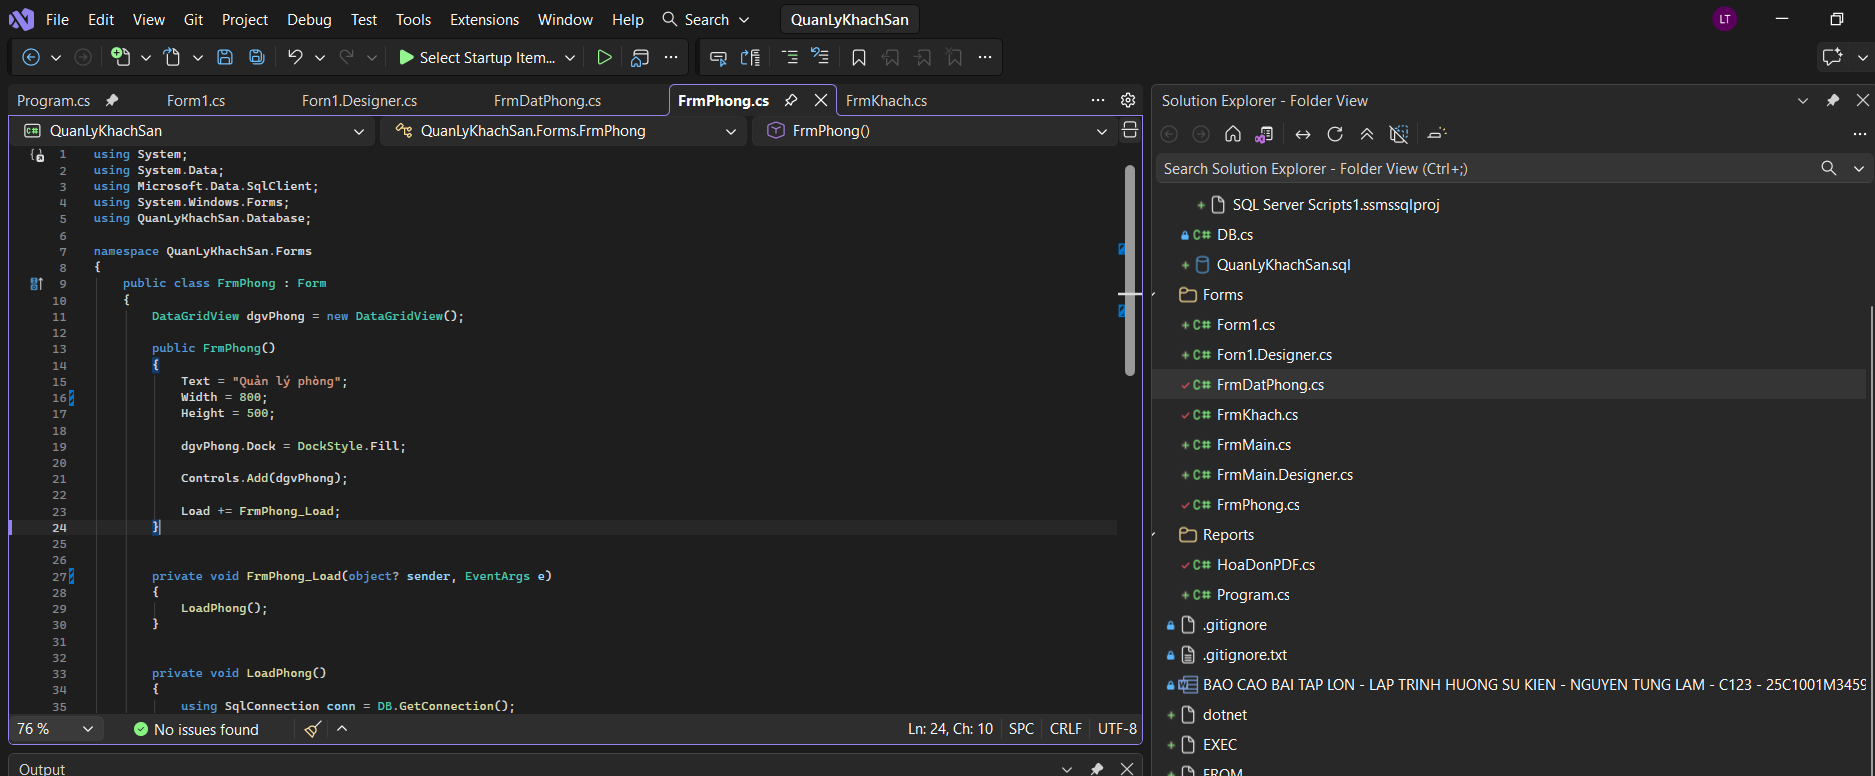

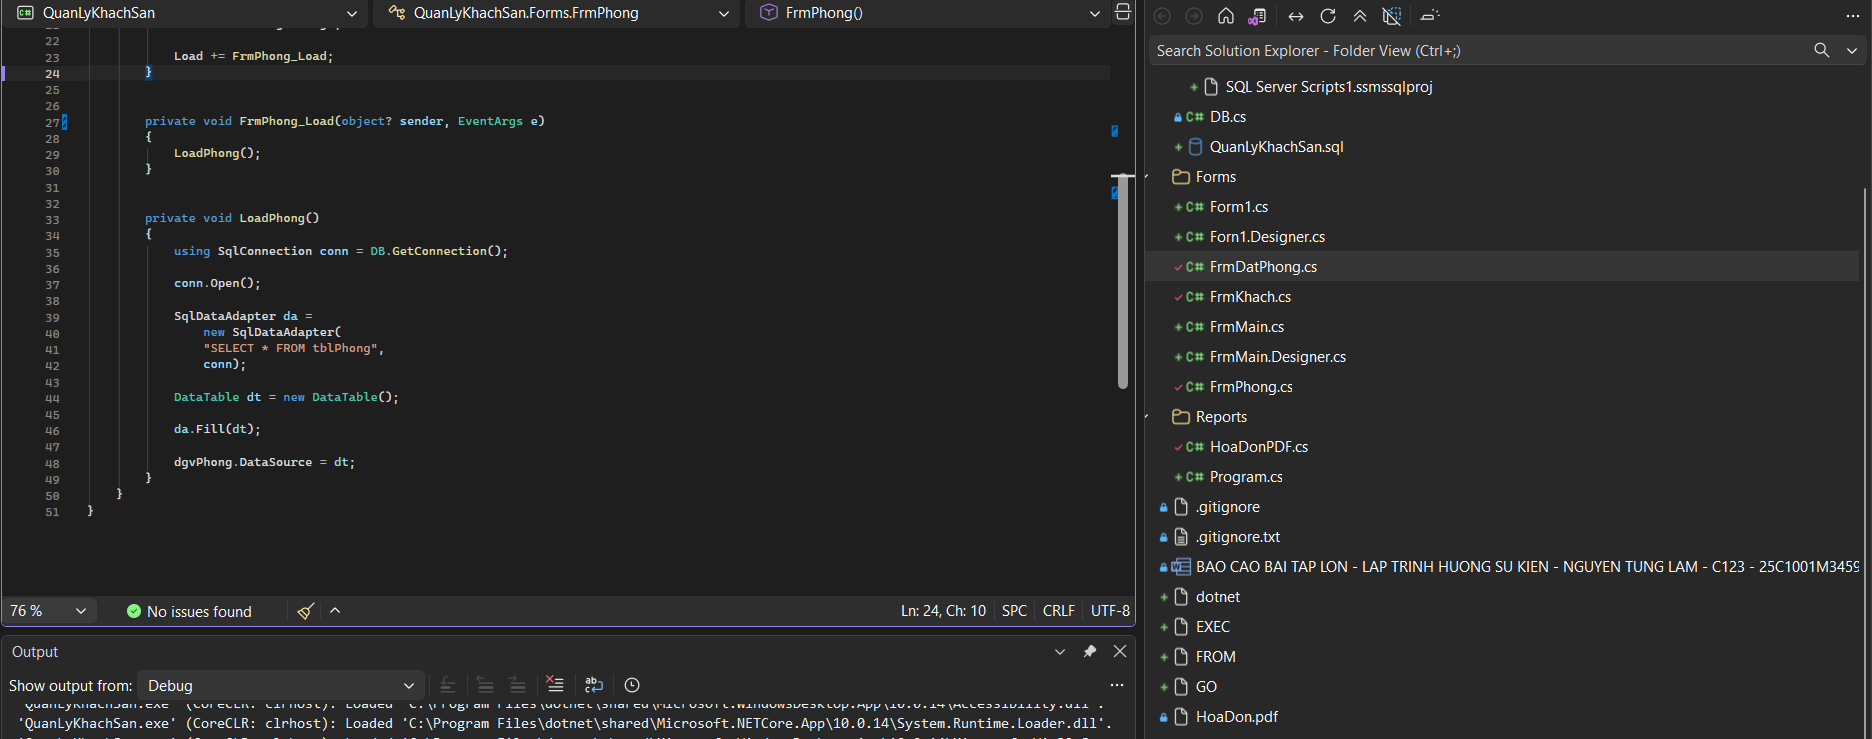

FrmKhach.cs

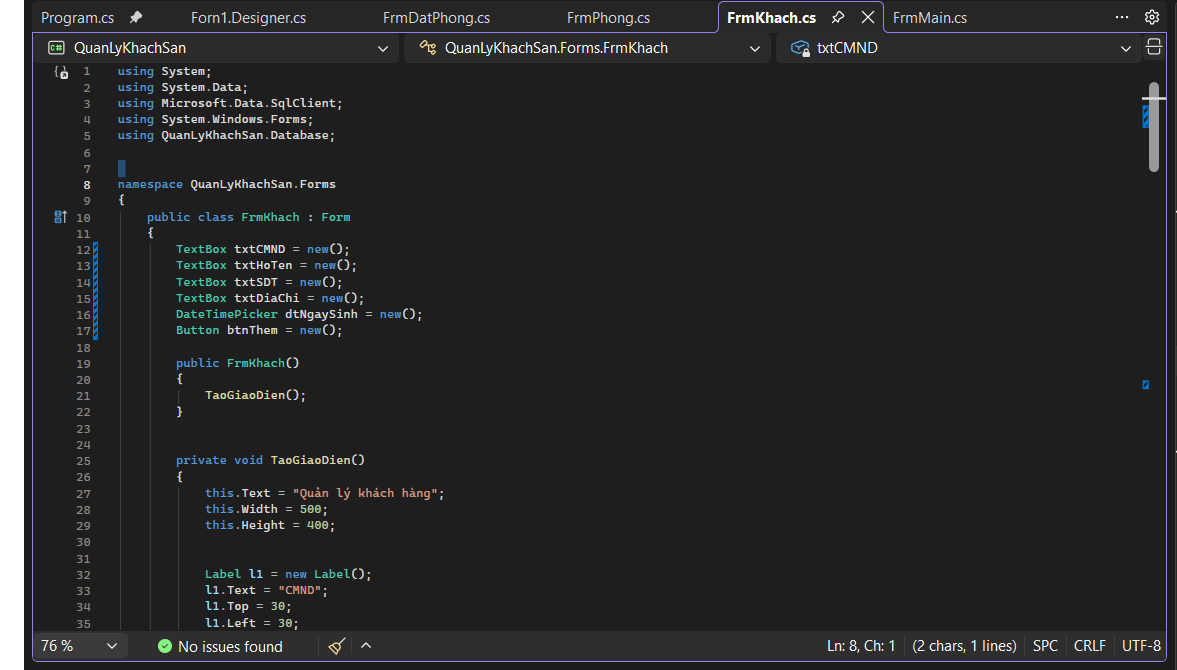

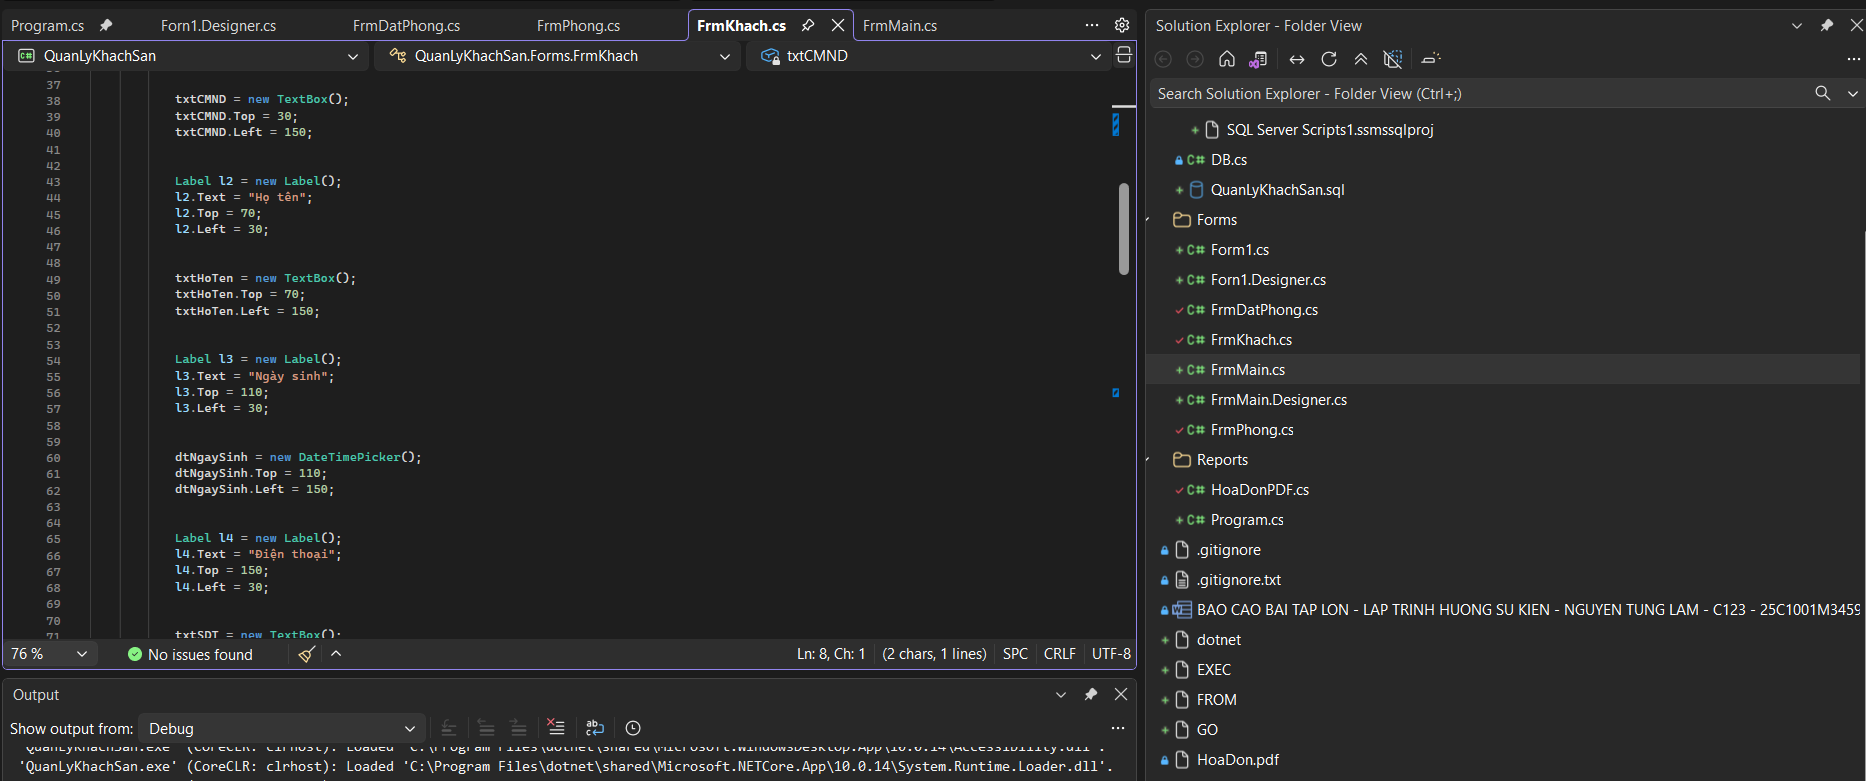

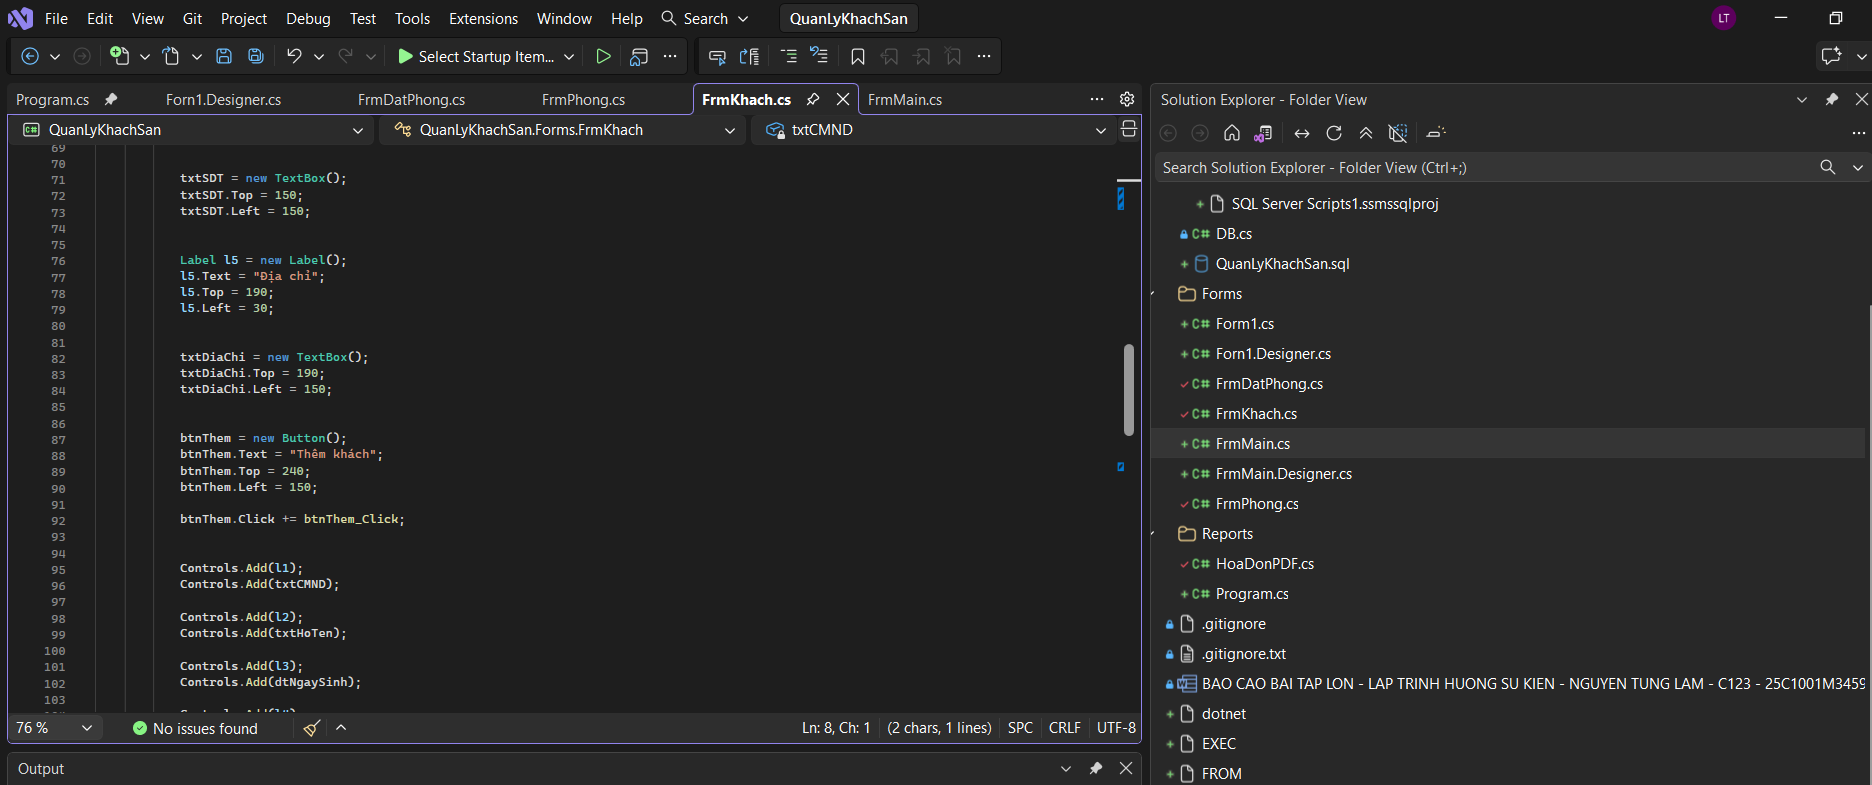

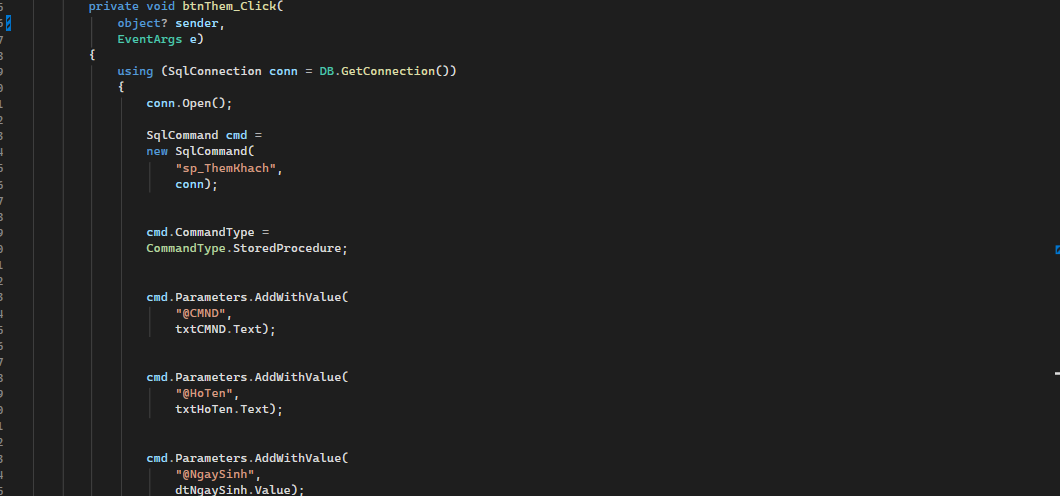

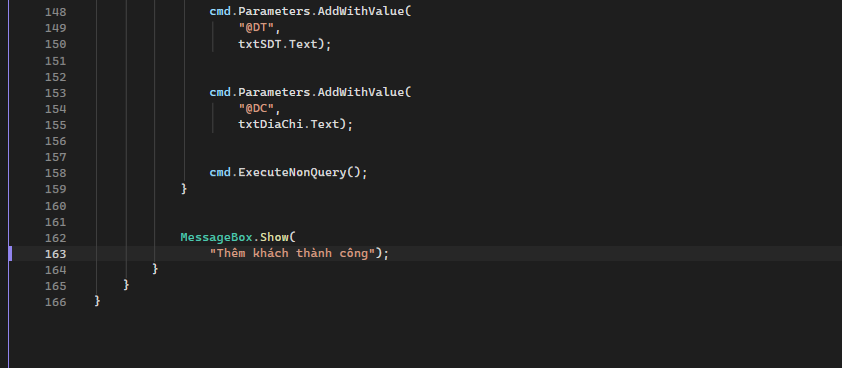

In [ ]:
using System;
using System.Data;
using Microsoft.Data.SqlClient;
using System.Windows.Forms;
using QuanLyKhachSan.Database;


namespace QuanLyKhachSan.Forms
{
    public class FrmKhach : Form
    {
        TextBox txtCMND = new();
        TextBox txtHoTen = new();
        TextBox txtSDT = new();
        TextBox txtDiaChi = new();
        DateTimePicker dtNgaySinh = new();
        Button btnThem = new();

        public FrmKhach()
        {
            TaoGiaoDien();
        }


        private void TaoGiaoDien()
        {
            this.Text = "Quản lý khách hàng";
            this.Width = 500;
            this.Height = 400;


            Label l1 = new Label();
            l1.Text = "CMND";
            l1.Top = 30;
            l1.Left = 30;


            txtCMND = new TextBox();
            txtCMND.Top = 30;
            txtCMND.Left = 150;


            Label l2 = new Label();
            l2.Text = "Họ tên";
            l2.Top = 70;
            l2.Left = 30;


            txtHoTen = new TextBox();
            txtHoTen.Top = 70;
            txtHoTen.Left = 150;


            Label l3 = new Label();
            l3.Text = "Ngày sinh";
            l3.Top = 110;
            l3.Left = 30;


            dtNgaySinh = new DateTimePicker();
            dtNgaySinh.Top = 110;
            dtNgaySinh.Left = 150;


            Label l4 = new Label();
            l4.Text = "Điện thoại";
            l4.Top = 150;
            l4.Left = 30;


            txtSDT = new TextBox();
            txtSDT.Top = 150;
            txtSDT.Left = 150;


            Label l5 = new Label();
            l5.Text = "Địa chỉ";
            l5.Top = 190;
            l5.Left = 30;


            txtDiaChi = new TextBox();
            txtDiaChi.Top = 190;
            txtDiaChi.Left = 150;


            btnThem = new Button();
            btnThem.Text = "Thêm khách";
            btnThem.Top = 240;
            btnThem.Left = 150;

            btnThem.Click += btnThem_Click;


            Controls.Add(l1);
            Controls.Add(txtCMND);

            Controls.Add(l2);
            Controls.Add(txtHoTen);

            Controls.Add(l3);
            Controls.Add(dtNgaySinh);

            Controls.Add(l4);
            Controls.Add(txtSDT);

            Controls.Add(l5);
            Controls.Add(txtDiaChi);

            Controls.Add(btnThem);
        }



        private void btnThem_Click(
            object? sender,
            EventArgs e)
        {
            using (SqlConnection conn = DB.GetConnection())
            {
                conn.Open();

                SqlCommand cmd =
                new SqlCommand(
                    "sp_ThemKhach",
                    conn);


                cmd.CommandType =
                CommandType.StoredProcedure;


                cmd.Parameters.AddWithValue(
                    "@CMND",
                    txtCMND.Text);


                cmd.Parameters.AddWithValue(
                    "@HoTen",
                    txtHoTen.Text);


                cmd.Parameters.AddWithValue(
                    "@NgaySinh",
                    dtNgaySinh.Value);


                cmd.Parameters.AddWithValue(
                    "@DT",
                    txtSDT.Text);


                cmd.Parameters.AddWithValue(
                    "@DC",
                    txtDiaChi.Text);


                cmd.ExecuteNonQuery();
            }


            MessageBox.Show(
                "Thêm khách thành công");
        }
    }
}

FrmMain.cs

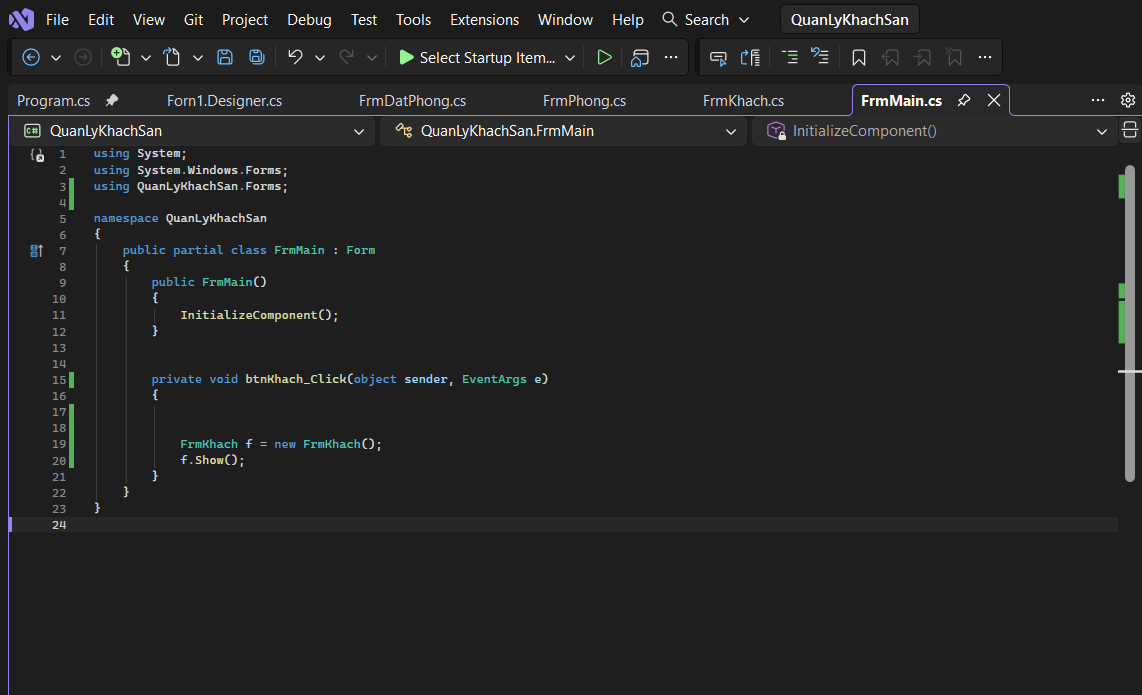

In [ ]:
using System;
using System.Windows.Forms;
using QuanLyKhachSan.Forms;

namespace QuanLyKhachSan
{
    public partial class FrmMain : Form
    {
        public FrmMain()
        {
            InitializeComponent();
        }


        private void btnKhach_Click(object sender, EventArgs e)
        {


            FrmKhach f = new FrmKhach();
            f.Show();
        }
    }
}


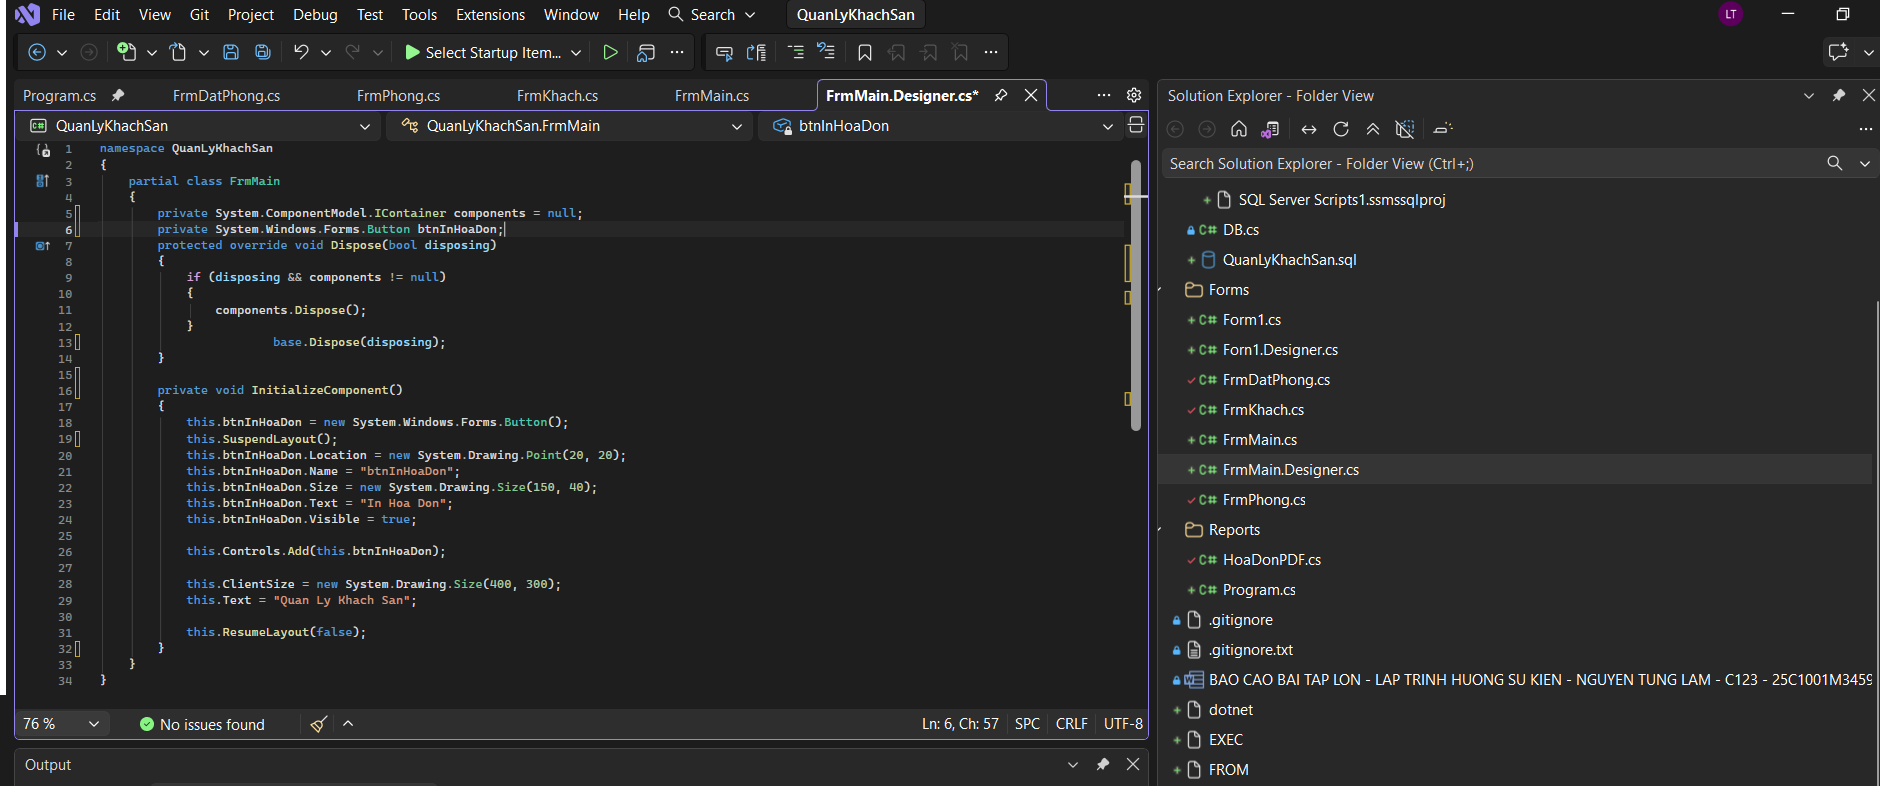

FrmMain.Designer.cs

In [ ]:
namespace QuanLyKhachSan
{
    partial class FrmMain
    {
        private System.ComponentModel.IContainer components = null;
        private System.Windows.Forms.Button btnInHoaDon;
        protected override void Dispose(bool disposing)
        {
            if (disposing && components != null)
            {
                components.Dispose();
            }
                        base.Dispose(disposing);
        }

        private void InitializeComponent()
        {
            this.btnInHoaDon = new System.Windows.Forms.Button();
            this.SuspendLayout();
            this.btnInHoaDon.Location = new System.Drawing.Point(20, 20);
            this.btnInHoaDon.Name = "btnInHoaDon";
            this.btnInHoaDon.Size = new System.Drawing.Size(150, 40);
            this.btnInHoaDon.Text = "In Hoa Don";
            this.btnInHoaDon.Visible = true;

            this.Controls.Add(this.btnInHoaDon);

            this.ClientSize = new System.Drawing.Size(400, 300);
            this.Text = "Quan Ly Khach San";

            this.ResumeLayout(false);
        }
    }
}

SQL SERVER

In [ ]:




CREATE DATABASE QLKhachSan
GO
USE QLKhachSan
GO

CREATE TABLE tblKhach (
    CMND VARCHAR(15) PRIMARY KEY,
    HoTen NVARCHAR(100),
    NgaySinh DATE,
    DienThoai VARCHAR(15),
    DiaChi NVARCHAR(200)
);

CREATE TABLE tblNhanvien (
    MaNV VARCHAR(10) PRIMARY KEY,
    HoTen NVARCHAR(100)
);

CREATE TABLE tblPhong (
    SoPhong VARCHAR(10) PRIMARY KEY,
    SucChua INT,
    DonGia DECIMAL(18,2),
    TinhTrang NVARCHAR(20)
);

CREATE TABLE tblDangky (
    MaDK INT IDENTITY PRIMARY KEY,
    CMND VARCHAR(15),
    MaNV VARCHAR(10),
    SoPhong VARCHAR(10),
    NgayDK DATE,
    NgayNhan DATE,
    NgayTra DATE,
    TrangThai NVARCHAR(20),

    FOREIGN KEY (CMND) REFERENCES tblKhach(CMND),
    FOREIGN KEY (MaNV) REFERENCES tblNhanvien(MaNV),
    FOREIGN KEY (SoPhong) REFERENCES tblPhong(SoPhong)
);

CREATE TABLE tblDichvu (
    MaDV VARCHAR(10) PRIMARY KEY,
    TenDV NVARCHAR(100),
    Gia DECIMAL(18,2)
);

CREATE TABLE tblCTDichvu (
    MaCT INT IDENTITY PRIMARY KEY,
    MaDK INT,
    MaDV VARCHAR(10),
    NgaySuDung DATE,
    SoLuong INT,

    FOREIGN KEY (MaDK) REFERENCES tblDangky(MaDK),
    FOREIGN KEY (MaDV) REFERENCES tblDichvu(MaDV)
);



-- 2. STORED PROCEDURES (BẮT BUỘC)
-- Thêm khách
CREATE PROC sp_ThemKhach
@CMND VARCHAR(15), @HoTen NVARCHAR(100), @NgaySinh DATE, @DT VARCHAR(15), @DC NVARCHAR(200)
AS
INSERT INTO tblKhach VALUES(@CMND,@HoTen,@NgaySinh,@DT,@DC)

-- Đặt phòng
CREATE PROC sp_DatPhong
@CMND VARCHAR(15), @MaNV VARCHAR(10), @SoPhong VARCHAR(10),
@NgayDK DATE, @NgayNhan DATE, @NgayTra DATE
AS
BEGIN
    INSERT INTO tblDangky VALUES
    (@CMND,@MaNV,@SoPhong,@NgayDK,@NgayNhan,@NgayTra,N'Đang thuê')

    UPDATE tblPhong SET TinhTrang=N'Đã thuê'
    WHERE SoPhong=@SoPhong
END

--Xóa đăng ký
CREATE PROC sp_XoaDK
@MaDK INT
AS
DELETE FROM tblDangky WHERE MaDK=@MaDK

--Thêm dịch vụ
CREATE PROC sp_ThemDV
@MaDK INT, @MaDV VARCHAR(10), @Ngay DATE, @SL INT
AS
INSERT INTO tblCTDichvu VALUES(@MaDK,@MaDV,@Ngay,@SL)


-- Store this in your SQL database

CREATE PROC sp_GenerateInvoiceReport
    @MaDK INT
AS
BEGIN
    -- First Result Set: Invoice Header/Summary
    SELECT
        k.HoTen AS TenKhachHang,
        k.CMND,
        k.DienThoai AS SoDienThoaiKhach,
        k.DiaChi AS DiaChiKhach,
        dk.MaDK,
        dk.NgayDK,
        dk.NgayNhan,
        dk.NgayTra,
        p.SoPhong,
        p.SucChua,
        p.DonGia AS DonGiaPhong,
        DATEDIFF(DAY, dk.NgayNhan, dk.NgayTra) AS SoNgayThue,
        (p.DonGia * DATEDIFF(DAY, dk.NgayNhan, dk.NgayTra)) AS TongTienPhong,
        ISNULL(SUM(ct.SoLuong * dv.Gia), 0) AS TongTienDichVu,
        (p.DonGia * DATEDIFF(DAY, dk.NgayNhan, dk.NgayTra)) + ISNULL(SUM(ct.SoLuong * dv.Gia), 0) AS TongThanhToan
    FROM tblDangky dk
    JOIN tblKhach k ON dk.CMND = k.CMND
    JOIN tblPhong p ON dk.SoPhong = p.SoPhong
    LEFT JOIN tblCTDichvu ct ON dk.MaDK = ct.MaDK
    LEFT JOIN tblDichvu dv ON ct.MaDV = dv.MaDV
    WHERE dk.MaDK = @MaDK
    GROUP BY
        k.HoTen, k.CMND, k.DienThoai, k.DiaChi,
        dk.MaDK, dk.NgayDK, dk.NgayNhan, dk.NgayTra,
        p.SoPhong, p.SucChua, p.DonGia;

    -- Second Result Set: Service Line Items
    SELECT
        dv.TenDV,
        ct.SoLuong,
        dv.Gia AS DonGiaDichVu,
        (ct.SoLuong * dv.Gia) AS ThanhTienDichVu,
        ct.NgaySuDung
    FROM tblCTDichvu ct
    JOIN tblDichvu dv ON ct.MaDV = dv.MaDV
    WHERE ct.MaDK = @MaDK;
END;

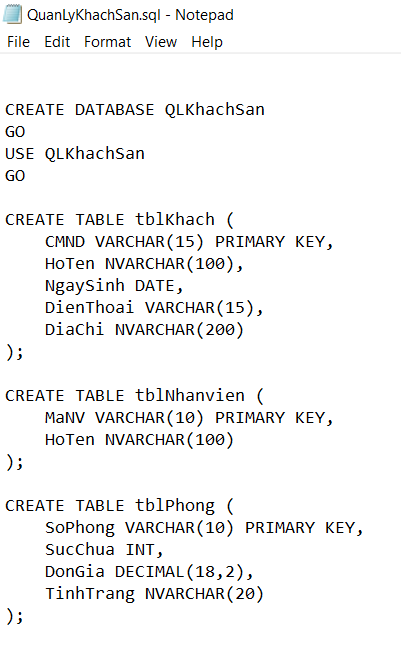

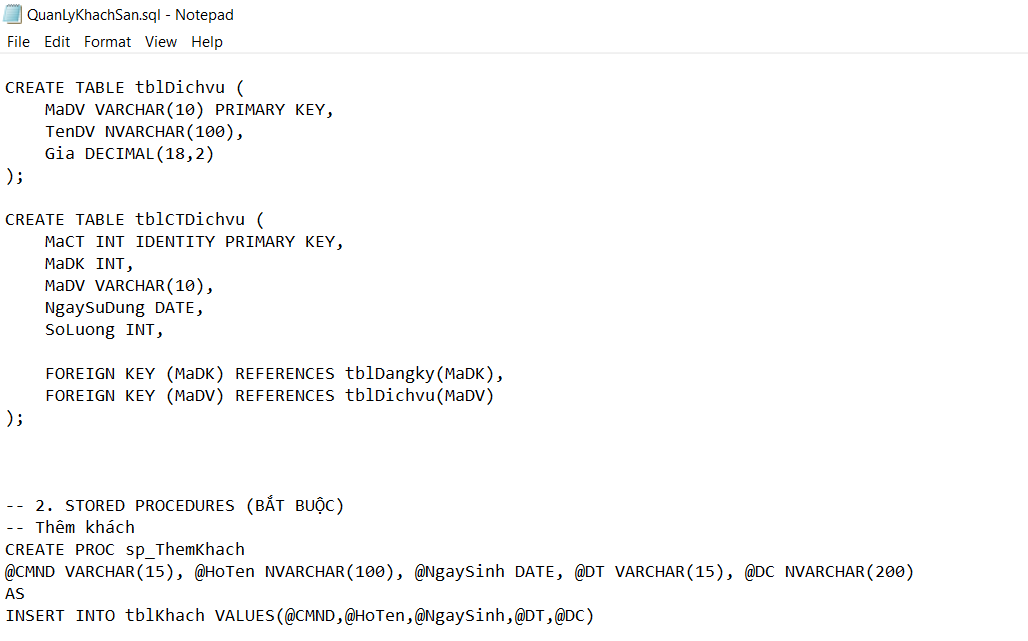

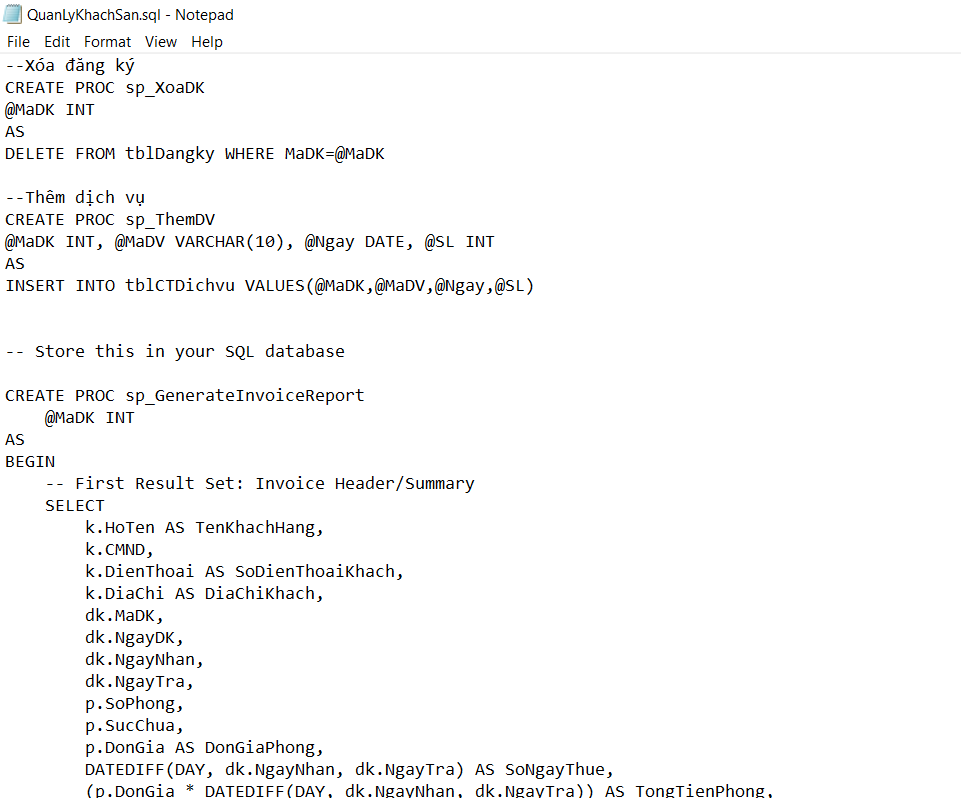

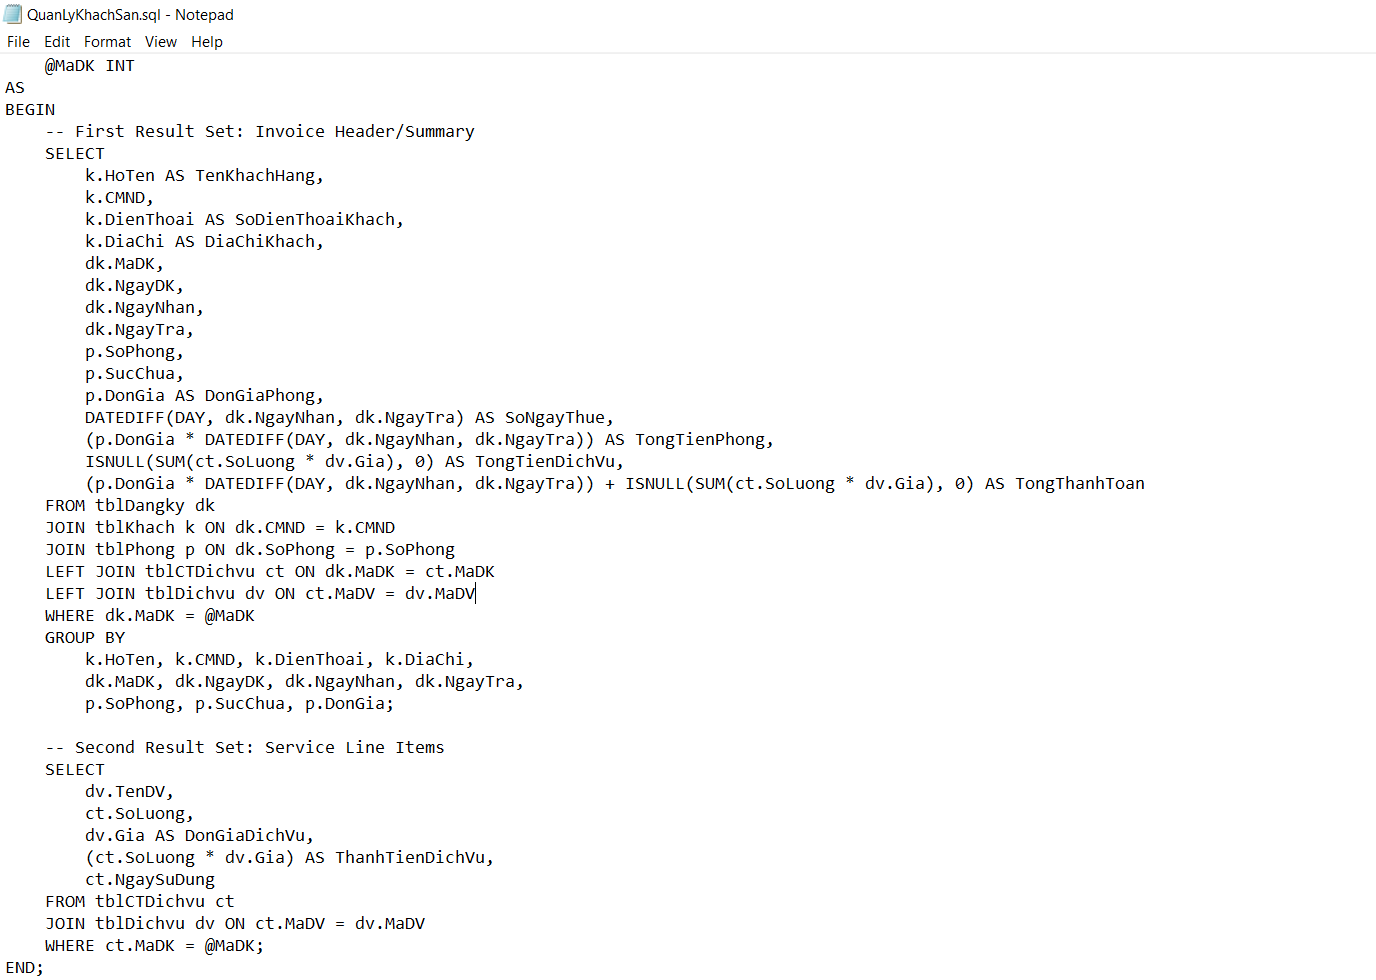

In [ ]:




CREATE DATABASE QLKhachSan
GO
USE QLKhachSan
GO

CREATE TABLE tblKhach (
    CMND VARCHAR(15) PRIMARY KEY,
    HoTen NVARCHAR(100),
    NgaySinh DATE,
    DienThoai VARCHAR(15),
    DiaChi NVARCHAR(200)
);

CREATE TABLE tblNhanvien (
    MaNV VARCHAR(10) PRIMARY KEY,
    HoTen NVARCHAR(100)
);

CREATE TABLE tblPhong (
    SoPhong VARCHAR(10) PRIMARY KEY,
    SucChua INT,
    DonGia DECIMAL(18,2),
    TinhTrang NVARCHAR(20)
);

CREATE TABLE tblDangky (
    MaDK INT IDENTITY PRIMARY KEY,
    CMND VARCHAR(15),
    MaNV VARCHAR(10),
    SoPhong VARCHAR(10),
    NgayDK DATE,
    NgayNhan DATE,
    NgayTra DATE,
    TrangThai NVARCHAR(20),

    FOREIGN KEY (CMND) REFERENCES tblKhach(CMND),
    FOREIGN KEY (MaNV) REFERENCES tblNhanvien(MaNV),
    FOREIGN KEY (SoPhong) REFERENCES tblPhong(SoPhong)
);

CREATE TABLE tblDichvu (
    MaDV VARCHAR(10) PRIMARY KEY,
    TenDV NVARCHAR(100),
    Gia DECIMAL(18,2)
);

CREATE TABLE tblCTDichvu (
    MaCT INT IDENTITY PRIMARY KEY,
    MaDK INT,
    MaDV VARCHAR(10),
    NgaySuDung DATE,
    SoLuong INT,

    FOREIGN KEY (MaDK) REFERENCES tblDangky(MaDK),
    FOREIGN KEY (MaDV) REFERENCES tblDichvu(MaDV)
);



-- 2. STORED PROCEDURES (BẮT BUỘC)
-- Thêm khách
CREATE PROC sp_ThemKhach
@CMND VARCHAR(15), @HoTen NVARCHAR(100), @NgaySinh DATE, @DT VARCHAR(15), @DC NVARCHAR(200)
AS
INSERT INTO tblKhach VALUES(@CMND,@HoTen,@NgaySinh,@DT,@DC)

-- Đặt phòng
CREATE PROC sp_DatPhong
@CMND VARCHAR(15), @MaNV VARCHAR(10), @SoPhong VARCHAR(10),
@NgayDK DATE, @NgayNhan DATE, @NgayTra DATE
AS
BEGIN
    INSERT INTO tblDangky VALUES
    (@CMND,@MaNV,@SoPhong,@NgayDK,@NgayNhan,@NgayTra,N'Đang thuê')

    UPDATE tblPhong SET TinhTrang=N'Đã thuê'
    WHERE SoPhong=@SoPhong
END

--Xóa đăng ký
CREATE PROC sp_XoaDK
@MaDK INT
AS
DELETE FROM tblDangky WHERE MaDK=@MaDK

--Thêm dịch vụ
CREATE PROC sp_ThemDV
@MaDK INT, @MaDV VARCHAR(10), @Ngay DATE, @SL INT
AS
INSERT INTO tblCTDichvu VALUES(@MaDK,@MaDV,@Ngay,@SL)


-- Store this in your SQL database

CREATE PROC sp_GenerateInvoiceReport
    @MaDK INT
AS
BEGIN
    -- First Result Set: Invoice Header/Summary
    SELECT
        k.HoTen AS TenKhachHang,
        k.CMND,
        k.DienThoai AS SoDienThoaiKhach,
        k.DiaChi AS DiaChiKhach,
        dk.MaDK,
        dk.NgayDK,
        dk.NgayNhan,
        dk.NgayTra,
        p.SoPhong,
        p.SucChua,
        p.DonGia AS DonGiaPhong,
        DATEDIFF(DAY, dk.NgayNhan, dk.NgayTra) AS SoNgayThue,
        (p.DonGia * DATEDIFF(DAY, dk.NgayNhan, dk.NgayTra)) AS TongTienPhong,
        ISNULL(SUM(ct.SoLuong * dv.Gia), 0) AS TongTienDichVu,
        (p.DonGia * DATEDIFF(DAY, dk.NgayNhan, dk.NgayTra)) + ISNULL(SUM(ct.SoLuong * dv.Gia), 0) AS TongThanhToan
    FROM tblDangky dk
    JOIN tblKhach k ON dk.CMND = k.CMND
    JOIN tblPhong p ON dk.SoPhong = p.SoPhong
    LEFT JOIN tblCTDichvu ct ON dk.MaDK = ct.MaDK
    LEFT JOIN tblDichvu dv ON ct.MaDV = dv.MaDV
    WHERE dk.MaDK = @MaDK
    GROUP BY
        k.HoTen, k.CMND, k.DienThoai, k.DiaChi,
        dk.MaDK, dk.NgayDK, dk.NgayNhan, dk.NgayTra,
        p.SoPhong, p.SucChua, p.DonGia;

    -- Second Result Set: Service Line Items
    SELECT
        dv.TenDV,
        ct.SoLuong,
        dv.Gia AS DonGiaDichVu,
        (ct.SoLuong * dv.Gia) AS ThanhTienDichVu,
        ct.NgaySuDung
    FROM tblCTDichvu ct
    JOIN tblDichvu dv ON ct.MaDV = dv.MaDV
    WHERE ct.MaDK = @MaDK;
END;

TERMINAL

COMMAND PROMPT

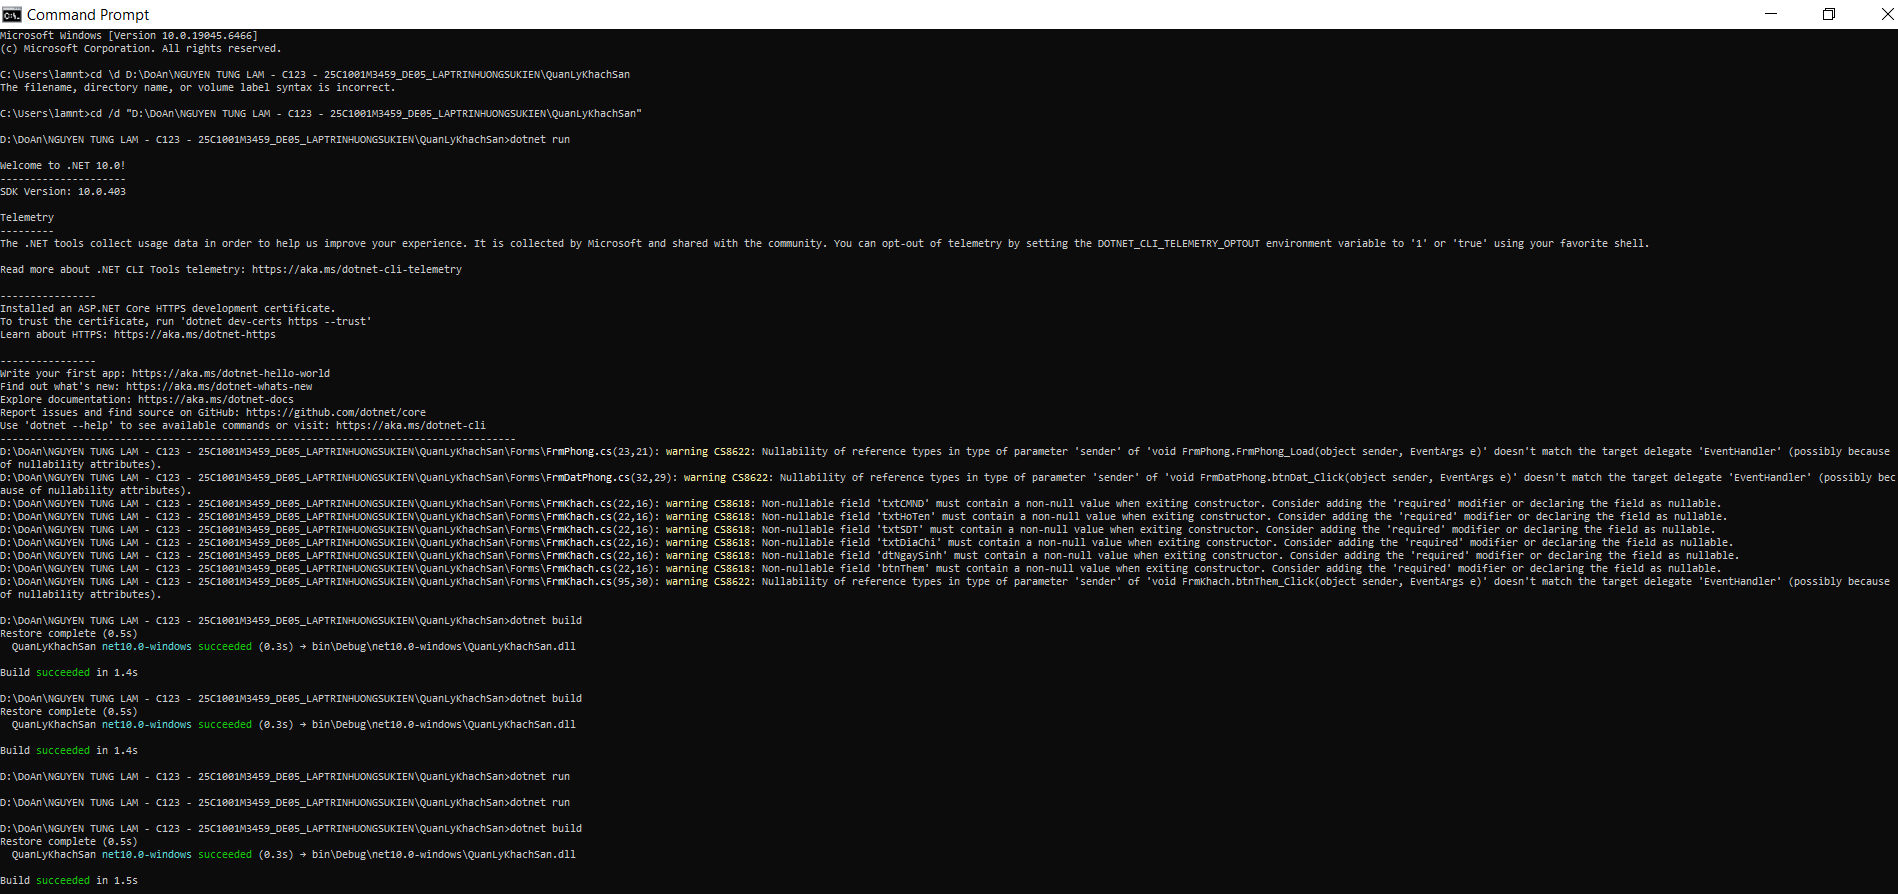

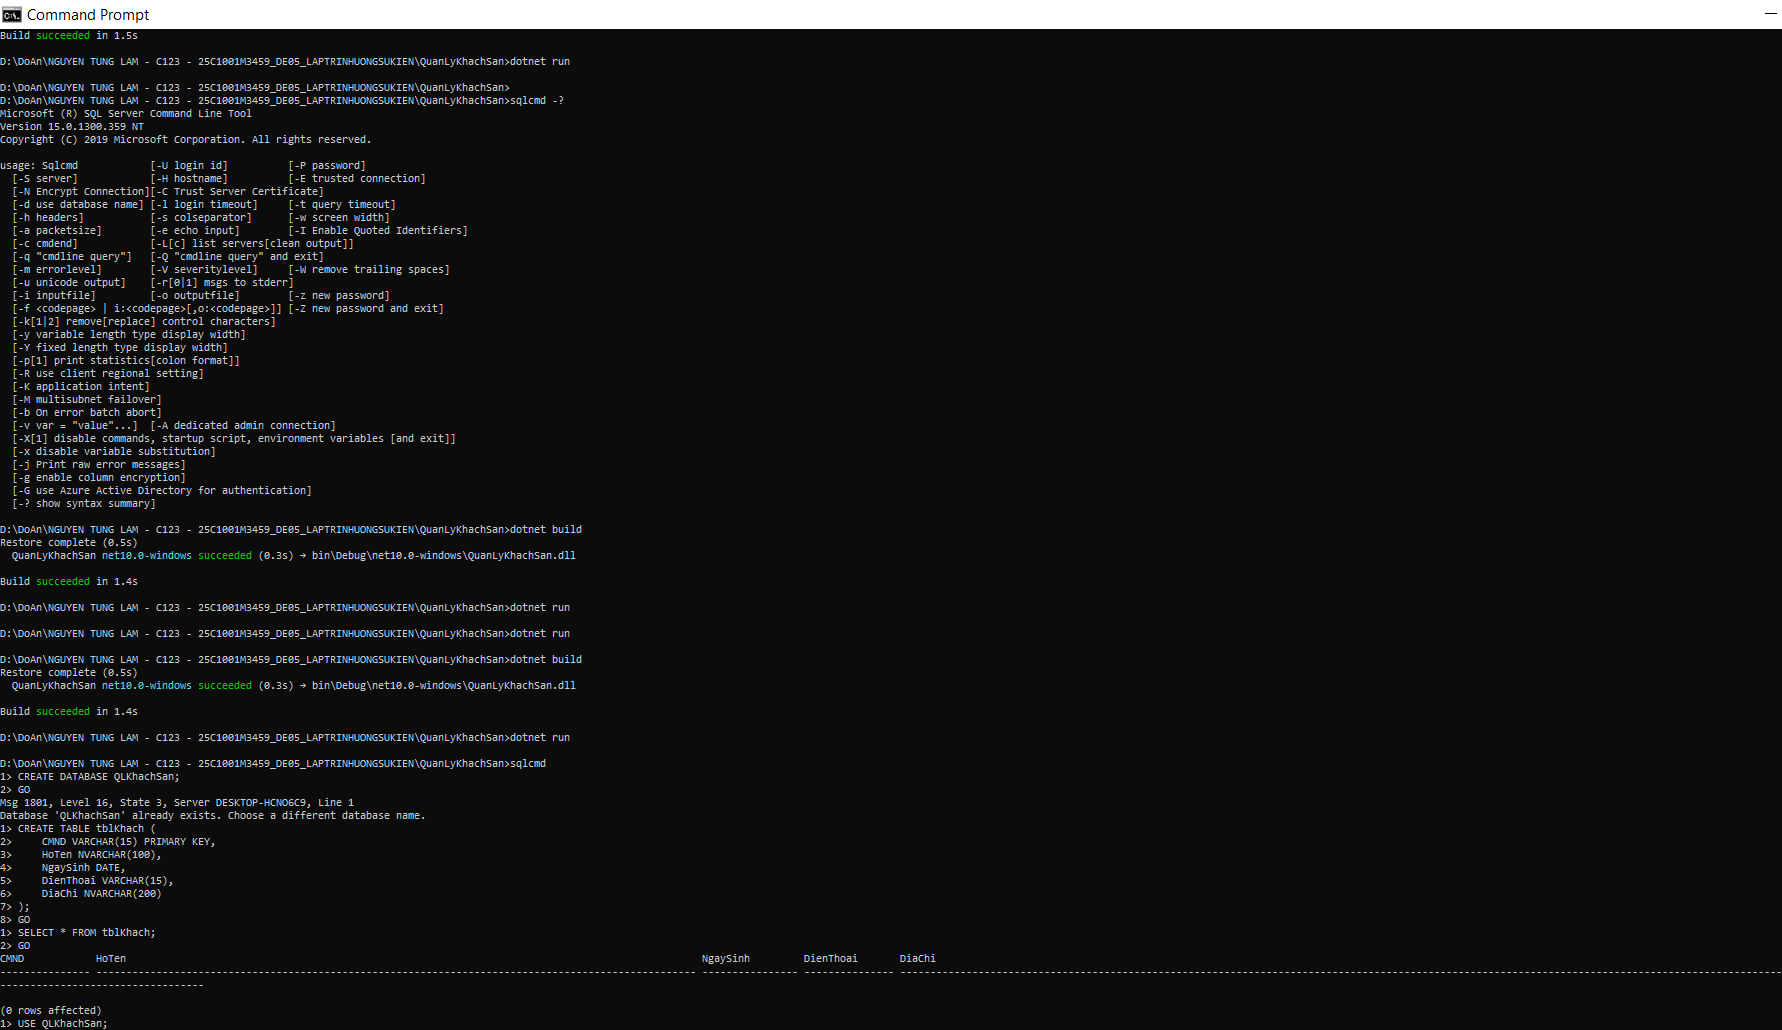

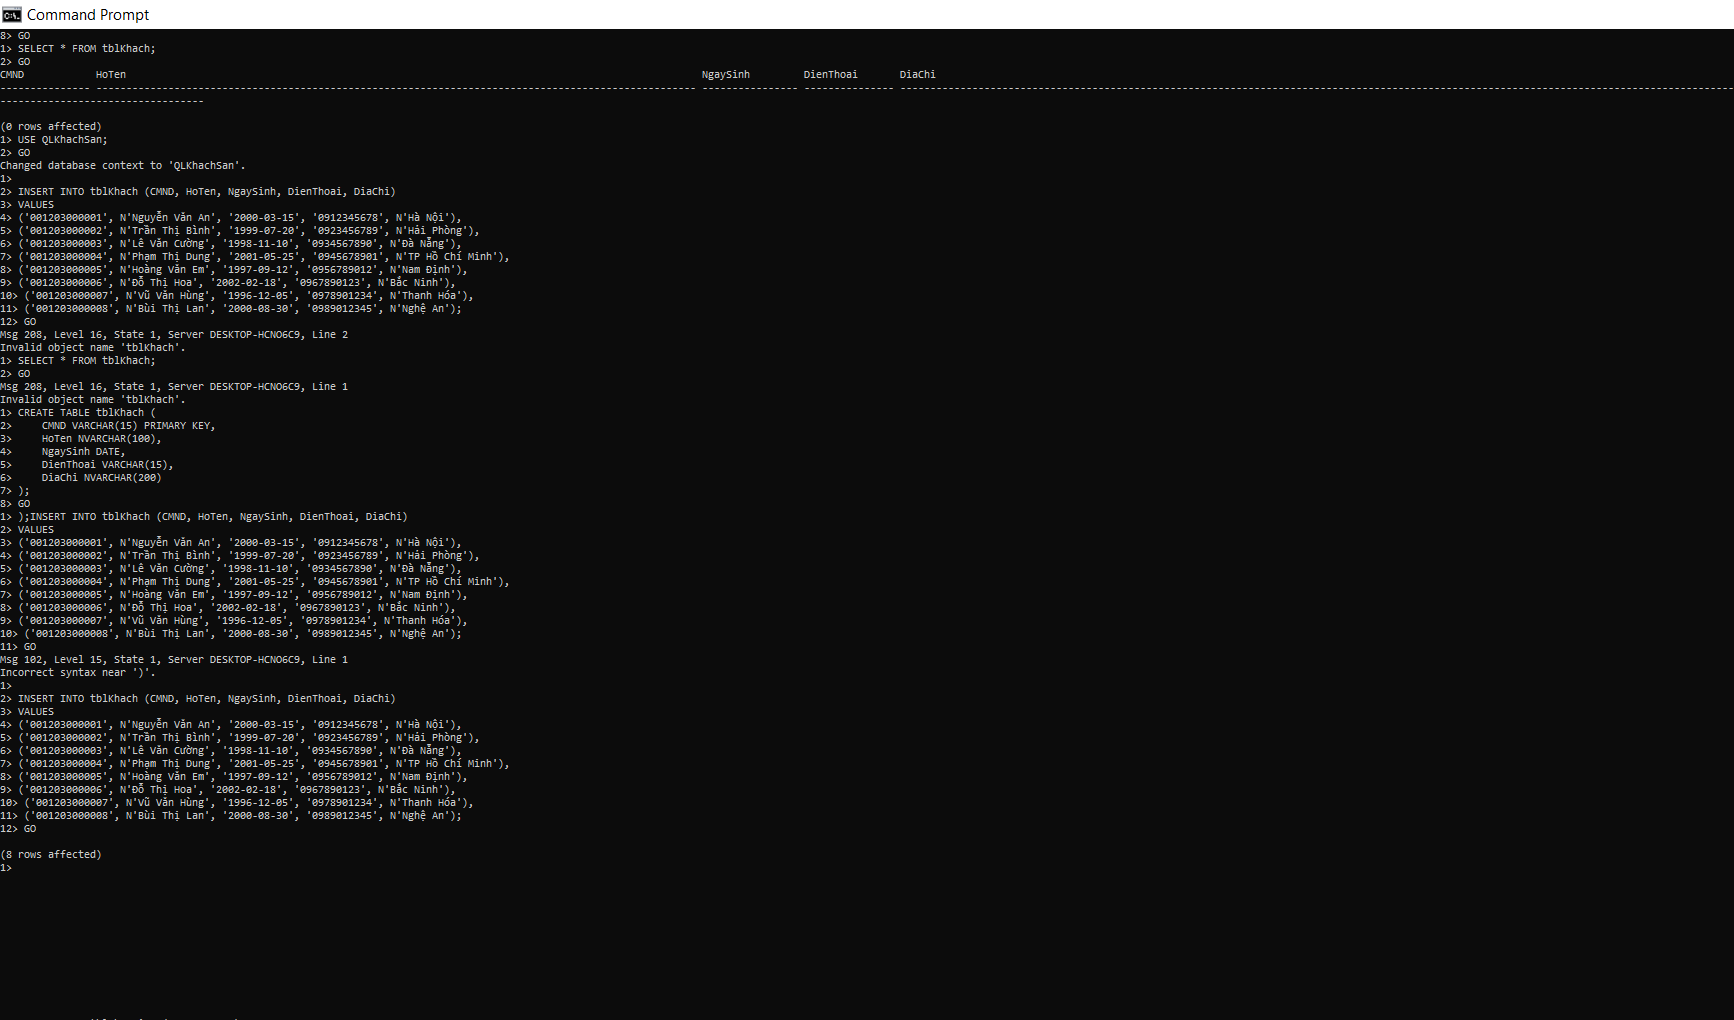

In [ ]:
Microsoft Windows [Version 10.0.19045.6466]
(c) Microsoft Corporation. All rights reserved.

C:\Users\lamnt>cd \d D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan
The filename, directory name, or volume label syntax is incorrect.

C:\Users\lamnt>cd /d "D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan"

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet run

Welcome to .NET 10.0!
---------------------
SDK Version: 10.0.403

Telemetry
---------
The .NET tools collect usage data in order to help us improve your experience. It is collected by Microsoft and shared with the community. You can opt-out of telemetry by setting the DOTNET_CLI_TELEMETRY_OPTOUT environment variable to '1' or 'true' using your favorite shell.

Read more about .NET CLI Tools telemetry: https://aka.ms/dotnet-cli-telemetry

----------------
Installed an ASP.NET Core HTTPS development certificate.
To trust the certificate, run 'dotnet dev-certs https --trust'
Learn about HTTPS: https://aka.ms/dotnet-https

----------------
Write your first app: https://aka.ms/dotnet-hello-world
Find out what's new: https://aka.ms/dotnet-whats-new
Explore documentation: https://aka.ms/dotnet-docs
Report issues and find source on GitHub: https://github.com/dotnet/core
Use 'dotnet --help' to see available commands or visit: https://aka.ms/dotnet-cli
--------------------------------------------------------------------------------------
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\Forms\FrmPhong.cs(23,21): warning CS8622: Nullability of reference types in type of parameter 'sender' of 'void FrmPhong.FrmPhong_Load(object sender, EventArgs e)' doesn't match the target delegate 'EventHandler' (possibly because of nullability attributes).
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\Forms\FrmDatPhong.cs(32,29): warning CS8622: Nullability of reference types in type of parameter 'sender' of 'void FrmDatPhong.btnDat_Click(object sender, EventArgs e)' doesn't match the target delegate 'EventHandler' (possibly because of nullability attributes).
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\Forms\FrmKhach.cs(22,16): warning CS8618: Non-nullable field 'txtCMND' must contain a non-null value when exiting constructor. Consider adding the 'required' modifier or declaring the field as nullable.
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\Forms\FrmKhach.cs(22,16): warning CS8618: Non-nullable field 'txtHoTen' must contain a non-null value when exiting constructor. Consider adding the 'required' modifier or declaring the field as nullable.
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\Forms\FrmKhach.cs(22,16): warning CS8618: Non-nullable field 'txtSDT' must contain a non-null value when exiting constructor. Consider adding the 'required' modifier or declaring the field as nullable.
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\Forms\FrmKhach.cs(22,16): warning CS8618: Non-nullable field 'txtDiaChi' must contain a non-null value when exiting constructor. Consider adding the 'required' modifier or declaring the field as nullable.
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\Forms\FrmKhach.cs(22,16): warning CS8618: Non-nullable field 'dtNgaySinh' must contain a non-null value when exiting constructor. Consider adding the 'required' modifier or declaring the field as nullable.
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\Forms\FrmKhach.cs(22,16): warning CS8618: Non-nullable field 'btnThem' must contain a non-null value when exiting constructor. Consider adding the 'required' modifier or declaring the field as nullable.
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\Forms\FrmKhach.cs(95,30): warning CS8622: Nullability of reference types in type of parameter 'sender' of 'void FrmKhach.btnThem_Click(object sender, EventArgs e)' doesn't match the target delegate 'EventHandler' (possibly because of nullability attributes).

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet build
Restore complete (0.5s)
  QuanLyKhachSan net10.0-windows succeeded (0.3s) → bin\Debug\net10.0-windows\QuanLyKhachSan.dll

Build succeeded in 1.4s

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet build
Restore complete (0.5s)
  QuanLyKhachSan net10.0-windows succeeded (0.3s) → bin\Debug\net10.0-windows\QuanLyKhachSan.dll

Build succeeded in 1.4s

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet run

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet run

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet build
Restore complete (0.5s)
  QuanLyKhachSan net10.0-windows succeeded (0.3s) → bin\Debug\net10.0-windows\QuanLyKhachSan.dll

Build succeeded in 1.5s

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet run

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>sqlcmd -?
Microsoft (R) SQL Server Command Line Tool
Version 15.0.1300.359 NT
Copyright (C) 2019 Microsoft Corporation. All rights reserved.

usage: Sqlcmd            [-U login id]          [-P password]
  [-S server]            [-H hostname]          [-E trusted connection]
  [-N Encrypt Connection][-C Trust Server Certificate]
  [-d use database name] [-l login timeout]     [-t query timeout]
  [-h headers]           [-s colseparator]      [-w screen width]
  [-a packetsize]        [-e echo input]        [-I Enable Quoted Identifiers]
  [-c cmdend]            [-L[c] list servers[clean output]]
  [-q "cmdline query"]   [-Q "cmdline query" and exit]
  [-m errorlevel]        [-V severitylevel]     [-W remove trailing spaces]
  [-u unicode output]    [-r[0|1] msgs to stderr]
  [-i inputfile]         [-o outputfile]        [-z new password]
  [-f <codepage> | i:<codepage>[,o:<codepage>]] [-Z new password and exit]
  [-k[1|2] remove[replace] control characters]
  [-y variable length type display width]
  [-Y fixed length type display width]
  [-p[1] print statistics[colon format]]
  [-R use client regional setting]
  [-K application intent]
  [-M multisubnet failover]
  [-b On error batch abort]
  [-v var = "value"...]  [-A dedicated admin connection]
  [-X[1] disable commands, startup script, environment variables [and exit]]
  [-x disable variable substitution]
  [-j Print raw error messages]
  [-g enable column encryption]
  [-G use Azure Active Directory for authentication]
  [-? show syntax summary]

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet build
Restore complete (0.5s)
  QuanLyKhachSan net10.0-windows succeeded (0.3s) → bin\Debug\net10.0-windows\QuanLyKhachSan.dll

Build succeeded in 1.4s

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet run

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet run

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet build
Restore complete (0.5s)
  QuanLyKhachSan net10.0-windows succeeded (0.3s) → bin\Debug\net10.0-windows\QuanLyKhachSan.dll

Build succeeded in 1.4s

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet run

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>sqlcmd
1> CREATE DATABASE QLKhachSan;
2> GO
Msg 1801, Level 16, State 3, Server DESKTOP-HCNO6C9, Line 1
Database 'QLKhachSan' already exists. Choose a different database name.
1> CREATE TABLE tblKhach (
2>     CMND VARCHAR(15) PRIMARY KEY,
3>     HoTen NVARCHAR(100),
4>     NgaySinh DATE,
5>     DienThoai VARCHAR(15),
6>     DiaChi NVARCHAR(200)
7> );
8> GO
1> SELECT * FROM tblKhach;
2> GO
CMND            HoTen                                                                                                NgaySinh         DienThoai       DiaChi
--------------- ---------------------------------------------------------------------------------------------------- ---------------- --------------- --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

(0 rows affected)
1> USE QLKhachSan;
2> GO
Changed database context to 'QLKhachSan'.
1>
2> INSERT INTO tblKhach (CMND, HoTen, NgaySinh, DienThoai, DiaChi)
3> VALUES
4> ('001203000001', N'Nguyễn Văn An', '2000-03-15', '0912345678', N'Hà Nội'),
5> ('001203000002', N'Trần Thị Bình', '1999-07-20', '0923456789', N'Hải Phòng'),
6> ('001203000003', N'Lê Văn Cường', '1998-11-10', '0934567890', N'Đà Nẵng'),
7> ('001203000004', N'Phạm Thị Dung', '2001-05-25', '0945678901', N'TP Hồ Chí Minh'),
8> ('001203000005', N'Hoàng Văn Em', '1997-09-12', '0956789012', N'Nam Định'),
9> ('001203000006', N'Đỗ Thị Hoa', '2002-02-18', '0967890123', N'Bắc Ninh'),
10> ('001203000007', N'Vũ Văn Hùng', '1996-12-05', '0978901234', N'Thanh Hóa'),
11> ('001203000008', N'Bùi Thị Lan', '2000-08-30', '0989012345', N'Nghệ An');
12> GO
Msg 208, Level 16, State 1, Server DESKTOP-HCNO6C9, Line 2
Invalid object name 'tblKhach'.
1> SELECT * FROM tblKhach;
2> GO
Msg 208, Level 16, State 1, Server DESKTOP-HCNO6C9, Line 1
Invalid object name 'tblKhach'.
1> CREATE TABLE tblKhach (
2>     CMND VARCHAR(15) PRIMARY KEY,
3>     HoTen NVARCHAR(100),
4>     NgaySinh DATE,
5>     DienThoai VARCHAR(15),
6>     DiaChi NVARCHAR(200)
7> );
8> GO
1> );INSERT INTO tblKhach (CMND, HoTen, NgaySinh, DienThoai, DiaChi)
2> VALUES
3> ('001203000001', N'Nguyễn Văn An', '2000-03-15', '0912345678', N'Hà Nội'),
4> ('001203000002', N'Trần Thị Bình', '1999-07-20', '0923456789', N'Hải Phòng'),
5> ('001203000003', N'Lê Văn Cường', '1998-11-10', '0934567890', N'Đà Nẵng'),
6> ('001203000004', N'Phạm Thị Dung', '2001-05-25', '0945678901', N'TP Hồ Chí Minh'),
7> ('001203000005', N'Hoàng Văn Em', '1997-09-12', '0956789012', N'Nam Định'),
8> ('001203000006', N'Đỗ Thị Hoa', '2002-02-18', '0967890123', N'Bắc Ninh'),
9> ('001203000007', N'Vũ Văn Hùng', '1996-12-05', '0978901234', N'Thanh Hóa'),
10> ('001203000008', N'Bùi Thị Lan', '2000-08-30', '0989012345', N'Nghệ An');
11> GO
Msg 102, Level 15, State 1, Server DESKTOP-HCNO6C9, Line 1
Incorrect syntax near ')'.
1>
2> INSERT INTO tblKhach (CMND, HoTen, NgaySinh, DienThoai, DiaChi)
3> VALUES
4> ('001203000001', N'Nguyễn Văn An', '2000-03-15', '0912345678', N'Hà Nội'),
5> ('001203000002', N'Trần Thị Bình', '1999-07-20', '0923456789', N'Hải Phòng'),
6> ('001203000003', N'Lê Văn Cường', '1998-11-10', '0934567890', N'Đà Nẵng'),
7> ('001203000004', N'Phạm Thị Dung', '2001-05-25', '0945678901', N'TP Hồ Chí Minh'),
8> ('001203000005', N'Hoàng Văn Em', '1997-09-12', '0956789012', N'Nam Định'),
9> ('001203000006', N'Đỗ Thị Hoa', '2002-02-18', '0967890123', N'Bắc Ninh'),
10> ('001203000007', N'Vũ Văn Hùng', '1996-12-05', '0978901234', N'Thanh Hóa'),
11> ('001203000008', N'Bùi Thị Lan', '2000-08-30', '0989012345', N'Nghệ An');
12> GO


ARCHITECTURE

In [ ]:
              INPUT
                |
                v
       +------------------+
       |     FRONT END    |
       |  C# - Visual     |
       |     Studio       |
       +------------------+
                |
                |
                v
     +------------------------+
     |                        |
     |     COMMAND PROMPT     |
     |         (CMD)           |
     |                        |
     |   Central Interface    |
     |                        |
     +------------------------+
                |
                |
                v
       +------------------+
       |     BACK END     |
       | SQL SERVER +     |
       |      SSMS        |
       +------------------+
                |
                v
              OUTPUT
                |
                v
       +------------------+
       |     QuestPDF     |
       |  Generate/Print  |
       |     Invoice      |
       +------------------+

PROJECT STRUCTURE

In [ ]:
.2 . Project Structure

QuanLyKhachSan
│
├── QuanLyKhachSan.csproj
├── Program.cs
│
├── Database
│   └── DB.cs
│
├── Models
│   ├── KhachHang.cs
│   ├── Phong.cs
│   └── DatPhong.cs
│
├── Forms
│   ├── FrmMain.cs
│   ├── FrmKhach.cs
│   ├── FrmPhong.cs
│   ├── FrmDatPhong.cs
│   └── FrmHoaDon.cs
│
└── SQL
    └── QLKhachSan.sql


REPORT - USING DOT NET QUESTPDF

In [ ]:
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet add package QuestPDF
info : X.509 certificate chain validation will use the default trust store selected by .NET for code signing.
info : X.509 certificate chain validation will use the default trust store selected by .NET for timestamping.
info : Adding PackageReference for package 'QuestPDF' into project 'D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\QuanLyKhachSan.csproj'.
info :   GET https://api.nuget.org/v3/registration5-gz-semver2/questpdf/index.json
info :   OK https://api.nuget.org/v3/registration5-gz-semver2/questpdf/index.json 586ms
info :   GET https://api.nuget.org/v3/registration5-gz-semver2/questpdf/page/2020.11.0/2022.8.2.json
info :   OK https://api.nuget.org/v3/registration5-gz-semver2/questpdf/page/2020.11.0/2022.8.2.json 684ms
info :   GET https://api.nuget.org/v3/registration5-gz-semver2/questpdf/page/2022.9.0-alpha1/2024.6.0.json
info :   OK https://api.nuget.org/v3/registration5-gz-semver2/questpdf/page/2022.9.0-alpha1/2024.6.0.json 671ms
info :   GET https://api.nuget.org/v3/registration5-gz-semver2/questpdf/page/2024.6.1/2026.2.1.json
info :   OK https://api.nuget.org/v3/registration5-gz-semver2/questpdf/page/2024.6.1/2026.2.1.json 648ms
info :   GET https://api.nuget.org/v3/registration5-gz-semver2/questpdf/page/2026.2.2/2026.9.1.json
info :   OK https://api.nuget.org/v3/registration5-gz-semver2/questpdf/page/2026.2.2/2026.9.1.json 617ms
info : Restoring packages for D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\QuanLyKhachSan.csproj...
info :   GET https://api.nuget.org/v3/vulnerabilities/index.json
info :   OK https://api.nuget.org/v3/vulnerabilities/index.json 300ms
info :   GET https://api.nuget.org/v3-vulnerabilities/2026.10.28.05.41.06/vulnerability.base.json
info :   GET https://api.nuget.org/v3-vulnerabilities/2026.10.28.05.41.06/2026.11.01.05.41.42/vulnerability.update.json
info :   OK https://api.nuget.org/v3-vulnerabilities/2026.10.28.05.41.06/vulnerability.base.json 251ms
info :   OK https://api.nuget.org/v3-vulnerabilities/2026.10.28.05.41.06/2026.11.01.05.41.42/vulnerability.update.json 283ms
info : Package 'QuestPDF' is compatible with all the specified frameworks in project 'D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\QuanLyKhachSan.csproj'.
info : PackageReference for package 'QuestPDF' version '2026.9.1' updated in file 'D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\QuanLyKhachSan.csproj'.
info : Assets file has not changed. Skipping assets file writing. Path: D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\obj\project.assets.json
log  : Restored D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan\QuanLyKhachSan.csproj (in 1.02 sec).


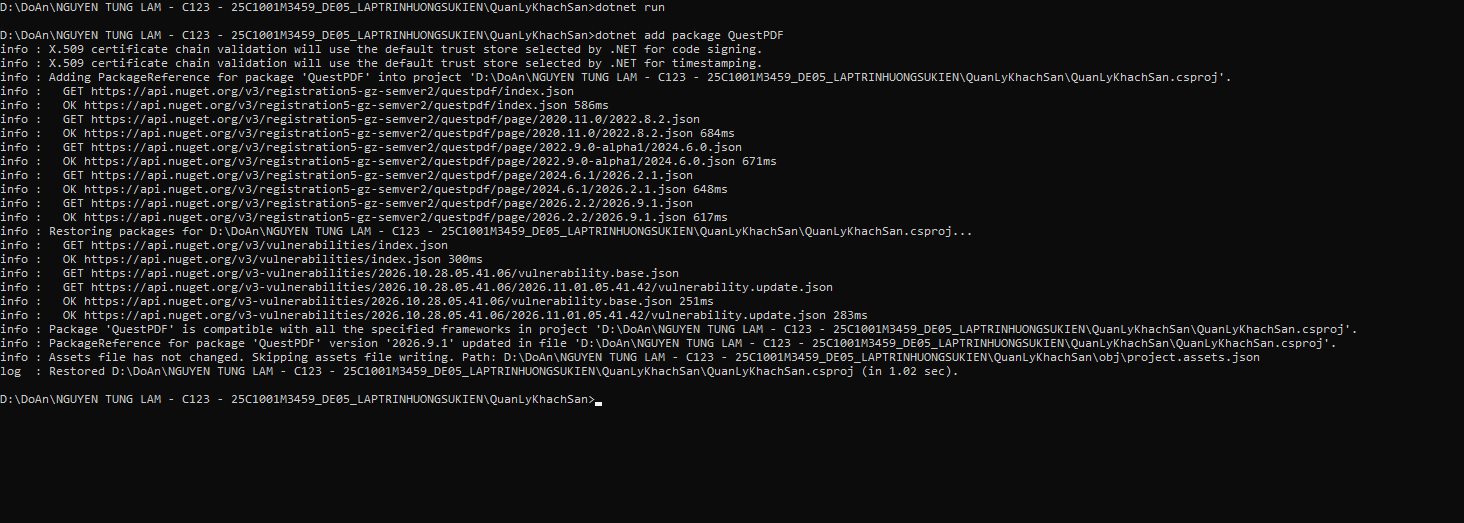

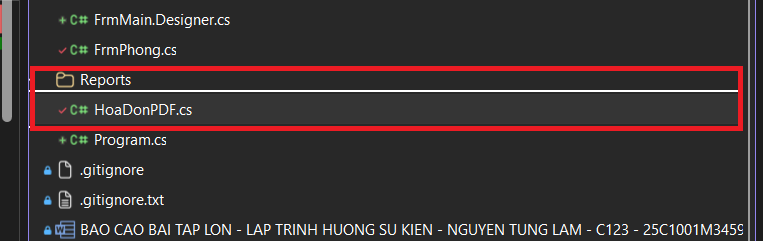

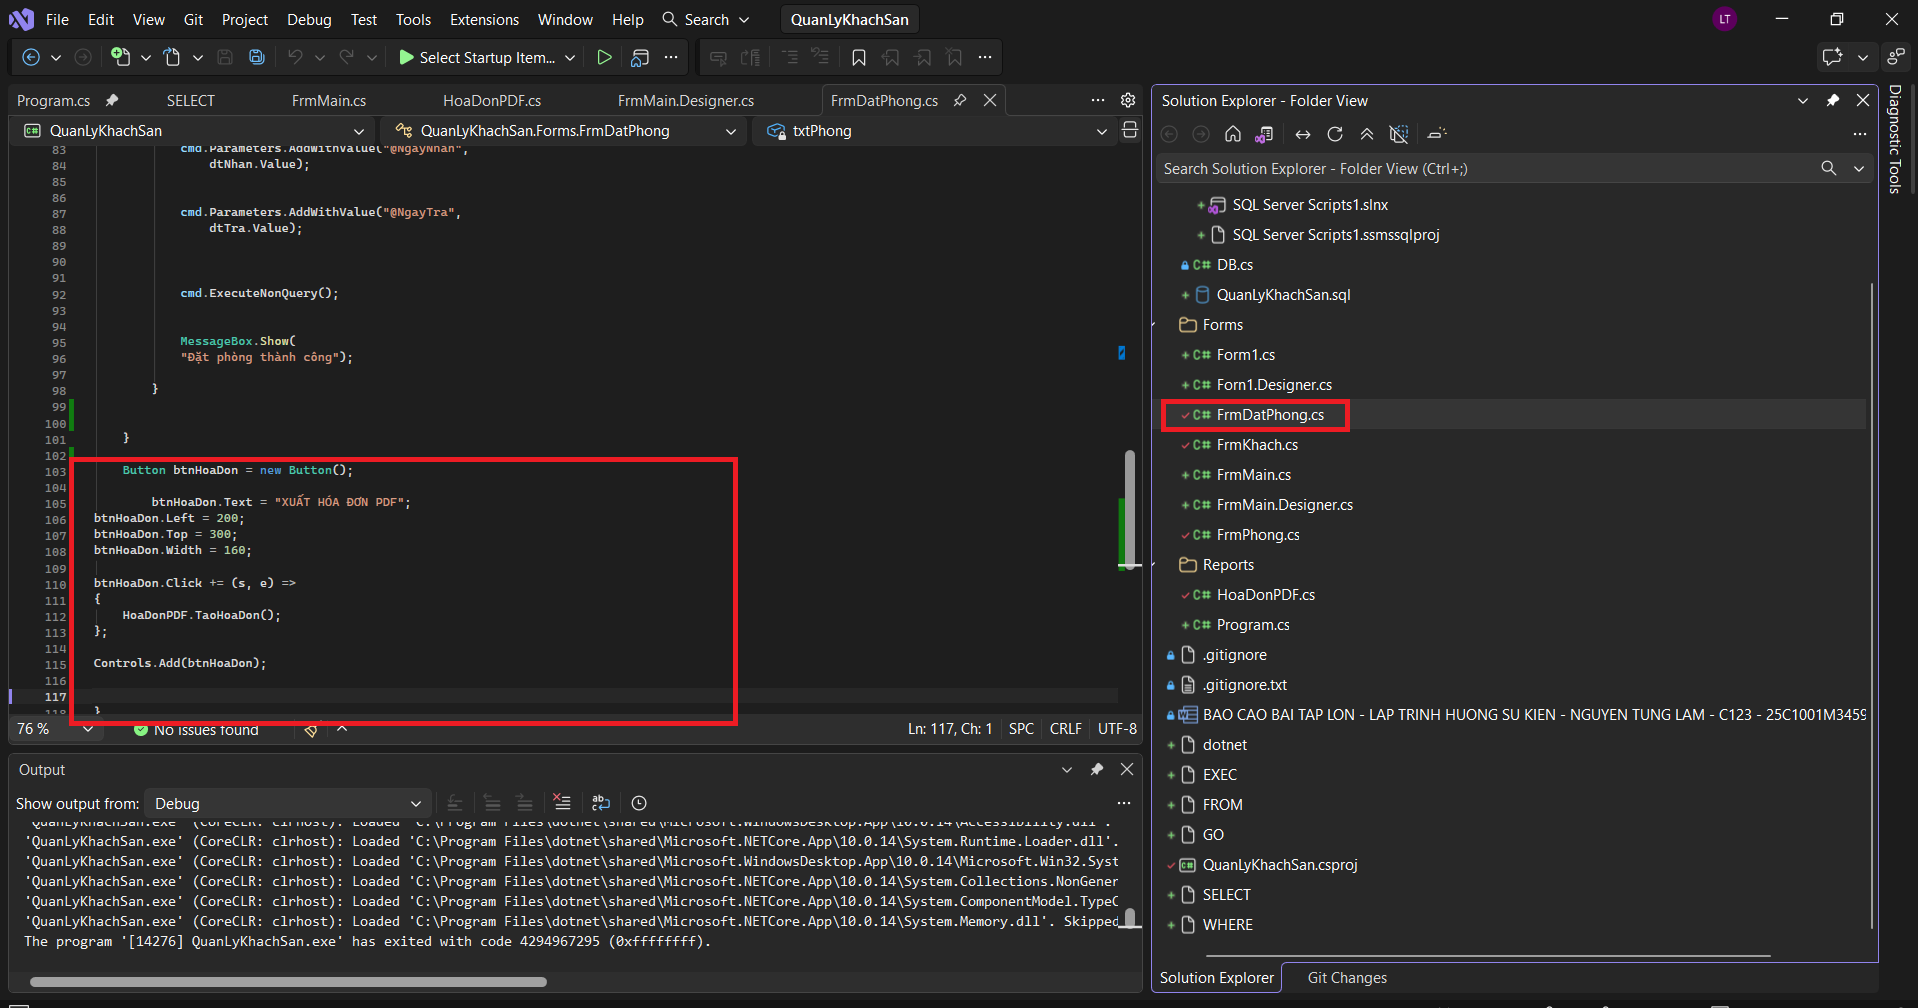

In [ ]:

using System;
using System.Windows.Forms;
using Microsoft.Data.SqlClient;
using QuanLyKhachSan.Database;
using QuanLyKhachSan.Reports;

namespace QuanLyKhachSan;

public class FrmDatPhong : Form
{
    TextBox txtCMND = new();
    TextBox txtPhong = new();
    TextBox txtMaNV = new();

    DateTimePicker dtNhan = new();
    DateTimePicker dtTra = new();

    Button btnDat = new();
    Button btnHoaDon = new();

    public FrmDatPhong()
    {
        CreateForm();
    }

    void CreateForm()
    {
        Text = "QUẢN LÝ ĐẶT PHÒNG";
        Width = 500;
        Height = 450;
        StartPosition = FormStartPosition.CenterScreen;

        Label lblCMND = new()
        {
            Text = "CMND khách hàng:",
            Left = 30,
            Top = 40,
            Width = 130
        };

        txtCMND.SetBounds(180, 40, 200, 25);

        Label lblPhong = new()
        {
            Text = "Số phòng:",
            Left = 30,
            Top = 90,
            Width = 130
        };

        txtPhong.SetBounds(180, 90, 200, 25);

        Label lblMaNV = new()
        {
            Text = "Mã nhân viên:",
            Left = 30,
            Top = 140,
            Width = 130
        };

        txtMaNV.SetBounds(180, 140, 200, 25);

        Label lblNhan = new()
        {
            Text = "Ngày nhận:",
            Left = 30,
            Top = 190,
            Width = 130
        };

        dtNhan.SetBounds(180, 190, 200, 25);

        Label lblTra = new()
        {
            Text = "Ngày trả:",
            Left = 30,
            Top = 240,
            Width = 130
        };

        dtTra.SetBounds(180, 240, 200, 25);

        btnDat.Text = "ĐẶT PHÒNG";
        btnDat.SetBounds(70, 310, 140, 40);
        btnDat.Click += btnDat_Click;

        btnHoaDon.Text = "XUẤT HÓA ĐƠN PDF";
        btnHoaDon.SetBounds(240, 310, 180, 40);
        btnHoaDon.Click += btnHoaDon_Click;

        Controls.AddRange(new Control[]
        {
            lblCMND, txtCMND,
            lblPhong, txtPhong,
            lblMaNV, txtMaNV,
            lblNhan, dtNhan,
            lblTra, dtTra,
            btnDat, btnHoaDon
        });
    }

    // Đặt phòng
    private void btnDat_Click(object? sender, EventArgs e)
    {
        try
        {
            using SqlConnection conn = DB.GetConnection();
            conn.Open();

            using SqlCommand cmd =
                new("sp_DatPhong", conn);

            cmd.CommandType =
                System.Data.CommandType.StoredProcedure;

            cmd.Parameters.AddWithValue("@CMND", txtCMND.Text);
            cmd.Parameters.AddWithValue("@SoPhong", txtPhong.Text);
            cmd.Parameters.AddWithValue("@MaNV", txtMaNV.Text);
            cmd.Parameters.AddWithValue("@NgayDK", DateTime.Now);
            cmd.Parameters.AddWithValue("@NgayNhan", dtNhan.Value);
            cmd.Parameters.AddWithValue("@NgayTra", dtTra.Value);

            cmd.ExecuteNonQuery();

            MessageBox.Show("Đặt phòng thành công!");
        }
        catch (Exception ex)
        {
            MessageBox.Show(ex.Message, "Lỗi đặt phòng");
        }
    }

    // Xuất PDF
    private void btnHoaDon_Click(object? sender, EventArgs e)
    {
        try
        {
            HoaDonPDF.TaoHoaDon();
        }
        catch (Exception ex)
        {
            MessageBox.Show(ex.Message, "Lỗi xuất PDF");
        }
    }
}


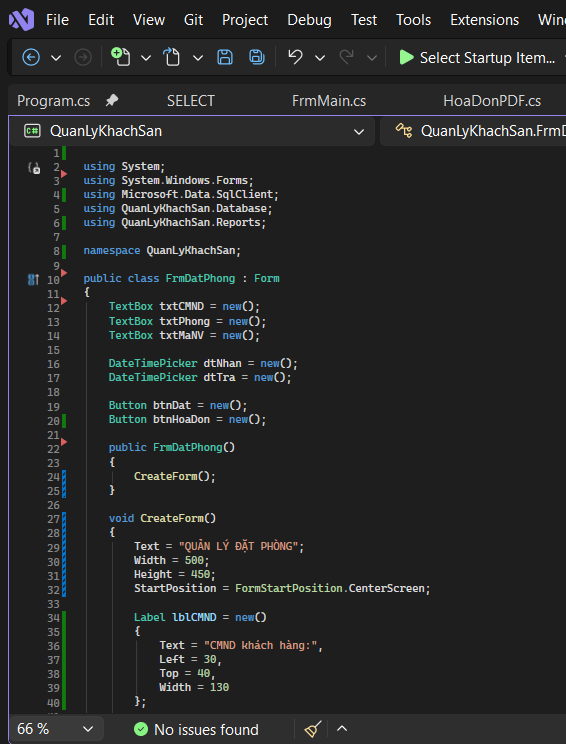

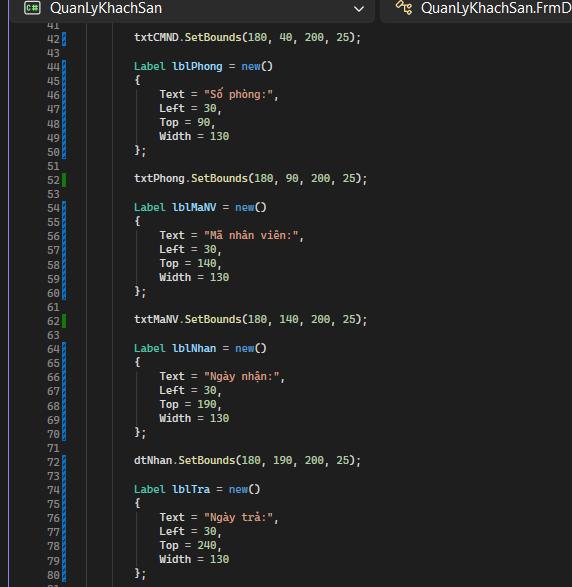

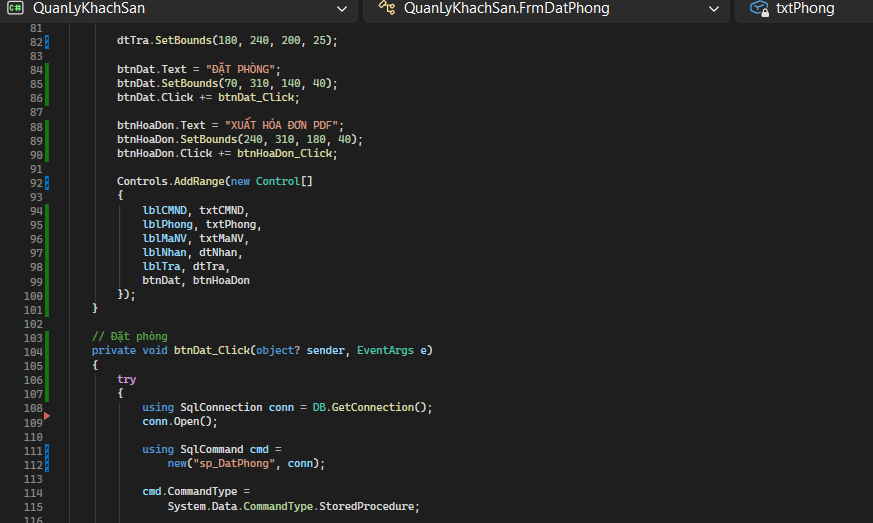

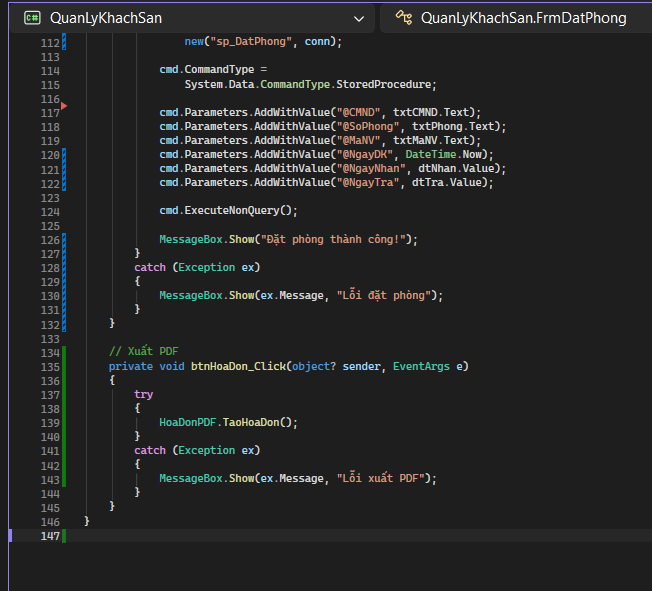

Fix lai form main

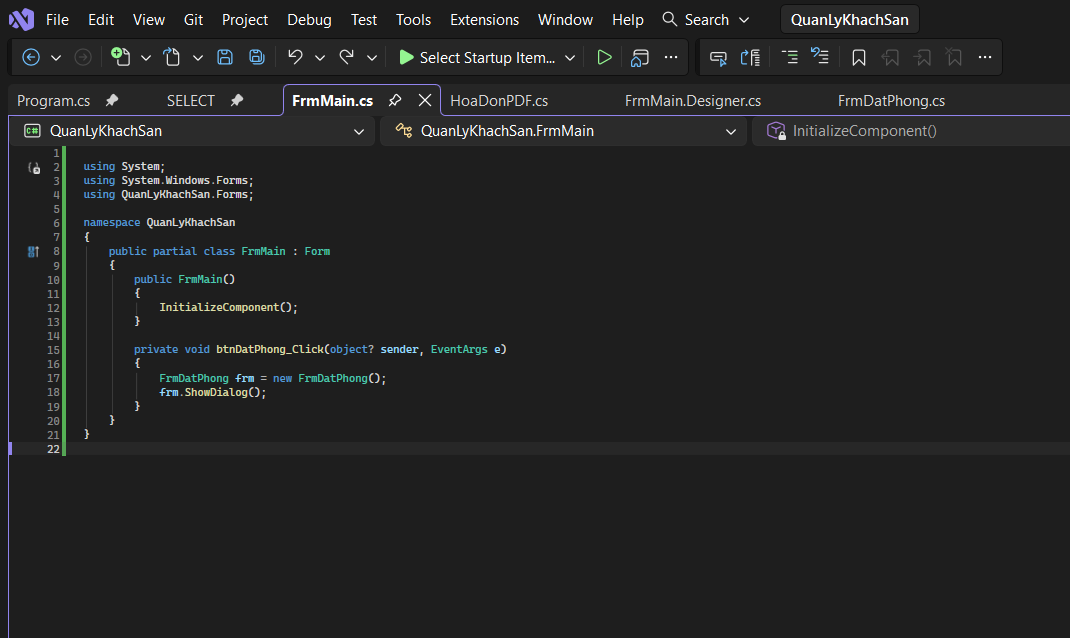

In [ ]:

using System;
using System.Windows.Forms;
using QuanLyKhachSan.Forms;

namespace QuanLyKhachSan
{
    public partial class FrmMain : Form
    {
        public FrmMain()
        {
            InitializeComponent();
        }

        private void btnDatPhong_Click(object? sender, EventArgs e)
        {
            FrmDatPhong frm = new FrmDatPhong();
            frm.ShowDialog();
        }
    }
}


Fix lai Program.cs cho FrmDatPhong

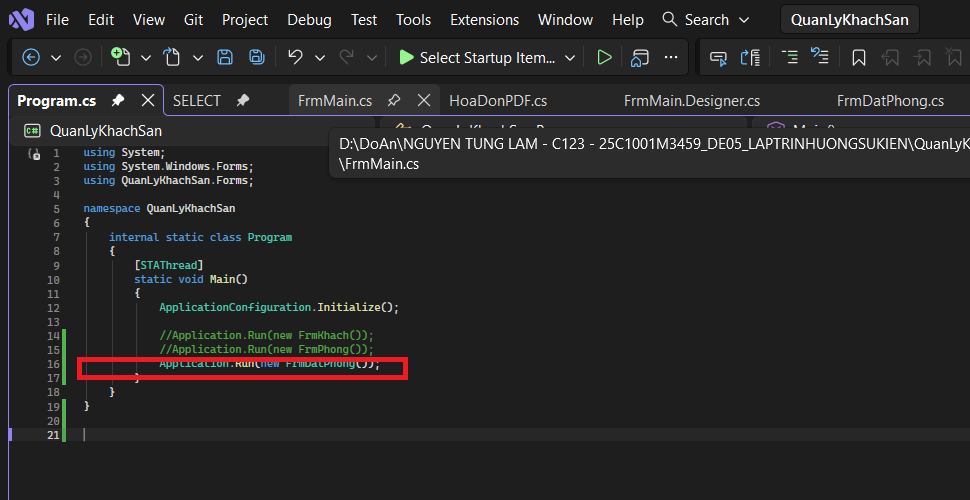

In [ ]:
using System;
using System.Windows.Forms;

namespace QuanLyKhachSan;

internal static class Program
{
    [STAThread]
    static void Main()
    {
        ApplicationConfiguration.Initialize();

        Application.Run(new FrmMain());
    }
}

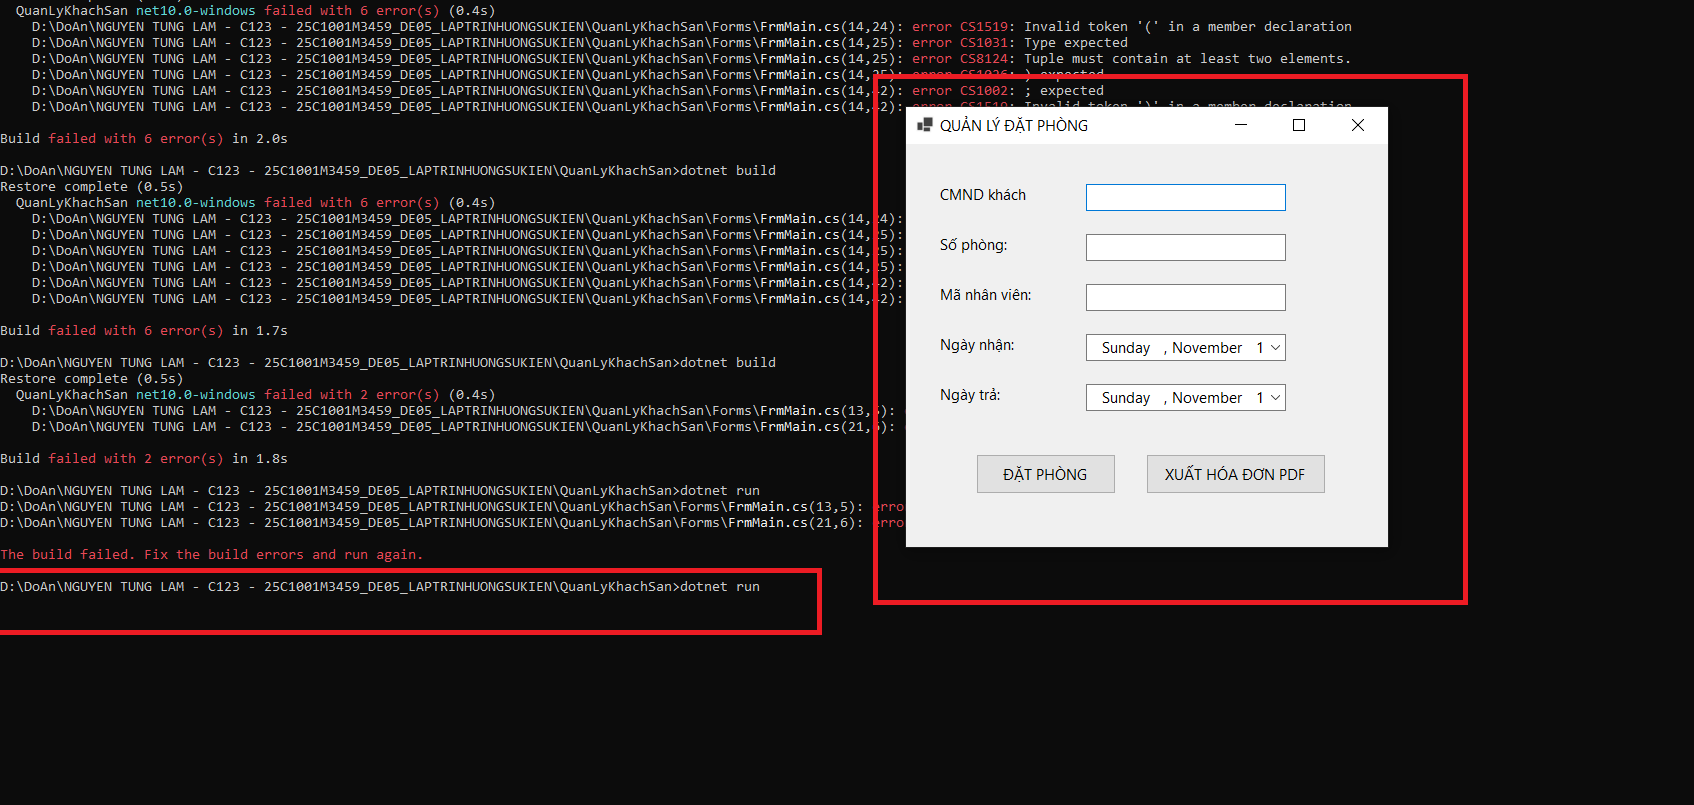

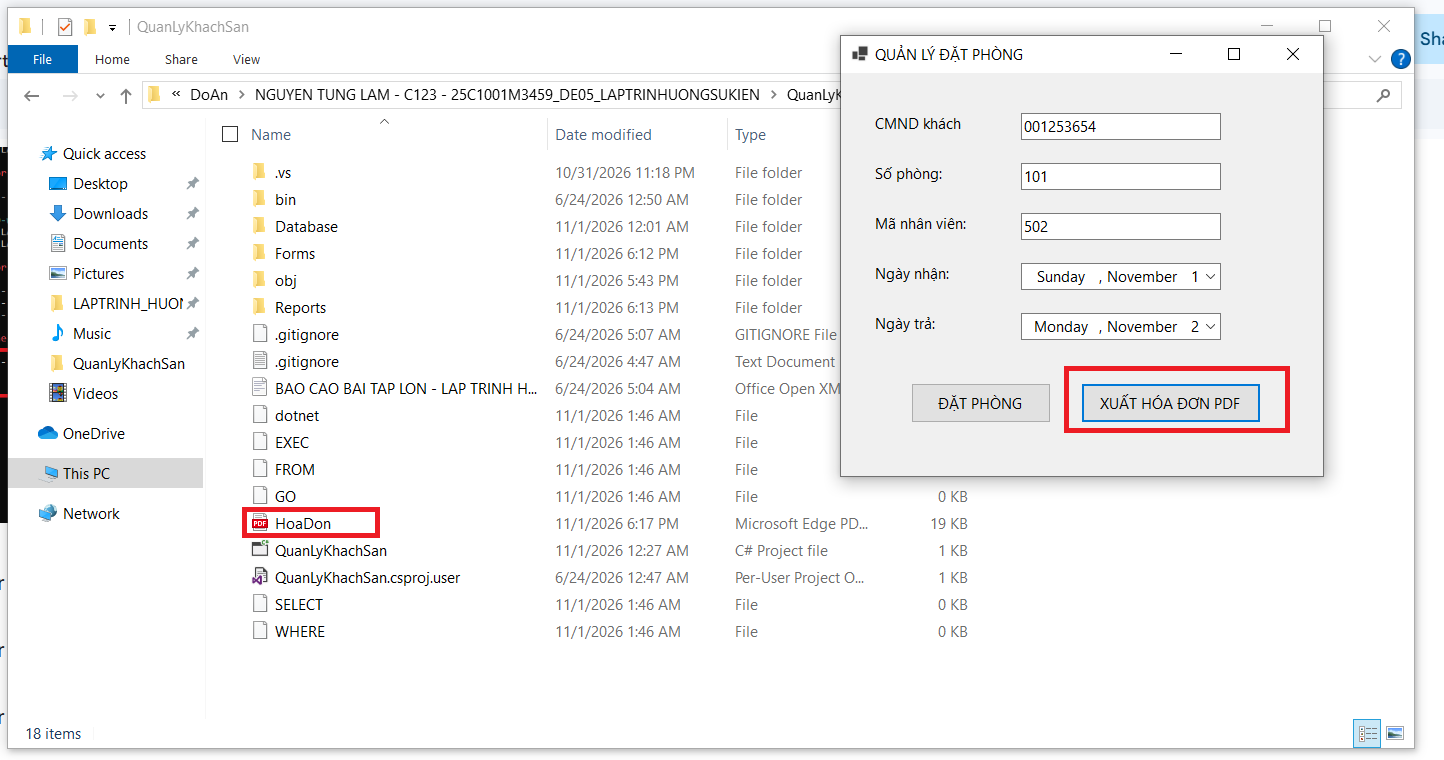

ERROR

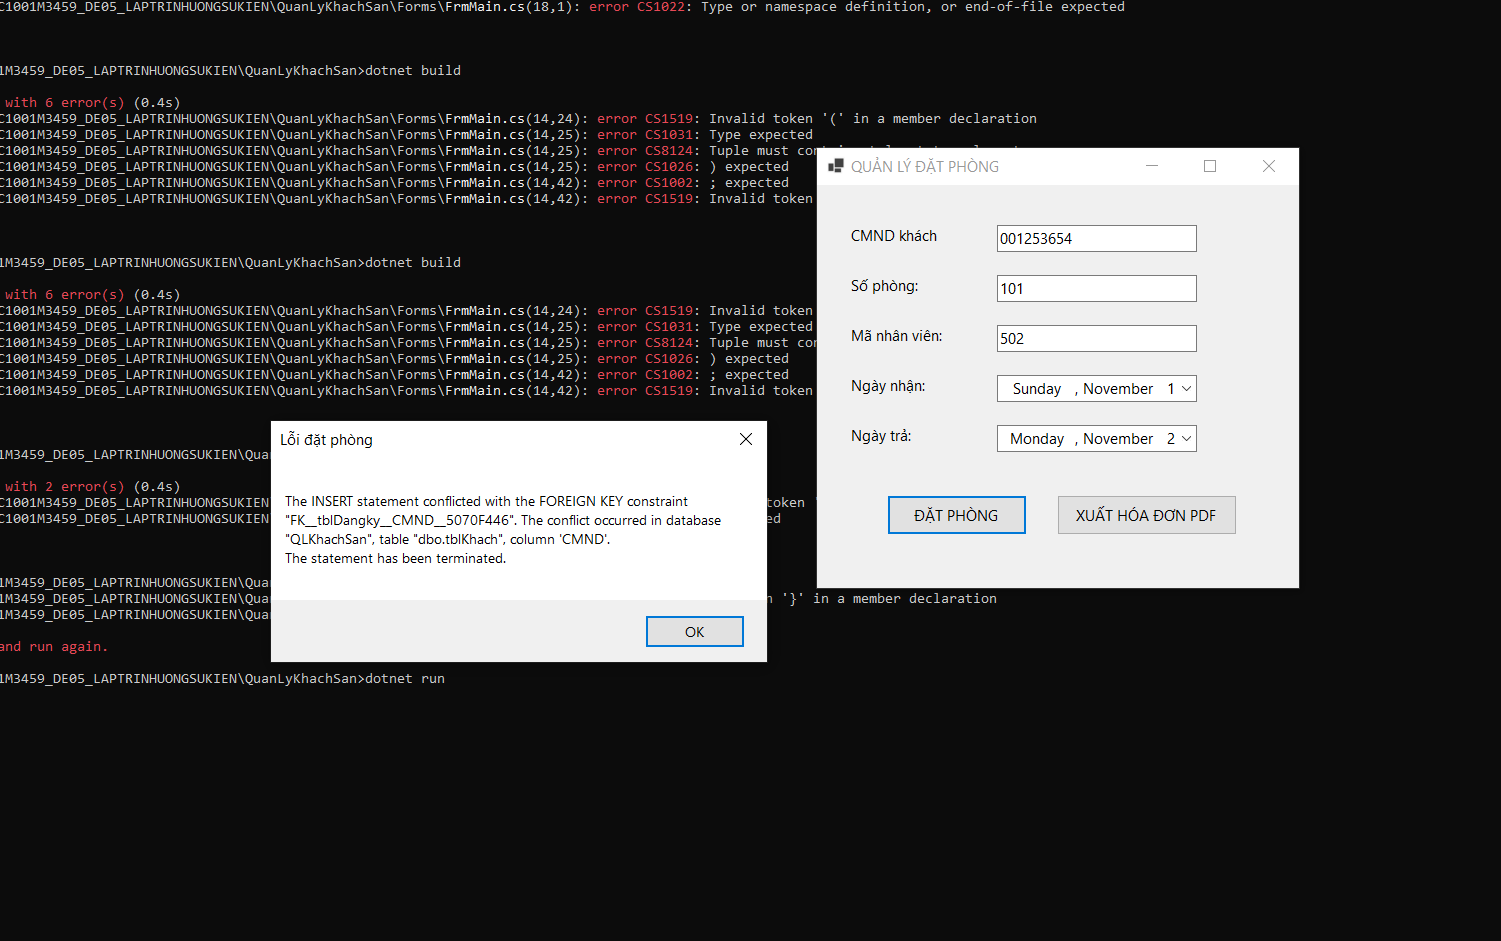

FIX DEFAULT ENVOICE

FIX FRMDATPHONG.CS

In [ ]:

using System;
using System.Windows.Forms;
using Microsoft.Data.SqlClient;
using QuanLyKhachSan.Database;
using QuanLyKhachSan.Reports;

namespace QuanLyKhachSan;

public class FrmDatPhong : Form
{
    TextBox txtCMND = new();
    TextBox txtPhong = new();
    TextBox txtMaNV = new();

    DateTimePicker dtNhan = new();
    DateTimePicker dtTra = new();

    Button btnDat = new();
    Button btnHoaDon = new();

    public FrmDatPhong()
    {
        CreateForm();
    }

    void CreateForm()
    {
        Text = "QUẢN LÝ ĐẶT PHÒNG";
        Width = 500;
        Height = 450;
        StartPosition = FormStartPosition.CenterScreen;

        Label lblCMND = new()
        {
            Text = "CMND khách hàng:",
            Left = 30,
            Top = 40,
            Width = 130
        };

        txtCMND.SetBounds(180, 40, 200, 25);

        Label lblPhong = new()
        {
            Text = "Số phòng:",
            Left = 30,
            Top = 90,
            Width = 130
        };

        txtPhong.SetBounds(180, 90, 200, 25);

        Label lblMaNV = new()
        {
            Text = "Mã nhân viên:",
            Left = 30,
            Top = 140,
            Width = 130
        };

        txtMaNV.SetBounds(180, 140, 200, 25);

        Label lblNhan = new()
        {
            Text = "Ngày nhận:",
            Left = 30,
            Top = 190,
            Width = 130
        };

        dtNhan.SetBounds(180, 190, 200, 25);

        Label lblTra = new()
        {
            Text = "Ngày trả:",
            Left = 30,
            Top = 240,
            Width = 130
        };

        dtTra.SetBounds(180, 240, 200, 25);

        btnDat.Text = "ĐẶT PHÒNG";
        btnDat.SetBounds(70, 310, 140, 40);
        btnDat.Click += btnDat_Click;

        btnHoaDon.Text = "XUẤT HÓA ĐƠN PDF";
        btnHoaDon.SetBounds(240, 310, 180, 40);
        btnHoaDon.Click += btnHoaDon_Click;

        Controls.AddRange(new Control[]
        {
            lblCMND, txtCMND,
            lblPhong, txtPhong,
            lblMaNV, txtMaNV,
            lblNhan, dtNhan,
            lblTra, dtTra,
            btnDat, btnHoaDon
        });
    }

    // Đặt phòng
    private void btnDat_Click(object? sender, EventArgs e)
    {
        try
        {
            using SqlConnection conn = DB.GetConnection();
            conn.Open();

            using SqlCommand cmd =
                new("sp_DatPhong", conn);

            cmd.CommandType =
                System.Data.CommandType.StoredProcedure;

            cmd.Parameters.AddWithValue("@CMND", txtCMND.Text);
            cmd.Parameters.AddWithValue("@SoPhong", txtPhong.Text);
            cmd.Parameters.AddWithValue("@MaNV", txtMaNV.Text);
            cmd.Parameters.AddWithValue("@NgayDK", DateTime.Now);
            cmd.Parameters.AddWithValue("@NgayNhan", dtNhan.Value);
            cmd.Parameters.AddWithValue("@NgayTra", dtTra.Value);

            cmd.ExecuteNonQuery();

            MessageBox.Show("Đặt phòng thành công!");
        }
        catch (Exception ex)
        {
            MessageBox.Show(ex.Message, "Lỗi đặt phòng");
        }
    }

    // Xuất PDF
    private void btnHoaDon_Click(object? sender, EventArgs e)
    {
        try
        {
            if (string.IsNullOrWhiteSpace(txtCMND.Text) ||
                string.IsNullOrWhiteSpace(txtPhong.Text))
            {
                MessageBox.Show("Vui lòng nhập CMND và số phòng!");
                return;
            }

            if (dtTra.Value.Date <= dtNhan.Value.Date)
            {
                MessageBox.Show("Ngày trả phải sau ngày nhận!");
                return;
            }

            HoaDonPDF.TaoHoaDon(
                txtCMND.Text.Trim(),
                txtPhong.Text.Trim(),
                dtNhan.Value.Date,
                dtTra.Value.Date
            );
        }
        catch (Exception ex)
        {
            MessageBox.Show(ex.Message, "Lỗi xuất PDF");
        }
    }
}




FIX HOADONPDF.CS

In [ ]:

using System;
using System.IO;
using Microsoft.Data.SqlClient;
using QuestPDF.Fluent;
using QuestPDF.Helpers;
using QuestPDF.Infrastructure;
using QuanLyKhachSan.Database;

namespace QuanLyKhachSan.Reports
{
    public class HoaDonPDF
    {
        public static string TaoHoaDon(
            string cmnd,
            string soPhong,
            DateTime ngayNhan,
            DateTime ngayTra)
        {
            QuestPDF.Settings.License = LicenseType.Community;

            if (ngayTra.Date <= ngayNhan.Date)
                throw new Exception("Ngày trả phải sau ngày nhận!");

            string hoTen;
            string dienThoai;
            string diaChi;
            decimal donGia;

            // Lấy thông tin khách hàng và phòng từ SQL Server
            using (SqlConnection conn = DB.GetConnection())
            {
                conn.Open();

                string sql = @"
                    SELECT
                        k.HoTen,
                        k.DienThoai,
                        k.DiaChi,
                        p.SoPhong,
                        p.DonGia
                    FROM tblKhach k
                    CROSS JOIN tblPhong p
                    WHERE k.CMND = @CMND
                    AND p.SoPhong = @SoPhong";

                using SqlCommand cmd = new SqlCommand(sql, conn);

                cmd.Parameters.AddWithValue("@CMND", cmnd);
                cmd.Parameters.AddWithValue("@SoPhong", soPhong);

                using SqlDataReader reader = cmd.ExecuteReader();

                if (!reader.Read())
                {
                    throw new Exception(
                        "Không tìm thấy khách hàng hoặc phòng!");
                }

                hoTen = reader["HoTen"]?.ToString() ?? "";
                dienThoai = reader["DienThoai"]?.ToString() ?? "";
                diaChi = reader["DiaChi"]?.ToString() ?? "";

                donGia = reader["DonGia"] == DBNull.Value
                    ? 0
                    : Convert.ToDecimal(reader["DonGia"]);
            }

            // Tính tiền
            int soNgay = (ngayTra.Date - ngayNhan.Date).Days;
            decimal tongTien = donGia * soNgay;

            // Tạo đường dẫn PDF
            string folder = Path.Combine(
                Environment.GetFolderPath(
                    Environment.SpecialFolder.MyDocuments),
                "HoaDonKhachSan");

            Directory.CreateDirectory(folder);

            string tenFile = $"HoaDon_{cmnd}_{soPhong}_{DateTime.Now:yyyyMMdd_HHmmss}.pdf";

            string file = Path.Combine(folder, tenFile);

            // Tạo hóa đơn PDF
            Document.Create(container =>
            {
                container.Page(page =>
                {
                    page.Size(PageSizes.A4);
                    page.Margin(40);

                    page.Header()
                        .Column(col =>
                        {
                            col.Item()
                                .Text("QUAN LY KHACH SAN")
                                .FontSize(22)
                                .Bold()
                                .AlignCenter();

                            col.Item()
                                .Text("HOA DON THANH TOAN")
                                .FontSize(18)
                                .Bold()
                                .AlignCenter();
                        });

                    page.Content()
                        .PaddingTop(30)
                        .Column(col =>
                        {
                            col.Spacing(12);

                            col.Item().Text(
                                $"Ngay lap: {DateTime.Now:dd/MM/yyyy}");

                            col.Item().Text(
                                $"CMND: {cmnd}");

                            col.Item().Text(
                                $"Khach hang: {hoTen}");

                            col.Item().Text(
                                $"Dien thoai: {dienThoai}");

                            col.Item().Text(
                                $"Dia chi: {diaChi}");

                            col.Item().Text(
                                $"So phong: {soPhong}");

                            col.Item().Text(
                                $"Ngay nhan: {ngayNhan:dd/MM/yyyy}");

                            col.Item().Text(
                                $"Ngay tra: {ngayTra:dd/MM/yyyy}");

                            col.Item().Text(
                                $"So ngay thue: {soNgay}");

                            col.Item().PaddingTop(15)
                                .Text(
                                    $"Don gia phong: {donGia:N0} VND");

                            col.Item().Text(
                                $"Tong tien: {tongTien:N0} VND")
                                .FontSize(20)
                                .Bold();
                        });

                    page.Footer()
                        .AlignCenter()
                        .Text("CAM ON QUY KHACH!");
                });
            })
            .GeneratePdf(file);

            return file;
        }
    }
}


FIX ERROR

In [ ]:
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>sqlcmd
1> USE QLKhachSan;
2> GO
Changed database context to 'QLKhachSan'.
1>
2> SELECT * FROM tblNhanvien;
3> GO
MaNV       HoTen
---------- ----------------------------------------------------------------------------------------------------
NV01       Nguy?n Th? Mai

In [ ]:
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet run


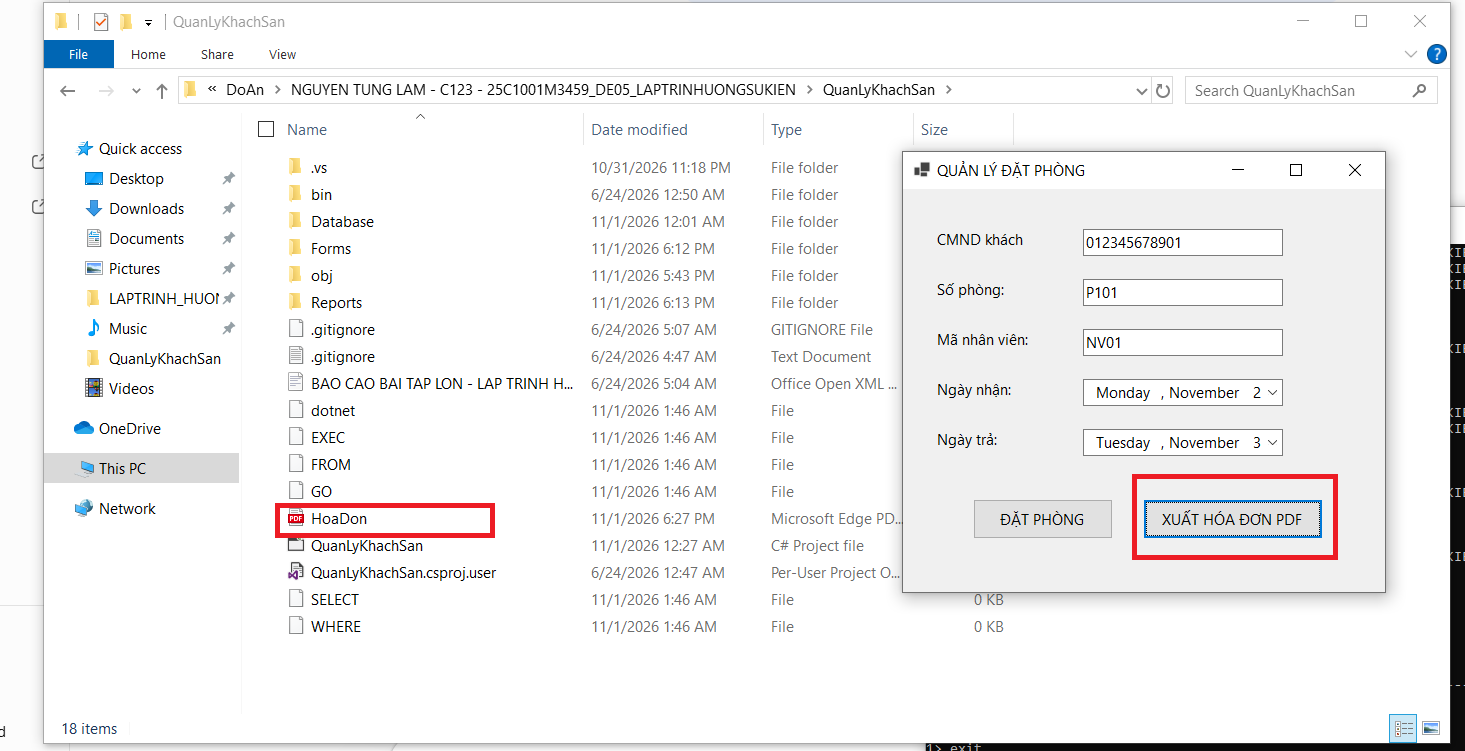

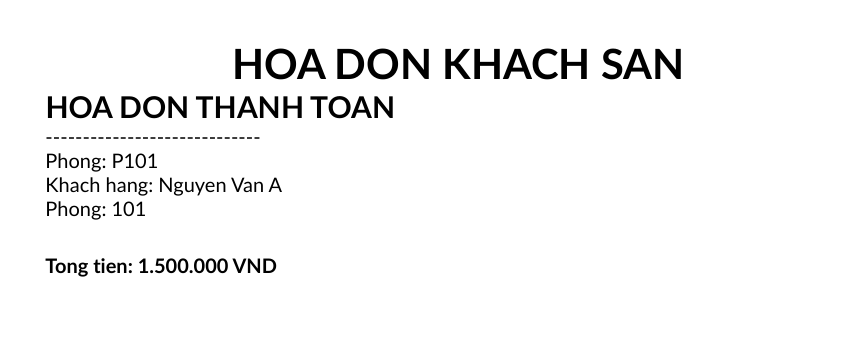

In [ ]:
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>SELECT * FROM tblNhanvien;
'SELECT' is not recognized as an internal or external command,
operable program or batch file.

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>GO
'GO' is not recognized as an internal or external command,
operable program or batch file.

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>sqlcmd
1> USE QLKhachSan;
2> GO
Changed database context to 'QLKhachSan'.
1>
2> SELECT * FROM tblNhanvien;
3> GO
MaNV       HoTen
---------- ----------------------------------------------------------------------------------------------------
NV01       Nguy?n Th? Mai

(1 rows affected)
1> exit

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet run

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet run

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet run

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>USE QLKhachSan;
'USE' is not recognized as an internal or external command,
operable program or batch file.

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>GO
'GO' is not recognized as an internal or external command,
operable program or batch file.

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>SELECT * FROM tblPhong;
'SELECT' is not recognized as an internal or external command,
operable program or batch file.

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>USE QLKhachSan;
'USE' is not recognized as an internal or external command,
operable program or batch file.

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>sqlcmd
1> USE QLKhachSan;
2> GO
Changed database context to 'QLKhachSan'.
1> SELECT * FROM tblPhong;
2> GO
SoPhong    SucChua     DonGia               TinhTrang
---------- ----------- -------------------- --------------------
P101                 2            500000.00 Da thuê
P102                 2            300000.00 Tr?ng
P103                 3            450000.00 Tr?ng
P104                 3            450000.00 Tr?ng
P105                 4            600000.00 Tr?ng
P201                 2            350000.00 Tr?ng
P202                 2            350000.00 Tr?ng
P203                 3            500000.00 Tr?ng
P204                 4            650000.00 Tr?ng
P205                 4            800000.00 Tr?ng

(10 rows affected)
1> SELECT * FROM tblDangky;
2> GO
MaDK        CMND            MaNV       SoPhong    NgayDK           NgayNhan         NgayTra          TrangThai
----------- --------------- ---------- ---------- ---------------- ---------------- ---------------- --------------------
          1 012345678901    NV01       P101             2026-11-01       2026-11-01       2026-11-03 Dang thuê

(1 rows affected)
1> SELECT
2>     k.CMND,
3>     k.HoTen,
4>     k.DienThoai,
5>     k.DiaChi,
6>     p.SoPhong,
7>     p.DonGia,
8>     d.NgayNhan,
9>     d.NgayTra
10> FROM tblKhach k
11> CROSS JOIN tblPhong p
12> CROSS JOIN tblDangky d
13> WHERE k.CMND = d.CMND
14> AND p.SoPhong = d.SoPhong;
15> GO
CMND            HoTen                                                                                                DienThoai       DiaChi                                                                                                                                                                                                   SoPhong    DonGia               NgayNhan         NgayTra
--------------- ---------------------------------------------------------------------------------------------------- --------------- -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- ---------- -------------------- ---------------- ----------------
012345678901    Nguy?n Th? Mai                                                                                       0912345678      Hà N?i                                                                                                                                                                                                   P101                  500000.00       2026-11-01       2026-11-03

(1 rows affected)
1>








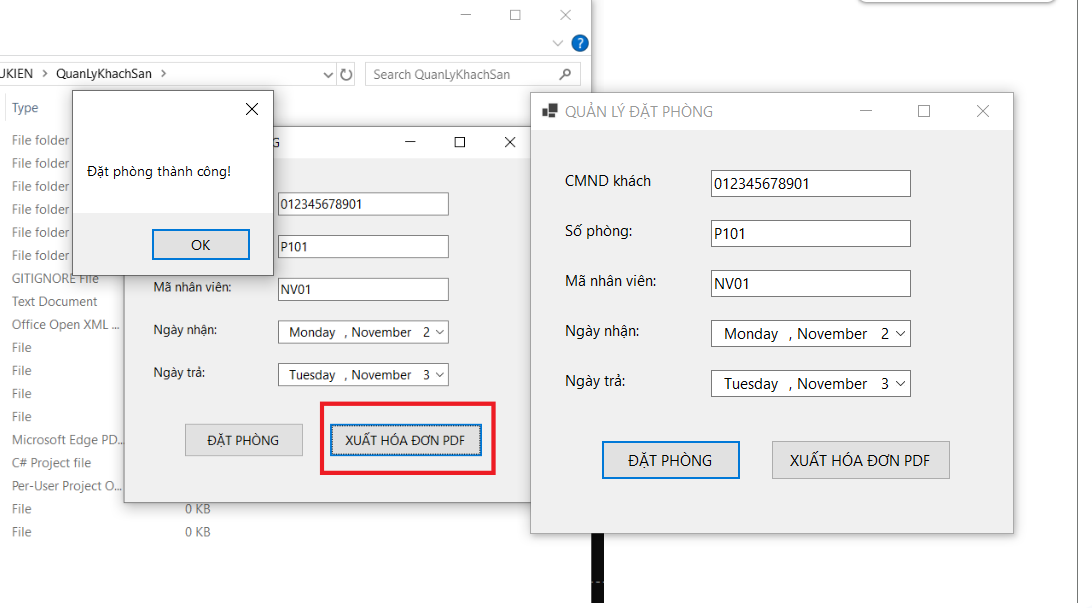

FIX FORMDATPHONG.CS

In [ ]:

using System;
using System.Windows.Forms;
using Microsoft.Data.SqlClient;
using QuanLyKhachSan.Database;
using QuanLyKhachSan.Reports;

namespace QuanLyKhachSan;

public class FrmDatPhong : Form
{
    TextBox txtCMND = new();
    TextBox txtPhong = new();
    TextBox txtMaNV = new();

    DateTimePicker dtNhan = new();
    DateTimePicker dtTra = new();

    Button btnDat = new();
    Button btnHoaDon = new();

    public FrmDatPhong()
    {
        CreateForm();
    }

    void CreateForm()
    {
        Text = "QUẢN LÝ ĐẶT PHÒNG";
        Width = 500;
        Height = 450;
        StartPosition = FormStartPosition.CenterScreen;

        Label lblCMND = new()
        {
            Text = "CMND khách hàng:",
            Left = 30,
            Top = 40,
            Width = 130
        };

        txtCMND.SetBounds(180, 40, 200, 25);

        Label lblPhong = new()
        {
            Text = "Số phòng:",
            Left = 30,
            Top = 90,
            Width = 130
        };

        txtPhong.SetBounds(180, 90, 200, 25);

        Label lblMaNV = new()
        {
            Text = "Mã nhân viên:",
            Left = 30,
            Top = 140,
            Width = 130
        };

        txtMaNV.SetBounds(180, 140, 200, 25);

        Label lblNhan = new()
        {
            Text = "Ngày nhận:",
            Left = 30,
            Top = 190,
            Width = 130
        };

        dtNhan.SetBounds(180, 190, 200, 25);

        Label lblTra = new()
        {
            Text = "Ngày trả:",
            Left = 30,
            Top = 240,
            Width = 130
        };

        dtTra.SetBounds(180, 240, 200, 25);

        btnDat.Text = "ĐẶT PHÒNG";
        btnDat.SetBounds(70, 310, 140, 40);
        btnDat.Click += btnDat_Click;

        btnHoaDon.Text = "XUẤT HÓA ĐƠN PDF";
        btnHoaDon.SetBounds(240, 310, 180, 40);
        btnHoaDon.Click += btnHoaDon_Click;

        Controls.AddRange(new Control[]
        {
            lblCMND, txtCMND,
            lblPhong, txtPhong,
            lblMaNV, txtMaNV,
            lblNhan, dtNhan,
            lblTra, dtTra,
            btnDat, btnHoaDon
        });
    }

    // Đặt phòng
    private void btnDat_Click(object? sender, EventArgs e)
    {
        try
        {
            using SqlConnection conn = DB.GetConnection();
            conn.Open();

            using SqlCommand cmd =
                new("sp_DatPhong", conn);

            cmd.CommandType =
                System.Data.CommandType.StoredProcedure;

            cmd.Parameters.AddWithValue("@CMND", txtCMND.Text);
            cmd.Parameters.AddWithValue("@SoPhong", txtPhong.Text);
            cmd.Parameters.AddWithValue("@MaNV", txtMaNV.Text);
            cmd.Parameters.AddWithValue("@NgayDK", DateTime.Now);
            cmd.Parameters.AddWithValue("@NgayNhan", dtNhan.Value);
            cmd.Parameters.AddWithValue("@NgayTra", dtTra.Value);

            cmd.ExecuteNonQuery();

            MessageBox.Show("Đặt phòng thành công!");
        }
        catch (Exception ex)
        {
            MessageBox.Show(ex.Message, "Lỗi đặt phòng");
        }
    }

    // Xuất PDF
    private void btnHoaDon_Click(object? sender, EventArgs e)
    {
        try
        {
            MessageBox.Show("Đang tạo hóa đơn...");

            string file = HoaDonPDF.TaoHoaDon(
                txtCMND.Text.Trim(),
                txtPhong.Text.Trim(),
                dtNhan.Value.Date,
                dtTra.Value.Date
            );

            MessageBox.Show(
                "XUẤT PDF THÀNH CÔNG!\n\n" + file
            );

            System.Diagnostics.Process.Start(
                new System.Diagnostics.ProcessStartInfo
                {
                    FileName = file,
                    UseShellExecute = true
                }
            );
        }
        catch (Exception ex)
        {
            MessageBox.Show(
                ex.ToString(),
                "LỖI XUẤT PDF"
            );
        }
    }
}




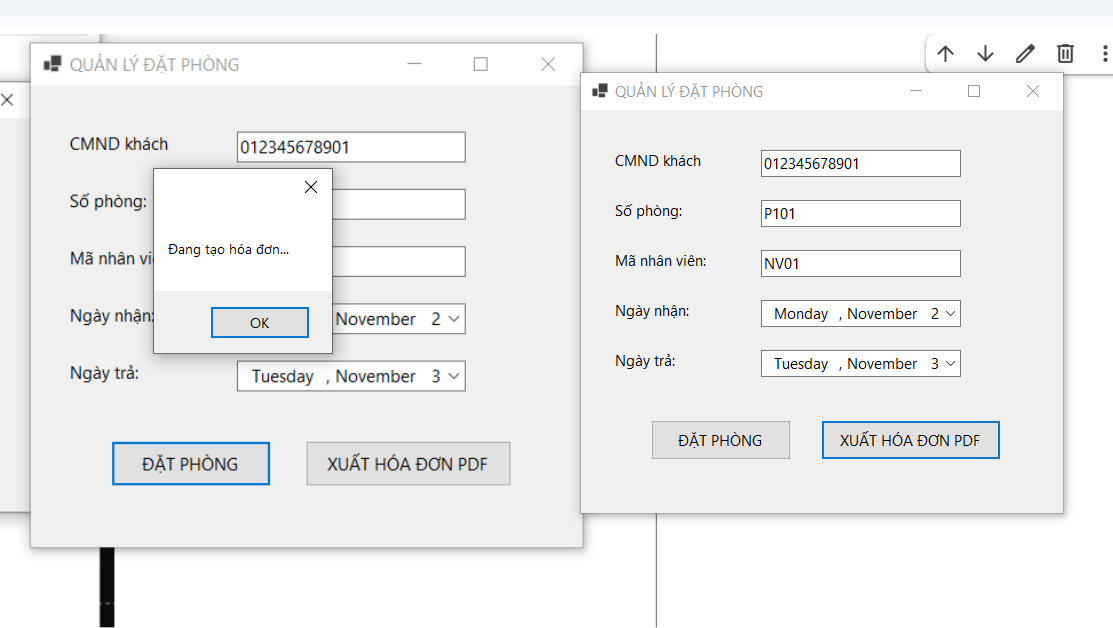

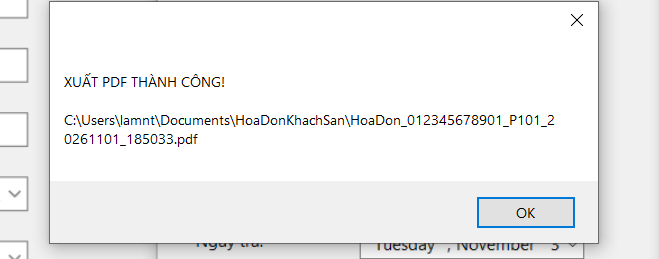

PATH OF HOA DON

In [ ]:
C:\Users\lamnt\Documents\HoaDonKhachSan

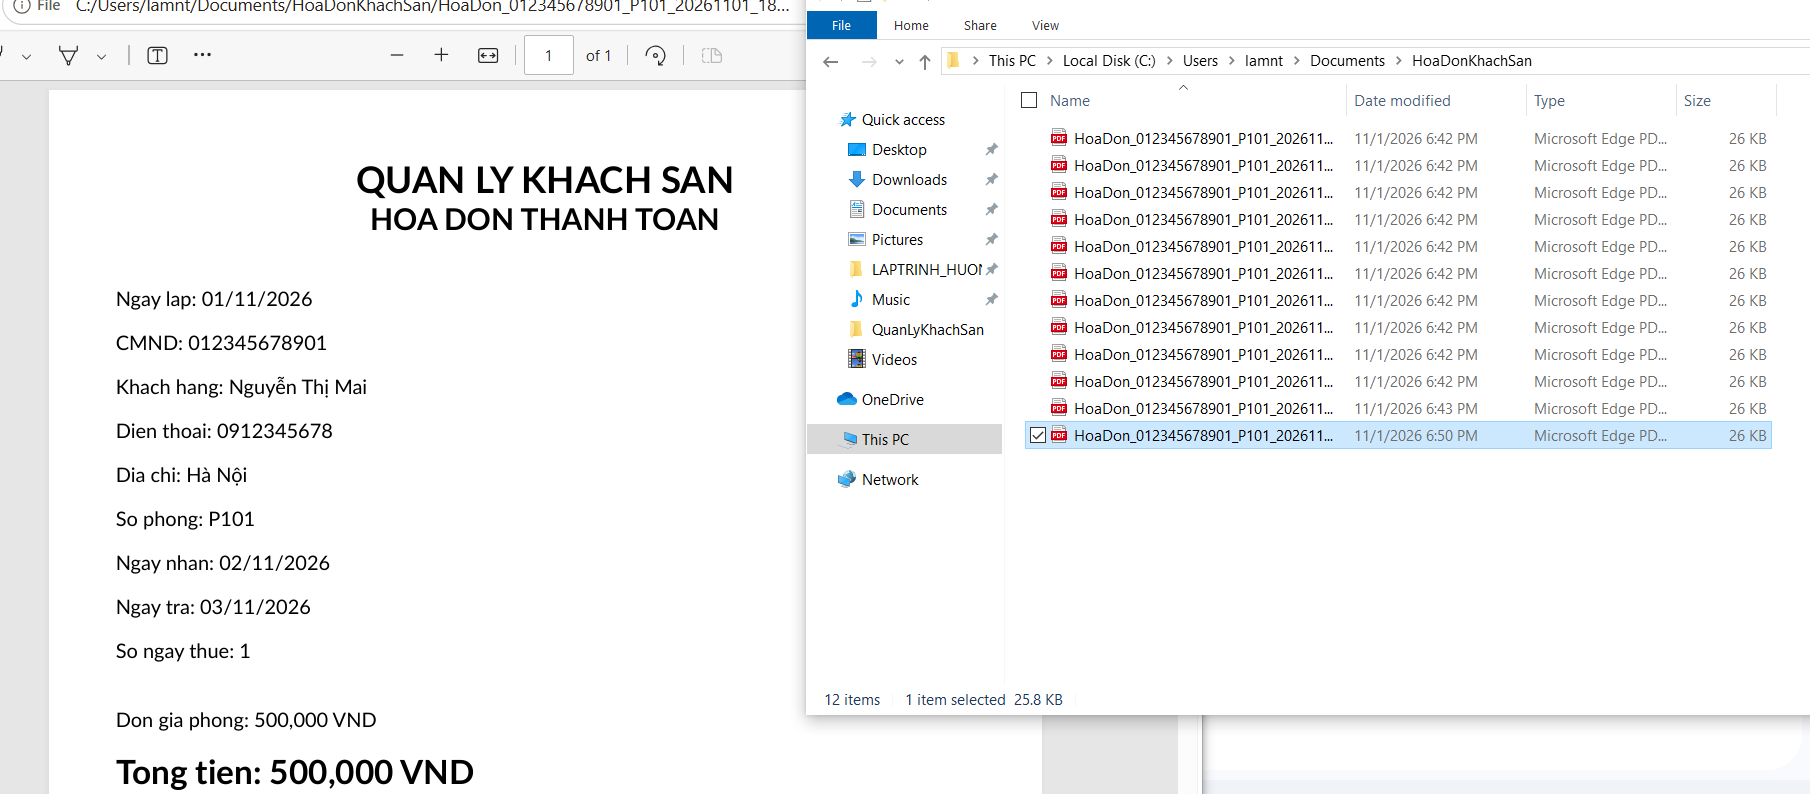

DOWNLOAD GIT

https://git-scm.com/install/windows

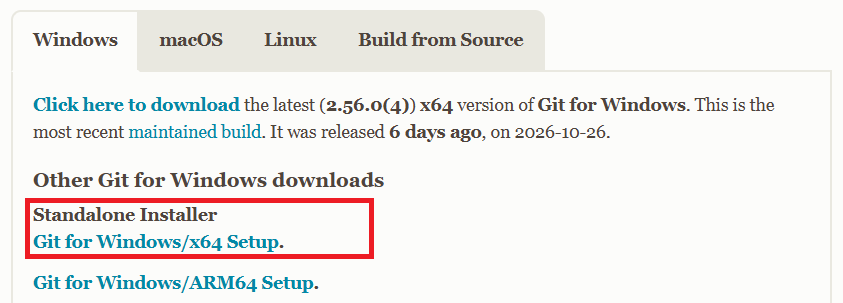

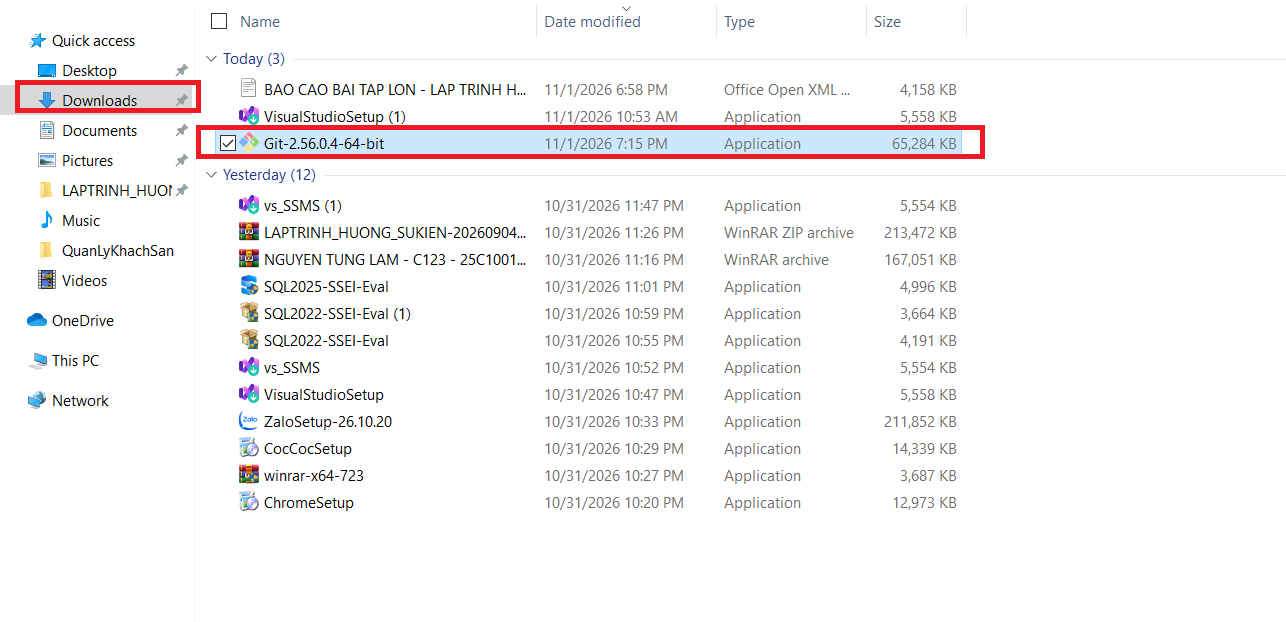

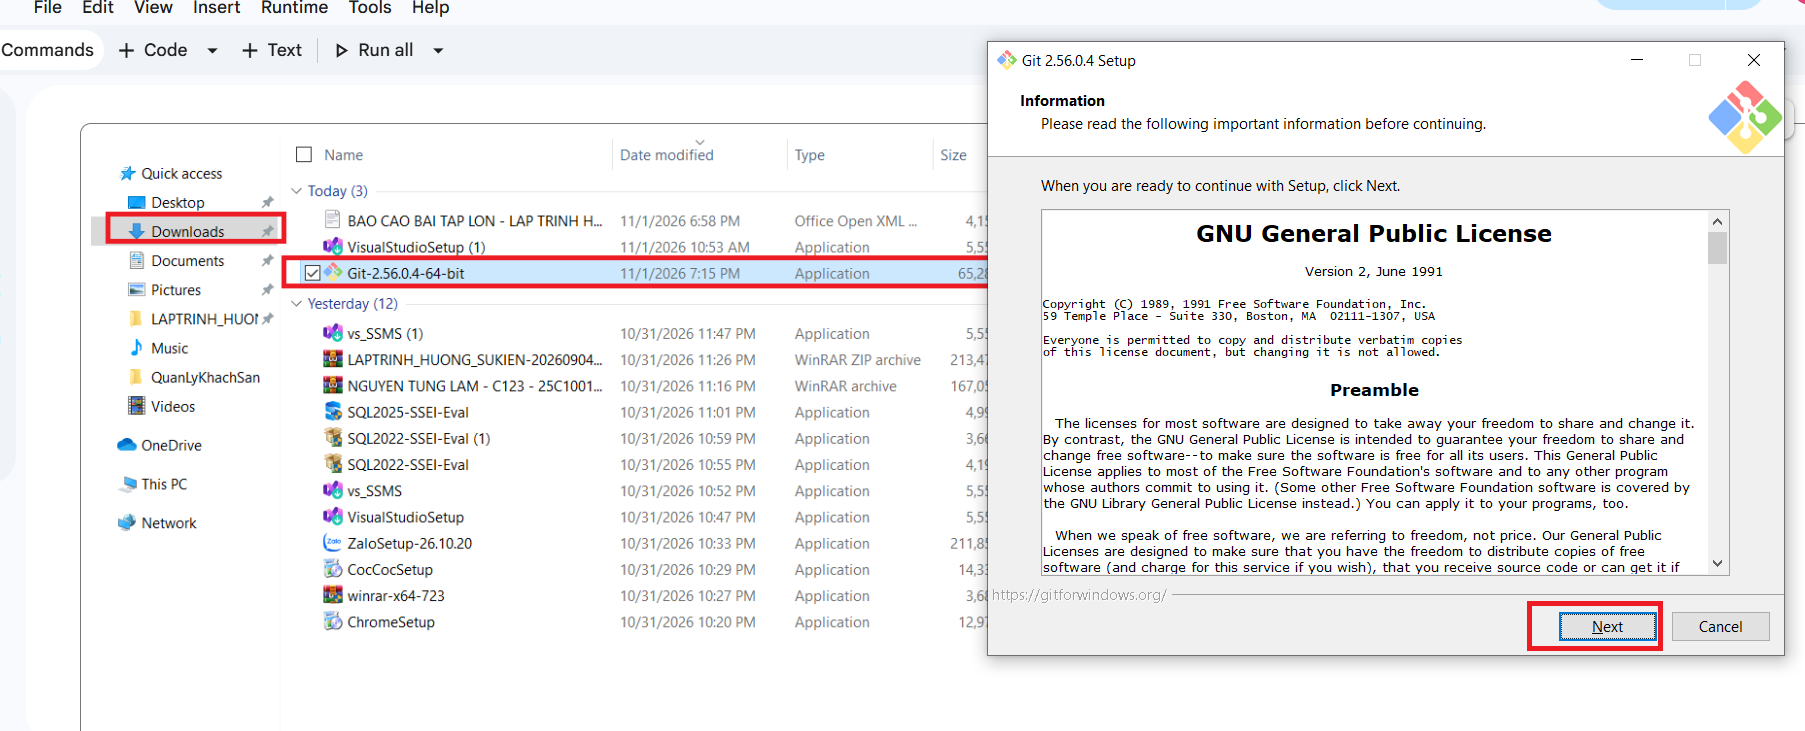

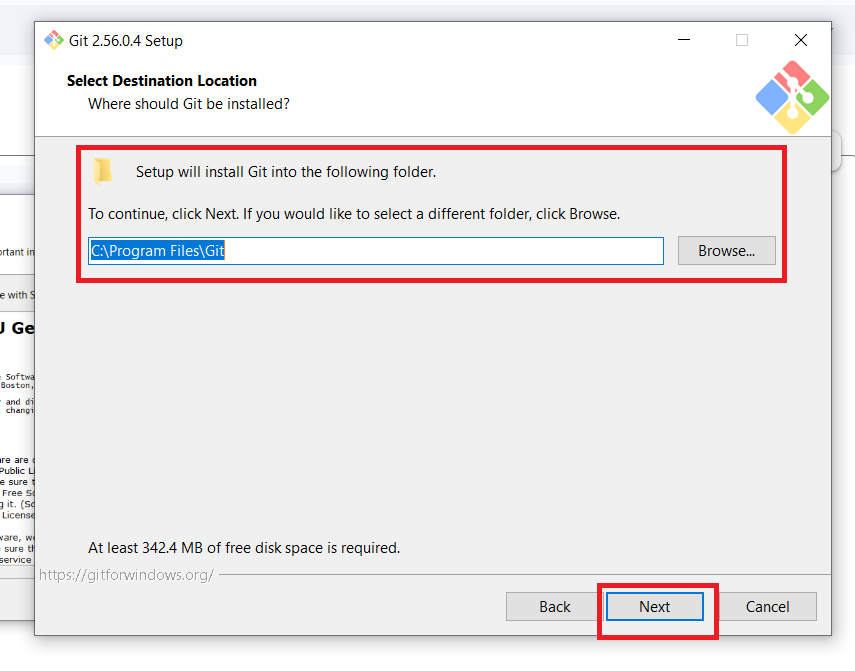

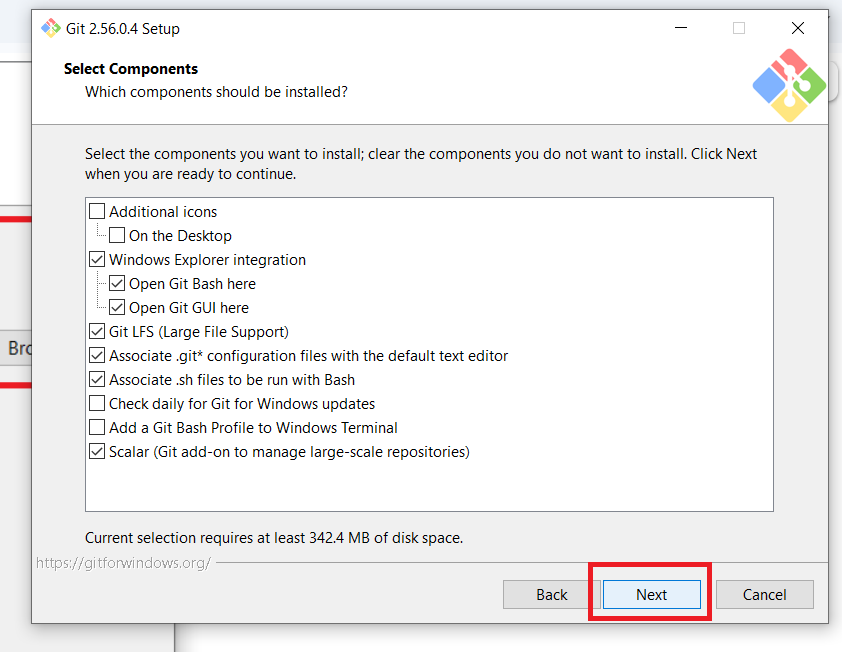

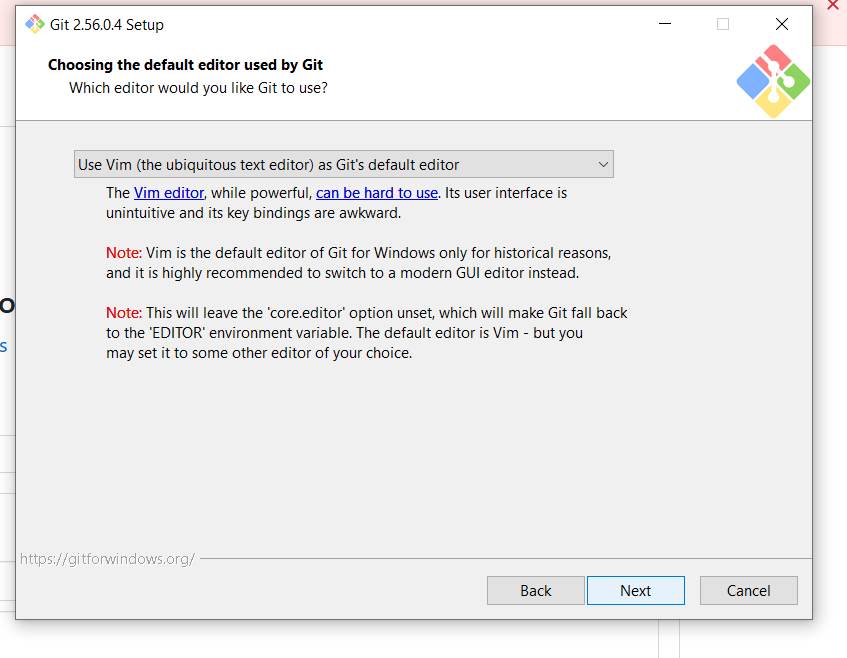

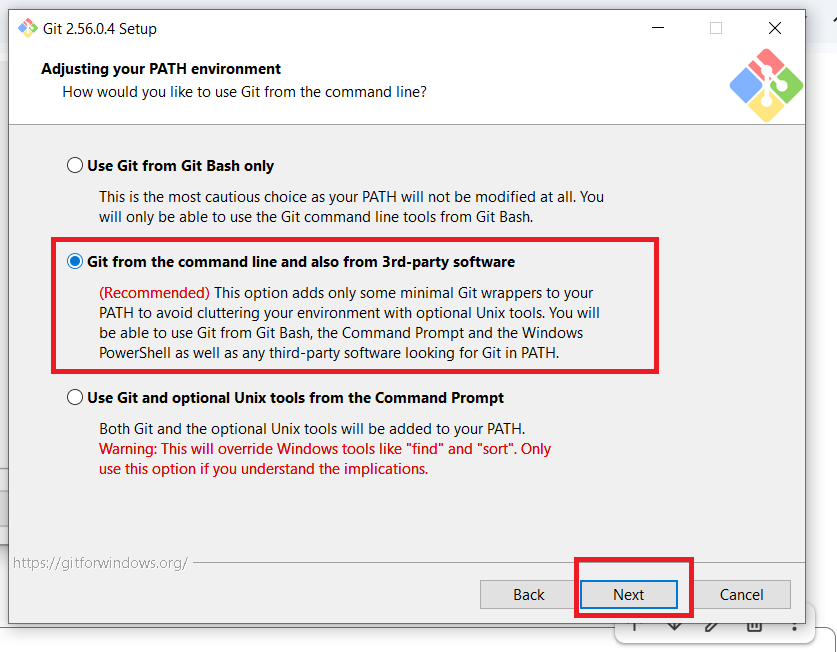

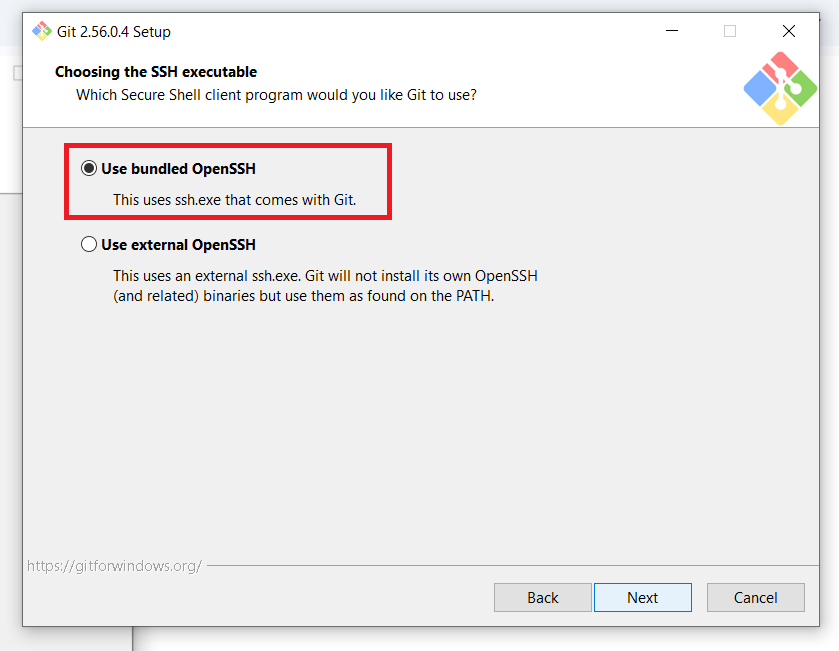

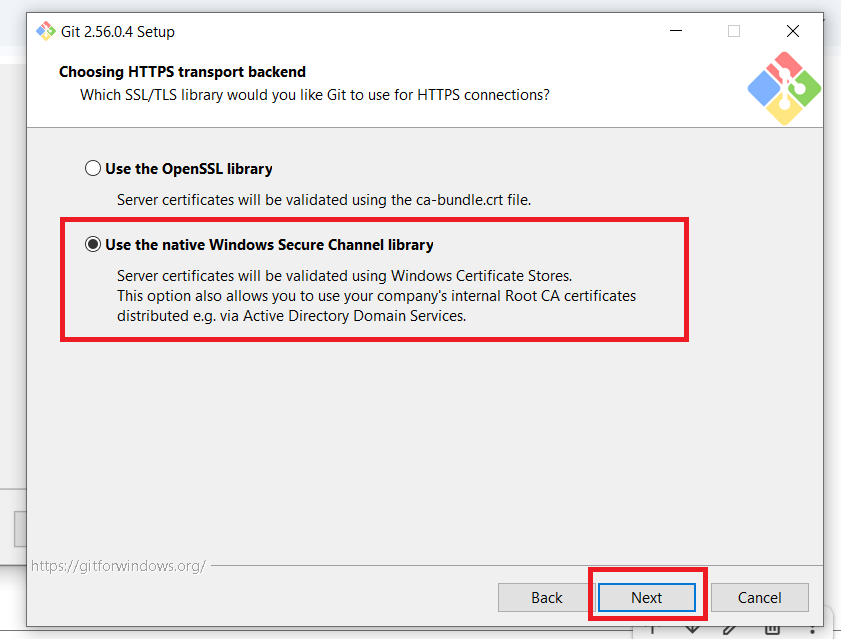

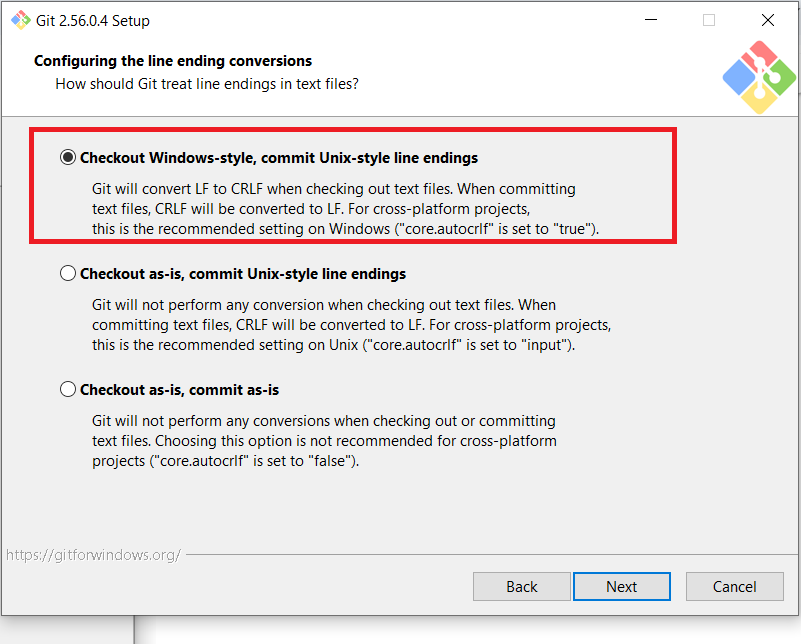

In [ ]:
Microsoft Windows [Version 10.0.19045.6466]
(c) Microsoft Corporation. All rights reserved.

C:\Users\lamnt>cd /d "D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan"

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>git init
Reinitialized existing Git repository in D:/DoAn/NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN/QuanLyKhachSan/.git/

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>git status
On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add/rm <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
        modified:   Forms/FrmDatPhong.cs
        modified:   Forms/FrmKhach.cs
        modified:   Forms/FrmPhong.cs
        deleted:    FrmMain.Designer.cs
        deleted:    FrmMain.cs
        deleted:    HoaDon.pdf
        deleted:    Program.cs
        modified:   QuanLyKhachSan.csproj
        modified:   Reports/HoaDonPDF.cs
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-Black.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-BlackItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-Bold.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-BoldItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-ExtraBold.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-ExtraBoldItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-ExtraLight.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-ExtraLightItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-Italic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-Light.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-LightItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-Medium.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-MediumItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-Regular.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-SemiBold.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-SemiBoldItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-Thin.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-ThinItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/OFL.txt
        modified:   bin/Debug/net10.0-windows/QuanLyKhachSan.deps.json
        modified:   bin/Debug/net10.0-windows/QuanLyKhachSan.dll
        modified:   bin/Debug/net10.0-windows/QuanLyKhachSan.exe
        modified:   bin/Debug/net10.0-windows/QuanLyKhachSan.pdb
        modified:   bin/Debug/net10.0-windows/QuestPDF.dll
        modified:   bin/Debug/net10.0-windows/runtimes/linux-arm64/native/libQuestPdfSkia.so
        modified:   bin/Debug/net10.0-windows/runtimes/linux-arm64/native/libqpdf.so
        modified:   bin/Debug/net10.0-windows/runtimes/linux-musl-x64/native/libQuestPdfSkia.so
        modified:   bin/Debug/net10.0-windows/runtimes/linux-musl-x64/native/libqpdf.so
        modified:   bin/Debug/net10.0-windows/runtimes/linux-x64/native/libQuestPdfSkia.so
        modified:   bin/Debug/net10.0-windows/runtimes/linux-x64/native/libqpdf.so
        modified:   bin/Debug/net10.0-windows/runtimes/osx-arm64/native/libQuestPdfSkia.dylib
        modified:   bin/Debug/net10.0-windows/runtimes/osx-arm64/native/libqpdf.dylib
        modified:   bin/Debug/net10.0-windows/runtimes/osx-x64/native/libQuestPdfSkia.dylib
        modified:   bin/Debug/net10.0-windows/runtimes/osx-x64/native/libqpdf.dylib
        modified:   bin/Debug/net10.0-windows/runtimes/win-arm64/native/QuestPdfSkia.dll
        modified:   bin/Debug/net10.0-windows/runtimes/win-arm64/native/qpdf.dll
        modified:   bin/Debug/net10.0-windows/runtimes/win-x64/native/QuestPdfSkia.dll
        modified:   bin/Debug/net10.0-windows/runtimes/win-x64/native/qpdf.dll
        modified:   bin/Debug/net10.0-windows/runtimes/win-x86/native/QuestPdfSkia.dll
        modified:   bin/Debug/net10.0-windows/runtimes/win-x86/native/qpdf.dll
        modified:   obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfo.cs
        modified:   obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfoInputs.cache
        modified:   obj/Debug/net10.0-windows/QuanLyKhachSan.GeneratedMSBuildEditorConfig.editorconfig
        modified:   obj/Debug/net10.0-windows/QuanLyKhachSan.assets.cache
        modified:   obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.AssemblyReference.cache
        modified:   obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.CoreCompileInputs.cache
        modified:   obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.FileListAbsolute.txt
        modified:   obj/Debug/net10.0-windows/QuanLyKhachSan.dll
        modified:   obj/Debug/net10.0-windows/QuanLyKhachSan.genruntimeconfig.cache
        modified:   obj/Debug/net10.0-windows/QuanLyKhachSan.pdb
        modified:   obj/Debug/net10.0-windows/apphost.exe
        modified:   obj/Debug/net10.0-windows/ref/QuanLyKhachSan.dll
        modified:   obj/Debug/net10.0-windows/refint/QuanLyKhachSan.dll
        modified:   obj/QuanLyKhachSan.csproj.nuget.dgspec.json
        modified:   obj/QuanLyKhachSan.csproj.nuget.g.props
        modified:   obj/QuanLyKhachSan.csproj.nuget.g.targets
        modified:   obj/Release/net10.0-windows/QuanLyKhachSan.AssemblyInfo.cs
        modified:   obj/Release/net10.0-windows/QuanLyKhachSan.AssemblyInfoInputs.cache
        modified:   obj/Release/net10.0-windows/QuanLyKhachSan.GeneratedMSBuildEditorConfig.editorconfig
        modified:   obj/Release/net10.0-windows/QuanLyKhachSan.assets.cache
        modified:   obj/Release/net10.0-windows/QuanLyKhachSan.csproj.AssemblyReference.cache
        modified:   obj/project.assets.json
        modified:   obj/project.nuget.cache

Untracked files:
  (use "git add <file>..." to include in what will be committed)
        Database/QuanLyKhachSan.sql
        Database/SQL Server Scripts1/
        EXEC
        FROM
        Forms/Form1.cs
        Forms/Forn1.Designer.cs
        Forms/FrmMain.Designer.cs
        Forms/FrmMain.cs
        GO
        Reports/Program.cs
        SELECT
        WHERE
        dotnet

no changes added to commit (use "git add" and/or "git commit -a")

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>notepad .gitignore

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>git rm -r --cached bin obj
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-Black.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-BlackItalic.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-Bold.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-BoldItalic.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-ExtraBold.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-ExtraBoldItalic.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-ExtraLight.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-ExtraLightItalic.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-Italic.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-Light.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-LightItalic.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-Medium.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-MediumItalic.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-Regular.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-SemiBold.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-SemiBoldItalic.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-Thin.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/Lato-ThinItalic.ttf'
rm 'bin/Debug/net10.0-windows/LatoFont/OFL.txt'
rm 'bin/Debug/net10.0-windows/Microsoft.Bcl.Cryptography.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.Data.SqlClient.Extensions.Abstractions.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.Data.SqlClient.Internal.Logging.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.Data.SqlClient.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.Extensions.Caching.Abstractions.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.Extensions.Caching.Memory.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.Extensions.DependencyInjection.Abstractions.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.Extensions.Logging.Abstractions.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.Extensions.Options.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.Extensions.Primitives.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.IdentityModel.Abstractions.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.IdentityModel.JsonWebTokens.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.IdentityModel.Logging.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.IdentityModel.Protocols.OpenIdConnect.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.IdentityModel.Protocols.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.IdentityModel.Tokens.dll'
rm 'bin/Debug/net10.0-windows/Microsoft.SqlServer.Server.dll'
rm 'bin/Debug/net10.0-windows/QuanLyKhachSan.deps.json'
rm 'bin/Debug/net10.0-windows/QuanLyKhachSan.dll'
rm 'bin/Debug/net10.0-windows/QuanLyKhachSan.exe'
rm 'bin/Debug/net10.0-windows/QuanLyKhachSan.pdb'
rm 'bin/Debug/net10.0-windows/QuanLyKhachSan.runtimeconfig.json'
rm 'bin/Debug/net10.0-windows/QuestPDF.dll'
rm 'bin/Debug/net10.0-windows/System.IdentityModel.Tokens.Jwt.dll'
rm 'bin/Debug/net10.0-windows/cs/Microsoft.Data.SqlClient.resources.dll'
rm 'bin/Debug/net10.0-windows/de/Microsoft.Data.SqlClient.resources.dll'
rm 'bin/Debug/net10.0-windows/es/Microsoft.Data.SqlClient.resources.dll'
rm 'bin/Debug/net10.0-windows/fr/Microsoft.Data.SqlClient.resources.dll'
rm 'bin/Debug/net10.0-windows/it/Microsoft.Data.SqlClient.resources.dll'
rm 'bin/Debug/net10.0-windows/ja/Microsoft.Data.SqlClient.resources.dll'
rm 'bin/Debug/net10.0-windows/ko/Microsoft.Data.SqlClient.resources.dll'
rm 'bin/Debug/net10.0-windows/pl/Microsoft.Data.SqlClient.resources.dll'
rm 'bin/Debug/net10.0-windows/pt-BR/Microsoft.Data.SqlClient.resources.dll'
rm 'bin/Debug/net10.0-windows/ru/Microsoft.Data.SqlClient.resources.dll'
rm 'bin/Debug/net10.0-windows/runtimes/linux-arm64/native/libQuestPdfSkia.so'
rm 'bin/Debug/net10.0-windows/runtimes/linux-arm64/native/libqpdf.so'
rm 'bin/Debug/net10.0-windows/runtimes/linux-musl-x64/native/libQuestPdfSkia.so'
rm 'bin/Debug/net10.0-windows/runtimes/linux-musl-x64/native/libqpdf.so'
rm 'bin/Debug/net10.0-windows/runtimes/linux-x64/native/libQuestPdfSkia.so'
rm 'bin/Debug/net10.0-windows/runtimes/linux-x64/native/libqpdf.so'
rm 'bin/Debug/net10.0-windows/runtimes/osx-arm64/native/libQuestPdfSkia.dylib'
rm 'bin/Debug/net10.0-windows/runtimes/osx-arm64/native/libqpdf.dylib'
rm 'bin/Debug/net10.0-windows/runtimes/osx-x64/native/libQuestPdfSkia.dylib'
rm 'bin/Debug/net10.0-windows/runtimes/osx-x64/native/libqpdf.dylib'
rm 'bin/Debug/net10.0-windows/runtimes/unix/lib/net9.0/Microsoft.Data.SqlClient.dll'
rm 'bin/Debug/net10.0-windows/runtimes/win-arm64/native/Microsoft.Data.SqlClient.SNI.dll'
rm 'bin/Debug/net10.0-windows/runtimes/win-arm64/native/QuestPdfSkia.dll'
rm 'bin/Debug/net10.0-windows/runtimes/win-arm64/native/qpdf.dll'
rm 'bin/Debug/net10.0-windows/runtimes/win-x64/native/Microsoft.Data.SqlClient.SNI.dll'
rm 'bin/Debug/net10.0-windows/runtimes/win-x64/native/QuestPdfSkia.dll'
rm 'bin/Debug/net10.0-windows/runtimes/win-x64/native/qpdf.dll'
rm 'bin/Debug/net10.0-windows/runtimes/win-x86/native/Microsoft.Data.SqlClient.SNI.dll'
rm 'bin/Debug/net10.0-windows/runtimes/win-x86/native/QuestPdfSkia.dll'
rm 'bin/Debug/net10.0-windows/runtimes/win-x86/native/qpdf.dll'
rm 'bin/Debug/net10.0-windows/runtimes/win/lib/net9.0/Microsoft.Data.SqlClient.dll'
rm 'bin/Debug/net10.0-windows/tr/Microsoft.Data.SqlClient.resources.dll'
rm 'bin/Debug/net10.0-windows/zh-Hans/Microsoft.Data.SqlClient.resources.dll'
rm 'bin/Debug/net10.0-windows/zh-Hant/Microsoft.Data.SqlClient.resources.dll'
rm 'obj/Debug/net10.0-windows/.NETCoreApp,Version=v10.0.AssemblyAttributes.cs'
rm 'obj/Debug/net10.0-windows/QuanLyKh.7BBD220C.Up2Date'
rm 'obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfo.cs'
rm 'obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfoInputs.cache'
rm 'obj/Debug/net10.0-windows/QuanLyKhachSan.GeneratedMSBuildEditorConfig.editorconfig'
rm 'obj/Debug/net10.0-windows/QuanLyKhachSan.GlobalUsings.g.cs'
rm 'obj/Debug/net10.0-windows/QuanLyKhachSan.assets.cache'
rm 'obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.AssemblyReference.cache'
rm 'obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.CoreCompileInputs.cache'
rm 'obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.FileListAbsolute.txt'
rm 'obj/Debug/net10.0-windows/QuanLyKhachSan.dll'
rm 'obj/Debug/net10.0-windows/QuanLyKhachSan.genruntimeconfig.cache'
rm 'obj/Debug/net10.0-windows/QuanLyKhachSan.pdb'
rm 'obj/Debug/net10.0-windows/apphost.exe'
rm 'obj/Debug/net10.0-windows/ref/QuanLyKhachSan.dll'
rm 'obj/Debug/net10.0-windows/refint/QuanLyKhachSan.dll'
rm 'obj/QuanLyKhachSan.csproj.nuget.dgspec.json'
rm 'obj/QuanLyKhachSan.csproj.nuget.g.props'
rm 'obj/QuanLyKhachSan.csproj.nuget.g.targets'
rm 'obj/Release/net10.0-windows/.NETCoreApp,Version=v10.0.AssemblyAttributes.cs'
rm 'obj/Release/net10.0-windows/QuanLyKhachSan.AssemblyInfo.cs'
rm 'obj/Release/net10.0-windows/QuanLyKhachSan.AssemblyInfoInputs.cache'
rm 'obj/Release/net10.0-windows/QuanLyKhachSan.GeneratedMSBuildEditorConfig.editorconfig'
rm 'obj/Release/net10.0-windows/QuanLyKhachSan.GlobalUsings.g.cs'
rm 'obj/Release/net10.0-windows/QuanLyKhachSan.assets.cache'
rm 'obj/Release/net10.0-windows/QuanLyKhachSan.csproj.AssemblyReference.cache'
rm 'obj/project.assets.json'
rm 'obj/project.nuget.cache'

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>dotnet build
Restore complete (0.5s)
  QuanLyKhachSan net10.0-windows succeeded (0.3s) → bin\Debug\net10.0-windows\QuanLyKhachSan.dll

Build succeeded in 1.4s

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>git add .

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>git commit -m "Update hotel management project"
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'lamnt@DESKTOP-HCNO6C9.(none)')

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>
D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>git config --global user.email "lamnt411@gmail.com"

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>git config --global user.name LamNT411

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>git commit -m "Update hotel management project"
[main 7af177a] Update hotel management project
 125 files changed, 687 insertions(+), 2922 deletions(-)
 create mode 100644 Database/QuanLyKhachSan.sql
 create mode 100644 Database/SQL Server Scripts1/SQL Server Scripts1.slnx
 create mode 100644 Database/SQL Server Scripts1/SQL Server Scripts1.ssmssqlproj
 rename obj/Debug/net10.0-windows/QuanLyKh.7BBD220C.Up2Date => EXEC (100%)
 create mode 100644 FROM
 create mode 100644 Forms/Form1.cs
 create mode 100644 Forms/Forn1.Designer.cs
 rename FrmMain.Designer.cs => Forms/FrmMain.Designer.cs (90%)
 rename FrmMain.cs => Forms/FrmMain.cs (51%)
 create mode 100644 GO
 delete mode 100644 HoaDon.pdf
 rename Program.cs => Reports/Program.cs (90%)
 create mode 100644 SELECT
 create mode 100644 WHERE
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-Black.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-BlackItalic.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-Bold.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-BoldItalic.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-ExtraBold.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-ExtraBoldItalic.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-ExtraLight.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-ExtraLightItalic.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-Italic.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-Light.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-LightItalic.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-Medium.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-MediumItalic.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-Regular.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-SemiBold.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-SemiBoldItalic.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-Thin.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/Lato-ThinItalic.ttf
 delete mode 100644 bin/Debug/net10.0-windows/LatoFont/OFL.txt
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.Bcl.Cryptography.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.Data.SqlClient.Extensions.Abstractions.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.Data.SqlClient.Internal.Logging.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.Data.SqlClient.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.Extensions.Caching.Abstractions.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.Extensions.Caching.Memory.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.Extensions.DependencyInjection.Abstractions.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.Extensions.Logging.Abstractions.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.Extensions.Options.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.Extensions.Primitives.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.IdentityModel.Abstractions.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.IdentityModel.JsonWebTokens.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.IdentityModel.Logging.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.IdentityModel.Protocols.OpenIdConnect.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.IdentityModel.Protocols.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.IdentityModel.Tokens.dll
 delete mode 100644 bin/Debug/net10.0-windows/Microsoft.SqlServer.Server.dll
 delete mode 100644 bin/Debug/net10.0-windows/QuanLyKhachSan.deps.json
 delete mode 100644 bin/Debug/net10.0-windows/QuanLyKhachSan.dll
 delete mode 100644 bin/Debug/net10.0-windows/QuanLyKhachSan.exe
 delete mode 100644 bin/Debug/net10.0-windows/QuanLyKhachSan.pdb
 delete mode 100644 bin/Debug/net10.0-windows/QuanLyKhachSan.runtimeconfig.json
 delete mode 100644 bin/Debug/net10.0-windows/QuestPDF.dll
 delete mode 100644 bin/Debug/net10.0-windows/System.IdentityModel.Tokens.Jwt.dll
 delete mode 100644 bin/Debug/net10.0-windows/cs/Microsoft.Data.SqlClient.resources.dll
 delete mode 100644 bin/Debug/net10.0-windows/de/Microsoft.Data.SqlClient.resources.dll
 delete mode 100644 bin/Debug/net10.0-windows/es/Microsoft.Data.SqlClient.resources.dll
 delete mode 100644 bin/Debug/net10.0-windows/fr/Microsoft.Data.SqlClient.resources.dll
 delete mode 100644 bin/Debug/net10.0-windows/it/Microsoft.Data.SqlClient.resources.dll
 delete mode 100644 bin/Debug/net10.0-windows/ja/Microsoft.Data.SqlClient.resources.dll
 delete mode 100644 bin/Debug/net10.0-windows/ko/Microsoft.Data.SqlClient.resources.dll
 delete mode 100644 bin/Debug/net10.0-windows/pl/Microsoft.Data.SqlClient.resources.dll
 delete mode 100644 bin/Debug/net10.0-windows/pt-BR/Microsoft.Data.SqlClient.resources.dll
 delete mode 100644 bin/Debug/net10.0-windows/ru/Microsoft.Data.SqlClient.resources.dll
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/linux-arm64/native/libQuestPdfSkia.so
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/linux-arm64/native/libqpdf.so
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/linux-musl-x64/native/libQuestPdfSkia.so
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/linux-musl-x64/native/libqpdf.so
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/linux-x64/native/libQuestPdfSkia.so
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/linux-x64/native/libqpdf.so
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/osx-arm64/native/libQuestPdfSkia.dylib
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/osx-arm64/native/libqpdf.dylib
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/osx-x64/native/libQuestPdfSkia.dylib
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/osx-x64/native/libqpdf.dylib
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/unix/lib/net9.0/Microsoft.Data.SqlClient.dll
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/win-arm64/native/Microsoft.Data.SqlClient.SNI.dll
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/win-arm64/native/QuestPdfSkia.dll
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/win-arm64/native/qpdf.dll
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/win-x64/native/Microsoft.Data.SqlClient.SNI.dll
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/win-x64/native/QuestPdfSkia.dll
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/win-x64/native/qpdf.dll
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/win-x86/native/Microsoft.Data.SqlClient.SNI.dll
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/win-x86/native/QuestPdfSkia.dll
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/win-x86/native/qpdf.dll
 delete mode 100644 bin/Debug/net10.0-windows/runtimes/win/lib/net9.0/Microsoft.Data.SqlClient.dll
 delete mode 100644 bin/Debug/net10.0-windows/tr/Microsoft.Data.SqlClient.resources.dll
 delete mode 100644 bin/Debug/net10.0-windows/zh-Hans/Microsoft.Data.SqlClient.resources.dll
 delete mode 100644 bin/Debug/net10.0-windows/zh-Hant/Microsoft.Data.SqlClient.resources.dll
 create mode 100644 dotnet
 delete mode 100644 obj/Debug/net10.0-windows/.NETCoreApp,Version=v10.0.AssemblyAttributes.cs
 delete mode 100644 obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfo.cs
 delete mode 100644 obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfoInputs.cache
 delete mode 100644 obj/Debug/net10.0-windows/QuanLyKhachSan.GeneratedMSBuildEditorConfig.editorconfig
 delete mode 100644 obj/Debug/net10.0-windows/QuanLyKhachSan.GlobalUsings.g.cs
 delete mode 100644 obj/Debug/net10.0-windows/QuanLyKhachSan.assets.cache
 delete mode 100644 obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.AssemblyReference.cache
 delete mode 100644 obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.CoreCompileInputs.cache
 delete mode 100644 obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.FileListAbsolute.txt
 delete mode 100644 obj/Debug/net10.0-windows/QuanLyKhachSan.dll
 delete mode 100644 obj/Debug/net10.0-windows/QuanLyKhachSan.genruntimeconfig.cache
 delete mode 100644 obj/Debug/net10.0-windows/QuanLyKhachSan.pdb
 delete mode 100644 obj/Debug/net10.0-windows/apphost.exe
 delete mode 100644 obj/Debug/net10.0-windows/ref/QuanLyKhachSan.dll
 delete mode 100644 obj/Debug/net10.0-windows/refint/QuanLyKhachSan.dll
 delete mode 100644 obj/QuanLyKhachSan.csproj.nuget.dgspec.json
 delete mode 100644 obj/QuanLyKhachSan.csproj.nuget.g.props
 delete mode 100644 obj/QuanLyKhachSan.csproj.nuget.g.targets
 delete mode 100644 obj/Release/net10.0-windows/.NETCoreApp,Version=v10.0.AssemblyAttributes.cs
 delete mode 100644 obj/Release/net10.0-windows/QuanLyKhachSan.AssemblyInfo.cs
 delete mode 100644 obj/Release/net10.0-windows/QuanLyKhachSan.AssemblyInfoInputs.cache
 delete mode 100644 obj/Release/net10.0-windows/QuanLyKhachSan.GeneratedMSBuildEditorConfig.editorconfig
 delete mode 100644 obj/Release/net10.0-windows/QuanLyKhachSan.GlobalUsings.g.cs
 delete mode 100644 obj/Release/net10.0-windows/QuanLyKhachSan.assets.cache
 delete mode 100644 obj/Release/net10.0-windows/QuanLyKhachSan.csproj.AssemblyReference.cache
 delete mode 100644 obj/project.assets.json
 delete mode 100644 obj/project.nuget.cache

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>git push origin main
info: please complete authentication in your browser...
remote: Permission to lamnt411/QuanLyKhachSan.git denied to NguyenTungLam411.
fatal: unable to access 'https://github.com/lamnt411/QuanLyKhachSan.git/': The requested URL returned error: 403

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>git push origin main
fatal: An error occurred while sending the request.
fatal: The underlying connection was closed: A connection that was expected to be kept alive was closed by the server.
fatal: Unable to read data from the transport connection: A connection attempt failed because the connected party did not properly respond after a period of time, or established connection failed because connected host has failed to respond.
fatal: A connection attempt failed because the connected party did not properly respond after a period of time, or established connection failed because connected host has failed to respond
Password for 'https://%1B%5BA%1B%5BA%1B%5BB@github.com':
remote: Invalid username or token. Password authentication is not supported for Git operations.
fatal: Authentication failed for 'https://github.com/lamnt411/QuanLyKhachSan.git/'

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>git push origin main
info: please complete authentication in your browser...
To https://github.com/lamnt411/QuanLyKhachSan.git
 ! [rejected]        main -> main (fetch first)
error: failed to push some refs to 'https://github.com/lamnt411/QuanLyKhachSan.git'
hint: Updates were rejected because the remote contains work that you do not
hint: have locally. This is usually caused by another repository pushing to
hint: the same ref. If you want to integrate the remote changes, use
hint: 'git pull' before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>git pull
remote: Enumerating objects: 52, done.
remote: Counting objects: 100% (52/52), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 52 (delta 30), reused 47 (delta 25), pack-reused 0 (from 0)
Unpacking objects: 100% (52/52), 9.57 MiB | 1.32 MiB/s, done.
From https://github.com/lamnt411/QuanLyKhachSan
   c9bcf11..085a1df  main       -> origin/main
Unlink of file 'bin/Debug/net10.0-windows/QuanLyKhachSan.dll' failed. Should I try again? (y/n) y
Unlink of file 'bin/Debug/net10.0-windows/QuanLyKhachSan.dll' failed. Should I try again? (y/n) y
Unlink of file 'bin/Debug/net10.0-windows/QuanLyKhachSan.dll' failed. Should I try again? (y/n) n
error: unable to unlink old 'bin/Debug/net10.0-windows/QuanLyKhachSan.dll': Invalid argument
Unlink of file 'bin/Debug/net10.0-windows/QuanLyKhachSan.exe' failed. Should I try again? (y/n) n
error: unable to unlink old 'bin/Debug/net10.0-windows/QuanLyKhachSan.exe': Invalid argument
Merge with strategy ort failed.

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>git push origin main
To https://github.com/lamnt411/QuanLyKhachSan.git
 ! [rejected]        main -> main (non-fast-forward)
error: failed to push some refs to 'https://github.com/lamnt411/QuanLyKhachSan.git'
hint: Updates were rejected because the tip of your current branch is behind
hint: its remote counterpart. If you want to integrate the remote changes,
hint: use 'git pull' before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>git status
On branch main
Your branch and 'origin/main' have diverged,
and have 1 and 7 different commits each, respectively.
  (use "git pull" if you want to integrate the remote branch with yours)

Untracked files:
  (use "git add <file>..." to include in what will be committed)
        BAO CAO BAI TAP LON - LAP TRINH HUONG SU KIEN - NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05-DONE.docx
        PHAN CONG NHIEM VU _ NGUYEN_TUNG_LAM-25C1001M3459 -C123.docx
        rptHoaDon.rpt

nothing added to commit but untracked files present (use "git add" to track)

D:\DoAn\NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05_LAPTRINHUONGSUKIEN\QuanLyKhachSan>cd /d D:\BACKUP\QuanLyKhachSan

D:\BACKUP\QuanLyKhachSan>git status
On branch main
Your branch and 'origin/main' have diverged,
and have 1 and 7 different commits each, respectively.
  (use "git pull" if you want to integrate the remote branch with yours)

Untracked files:
  (use "git add <file>..." to include in what will be committed)
        BAO CAO BAI TAP LON - LAP TRINH HUONG SU KIEN - NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05-DONE.docx
        PHAN CONG NHIEM VU _ NGUYEN_TUNG_LAM-25C1001M3459 -C123.docx
        rptHoaDon.rpt

nothing added to commit but untracked files present (use "git add" to track)

D:\BACKUP\QuanLyKhachSan>git branch backup-before-sync

D:\BACKUP\QuanLyKhachSan>git log --oneline --graph --decorate -10
* 7af177a (HEAD -> main, backup-before-sync) Update hotel management project
* c9bcf11 Add documentation Word file
* 0ab477f Initial commit - Quan Ly Khach San

D:\BACKUP\QuanLyKhachSan>git fetch origin

D:\BACKUP\QuanLyKhachSan>git log --oneline --graph --decorate --all -15
* 7af177a (HEAD -> main, backup-before-sync) Update hotel management project
| * 085a1df (origin/main, origin/HEAD) Update final report
| * 09a122b Add PHAN CONG NHIEM VU file
| * 8d3b9b8 Update project
| * 2218337 Update hotel management system
| * 4b9b6fd Add report
| * f0f37e1 Add rptHoaDon report file
| * 0dde3cb Add documentation Word file
|/
* c9bcf11 Add documentation Word file
* 0ab477f Initial commit - Quan Ly Khach San

D:\BACKUP\QuanLyKhachSan>
D:\BACKUP\QuanLyKhachSan>D:\BACKUP\QuanLyKhachSan>git fetch origin
'D:\BACKUP\QuanLyKhachSan' is not recognized as an internal or external command,
operable program or batch file.

D:\BACKUP\QuanLyKhachSan>
D:\BACKUP\QuanLyKhachSan>D:\BACKUP\QuanLyKhachSan>git log --oneline --graph --decorate --all -15
'D:\BACKUP\QuanLyKhachSan' is not recognized as an internal or external command,
operable program or batch file.

D:\BACKUP\QuanLyKhachSan>* 7af177a (HEAD -> main, backup-before-sync) Update hotel management project
'*' is not recognized as an internal or external command,
operable program or batch file.

D:\BACKUP\QuanLyKhachSan>| * 085a1df (origin/main, origin/HEAD) Update final report
| was unexpected at this time.

D:\BACKUP\QuanLyKhachSan>| * 09a122b Add PHAN CONG NHIEM VU file
| was unexpected at this time.

D:\BACKUP\QuanLyKhachSan>| * 8d3b9b8 Update project
| was unexpected at this time.

D:\BACKUP\QuanLyKhachSan>| * 2218337 Update hotel management system
| was unexpected at this time.

D:\BACKUP\QuanLyKhachSan>| * 4b9b6fd Add report
| was unexpected at this time.

D:\BACKUP\QuanLyKhachSan>| * f0f37e1 Add rptHoaDon report file
| was unexpected at this time.

D:\BACKUP\QuanLyKhachSan>| * 0dde3cb Add documentation Word file
| was unexpected at this time.

D:\BACKUP\QuanLyKhachSan>|/
| was unexpected at this time.

D:\BACKUP\QuanLyKhachSan>* c9bcf11 Add documentation Word file
'*' is not recognized as an internal or external command,
operable program or batch file.

D:\BACKUP\QuanLyKhachSan>* 0ab477f Initial commit - Quan Ly Khach San
'*' is not recognized as an internal or external command,
operable program or batch file.

D:\BACKUP\QuanLyKhachSan>mkdir D:\BACKUP\FILES_SAFE

D:\BACKUP\QuanLyKhachSan>move "BAO CAO BAI TAP LON - LAP TRINH HUONG SU KIEN - NGUYEN TUNG LAM - C123 - 25C1001M3459_DE05-DONE.docx" D:\BACKUP\FILES_SAFE\
        1 file(s) moved.

D:\BACKUP\QuanLyKhachSan>move "PHAN CONG NHIEM VU _ NGUYEN_TUNG_LAM-25C1001M3459 -C123.docx" D:\BACKUP\FILES_SAFE\
        1 file(s) moved.

D:\BACKUP\QuanLyKhachSan>move "rptHoaDon.rpt" D:\BACKUP\FILES_SAFE\
        1 file(s) moved.

D:\BACKUP\QuanLyKhachSan>git rebase origin/main
Auto-merging Forms/FrmMain.Designer.cs
CONFLICT (content): Merge conflict in Forms/FrmMain.Designer.cs
CONFLICT (modify/delete): HoaDon.pdf deleted in 7af177a (Update hotel management project) and modified in HEAD.  Version HEAD of HoaDon.pdf left in tree.
Auto-merging Reports/Program.cs
CONFLICT (content): Merge conflict in Reports/Program.cs
CONFLICT (modify/delete): bin/Debug/net10.0-windows/QuanLyKhachSan.dll deleted in 7af177a (Update hotel management project) and modified in HEAD.  Version HEAD of bin/Debug/net10.0-windows/QuanLyKhachSan.dll left in tree.
CONFLICT (modify/delete): bin/Debug/net10.0-windows/QuanLyKhachSan.exe deleted in 7af177a (Update hotel management project) and modified in HEAD.  Version HEAD of bin/Debug/net10.0-windows/QuanLyKhachSan.exe left in tree.
CONFLICT (modify/delete): bin/Debug/net10.0-windows/QuanLyKhachSan.pdb deleted in 7af177a (Update hotel management project) and modified in HEAD.  Version HEAD of bin/Debug/net10.0-windows/QuanLyKhachSan.pdb left in tree.
CONFLICT (modify/delete): obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfo.cs deleted in 7af177a (Update hotel management project) and modified in HEAD.  Version HEAD of obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfo.cs left in tree.
CONFLICT (modify/delete): obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfoInputs.cache deleted in 7af177a (Update hotel management project) and modified in HEAD.  Version HEAD of obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfoInputs.cache left in tree.
CONFLICT (modify/delete): obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.AssemblyReference.cache deleted in 7af177a (Update hotel management project) and modified in HEAD.  Version HEAD of obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.AssemblyReference.cache left in tree.
CONFLICT (modify/delete): obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.FileListAbsolute.txt deleted in 7af177a (Update hotel management project) and modified in HEAD.  Version HEAD of obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.FileListAbsolute.txt left in tree.
CONFLICT (modify/delete): obj/Debug/net10.0-windows/QuanLyKhachSan.dll deleted in 7af177a (Update hotel management project) and modified in HEAD.  Version HEAD of obj/Debug/net10.0-windows/QuanLyKhachSan.dll left in tree.
CONFLICT (modify/delete): obj/Debug/net10.0-windows/QuanLyKhachSan.pdb deleted in 7af177a (Update hotel management project) and modified in HEAD.  Version HEAD of obj/Debug/net10.0-windows/QuanLyKhachSan.pdb left in tree.
CONFLICT (modify/delete): obj/Debug/net10.0-windows/apphost.exe deleted in 7af177a (Update hotel management project) and modified in HEAD.  Version HEAD of obj/Debug/net10.0-windows/apphost.exe left in tree.
CONFLICT (modify/delete): obj/Debug/net10.0-windows/ref/QuanLyKhachSan.dll deleted in 7af177a (Update hotel management project) and modified in HEAD.  Version HEAD of obj/Debug/net10.0-windows/ref/QuanLyKhachSan.dll left in tree.
CONFLICT (modify/delete): obj/Debug/net10.0-windows/refint/QuanLyKhachSan.dll deleted in 7af177a (Update hotel management project) and modified in HEAD.  Version HEAD of obj/Debug/net10.0-windows/refint/QuanLyKhachSan.dll left in tree.
error: could not apply 7af177a... Update hotel management project
hint: Resolve all conflicts manually, mark them as resolved with
hint: "git add/rm <conflicted_files>", then run "git rebase --continue".
hint: You can instead skip this commit: run "git rebase --skip".
hint: To abort and get back to the state before "git rebase", run "git rebase --abort".
hint: Disable this message with "git config set advice.mergeConflict false"
Could not apply 7af177a... # Update hotel management project

D:\BACKUP\QuanLyKhachSan>git log --oneline --graph -10
* 085a1df (HEAD, origin/main, origin/HEAD) Update final report
* 09a122b Add PHAN CONG NHIEM VU file
* 8d3b9b8 Update project
* 2218337 Update hotel management system
* 4b9b6fd Add report
* f0f37e1 Add rptHoaDon report file
* 0dde3cb Add documentation Word file
* c9bcf11 Add documentation Word file
* 0ab477f Initial commit - Quan Ly Khach San

D:\BACKUP\QuanLyKhachSan>git push origin main
To https://github.com/lamnt411/QuanLyKhachSan.git
 ! [rejected]        main -> main (non-fast-forward)
error: failed to push some refs to 'https://github.com/lamnt411/QuanLyKhachSan.git'
hint: Updates were rejected because a pushed branch tip is behind its remote
hint: counterpart. If you want to integrate the remote changes, use 'git pull'
hint: before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.

D:\BACKUP\QuanLyKhachSan>
D:\BACKUP\QuanLyKhachSan>
D:\BACKUP\QuanLyKhachSan>git status
interactive rebase in progress; onto 085a1df
Last command done (1 command done):
   pick 7af177a # Update hotel management project
No commands remaining.
You are currently rebasing branch 'main' on '085a1df'.
  (fix conflicts and then run "git rebase --continue")
  (use "git rebase --skip" to skip this patch)
  (use "git rebase --abort" to check out the original branch)

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
        modified:   .gitignore
        new file:   Database/QuanLyKhachSan.sql
        new file:   Database/SQL Server Scripts1/SQL Server Scripts1.slnx
        new file:   Database/SQL Server Scripts1/SQL Server Scripts1.ssmssqlproj
        renamed:    obj/Debug/net10.0-windows/QuanLyKh.7BBD220C.Up2Date -> EXEC
        new file:   FROM
        new file:   Forms/Form1.cs
        new file:   Forms/Forn1.Designer.cs
        modified:   Forms/FrmDatPhong.cs
        modified:   Forms/FrmKhach.cs
        renamed:    FrmMain.cs -> Forms/FrmMain.cs
        modified:   Forms/FrmPhong.cs
        deleted:    FrmMain.Designer.cs
        new file:   GO
        deleted:    Program.cs
        modified:   QuanLyKhachSan.csproj
        modified:   Reports/HoaDonPDF.cs
        new file:   SELECT
        new file:   WHERE
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-Black.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-BlackItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-Bold.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-BoldItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-ExtraBold.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-ExtraBoldItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-ExtraLight.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-ExtraLightItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-Italic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-Light.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-LightItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-Medium.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-MediumItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-Regular.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-SemiBold.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-SemiBoldItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-Thin.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/Lato-ThinItalic.ttf
        deleted:    bin/Debug/net10.0-windows/LatoFont/OFL.txt
        deleted:    bin/Debug/net10.0-windows/Microsoft.Bcl.Cryptography.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.Data.SqlClient.Extensions.Abstractions.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.Data.SqlClient.Internal.Logging.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.Data.SqlClient.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.Extensions.Caching.Abstractions.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.Extensions.Caching.Memory.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.Extensions.DependencyInjection.Abstractions.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.Extensions.Logging.Abstractions.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.Extensions.Options.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.Extensions.Primitives.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.IdentityModel.Abstractions.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.IdentityModel.JsonWebTokens.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.IdentityModel.Logging.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.IdentityModel.Protocols.OpenIdConnect.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.IdentityModel.Protocols.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.IdentityModel.Tokens.dll
        deleted:    bin/Debug/net10.0-windows/Microsoft.SqlServer.Server.dll
        deleted:    bin/Debug/net10.0-windows/QuanLyKhachSan.deps.json
        deleted:    bin/Debug/net10.0-windows/QuanLyKhachSan.runtimeconfig.json
        deleted:    bin/Debug/net10.0-windows/QuestPDF.dll
        deleted:    bin/Debug/net10.0-windows/System.IdentityModel.Tokens.Jwt.dll
        deleted:    bin/Debug/net10.0-windows/cs/Microsoft.Data.SqlClient.resources.dll
        deleted:    bin/Debug/net10.0-windows/de/Microsoft.Data.SqlClient.resources.dll
        deleted:    bin/Debug/net10.0-windows/es/Microsoft.Data.SqlClient.resources.dll
        deleted:    bin/Debug/net10.0-windows/fr/Microsoft.Data.SqlClient.resources.dll
        deleted:    bin/Debug/net10.0-windows/it/Microsoft.Data.SqlClient.resources.dll
        deleted:    bin/Debug/net10.0-windows/ja/Microsoft.Data.SqlClient.resources.dll
        deleted:    bin/Debug/net10.0-windows/ko/Microsoft.Data.SqlClient.resources.dll
        deleted:    bin/Debug/net10.0-windows/pl/Microsoft.Data.SqlClient.resources.dll
        deleted:    bin/Debug/net10.0-windows/pt-BR/Microsoft.Data.SqlClient.resources.dll
        deleted:    bin/Debug/net10.0-windows/ru/Microsoft.Data.SqlClient.resources.dll
        deleted:    bin/Debug/net10.0-windows/runtimes/linux-arm64/native/libQuestPdfSkia.so
        deleted:    bin/Debug/net10.0-windows/runtimes/linux-arm64/native/libqpdf.so
        deleted:    bin/Debug/net10.0-windows/runtimes/linux-musl-x64/native/libQuestPdfSkia.so
        deleted:    bin/Debug/net10.0-windows/runtimes/linux-musl-x64/native/libqpdf.so
        deleted:    bin/Debug/net10.0-windows/runtimes/linux-x64/native/libQuestPdfSkia.so
        deleted:    bin/Debug/net10.0-windows/runtimes/linux-x64/native/libqpdf.so
        deleted:    bin/Debug/net10.0-windows/runtimes/osx-arm64/native/libQuestPdfSkia.dylib
        deleted:    bin/Debug/net10.0-windows/runtimes/osx-arm64/native/libqpdf.dylib
        deleted:    bin/Debug/net10.0-windows/runtimes/osx-x64/native/libQuestPdfSkia.dylib
        deleted:    bin/Debug/net10.0-windows/runtimes/osx-x64/native/libqpdf.dylib
        deleted:    bin/Debug/net10.0-windows/runtimes/unix/lib/net9.0/Microsoft.Data.SqlClient.dll
        deleted:    bin/Debug/net10.0-windows/runtimes/win-arm64/native/Microsoft.Data.SqlClient.SNI.dll
        deleted:    bin/Debug/net10.0-windows/runtimes/win-arm64/native/QuestPdfSkia.dll
        deleted:    bin/Debug/net10.0-windows/runtimes/win-arm64/native/qpdf.dll
        deleted:    bin/Debug/net10.0-windows/runtimes/win-x64/native/Microsoft.Data.SqlClient.SNI.dll
        deleted:    bin/Debug/net10.0-windows/runtimes/win-x64/native/QuestPdfSkia.dll
        deleted:    bin/Debug/net10.0-windows/runtimes/win-x64/native/qpdf.dll
        deleted:    bin/Debug/net10.0-windows/runtimes/win-x86/native/Microsoft.Data.SqlClient.SNI.dll
        deleted:    bin/Debug/net10.0-windows/runtimes/win-x86/native/QuestPdfSkia.dll
        deleted:    bin/Debug/net10.0-windows/runtimes/win-x86/native/qpdf.dll
        deleted:    bin/Debug/net10.0-windows/runtimes/win/lib/net9.0/Microsoft.Data.SqlClient.dll
        deleted:    bin/Debug/net10.0-windows/tr/Microsoft.Data.SqlClient.resources.dll
        deleted:    bin/Debug/net10.0-windows/zh-Hans/Microsoft.Data.SqlClient.resources.dll
        deleted:    bin/Debug/net10.0-windows/zh-Hant/Microsoft.Data.SqlClient.resources.dll
        new file:   dotnet
        deleted:    obj/Debug/net10.0-windows/.NETCoreApp,Version=v10.0.AssemblyAttributes.cs
        deleted:    obj/Debug/net10.0-windows/QuanLyKhachSan.GeneratedMSBuildEditorConfig.editorconfig
        deleted:    obj/Debug/net10.0-windows/QuanLyKhachSan.GlobalUsings.g.cs
        deleted:    obj/Debug/net10.0-windows/QuanLyKhachSan.assets.cache
        deleted:    obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.CoreCompileInputs.cache
        deleted:    obj/Debug/net10.0-windows/QuanLyKhachSan.genruntimeconfig.cache
        deleted:    obj/QuanLyKhachSan.csproj.nuget.dgspec.json
        deleted:    obj/QuanLyKhachSan.csproj.nuget.g.props
        deleted:    obj/QuanLyKhachSan.csproj.nuget.g.targets
        deleted:    obj/project.assets.json
        deleted:    obj/project.nuget.cache

Unmerged paths:
  (use "git restore --staged <file>..." to unstage)
  (use "git add/rm <file>..." as appropriate to mark resolution)
        both modified:   Forms/FrmMain.Designer.cs
        deleted by them: HoaDon.pdf
        both modified:   Reports/Program.cs
        deleted by them: bin/Debug/net10.0-windows/QuanLyKhachSan.dll
        deleted by them: bin/Debug/net10.0-windows/QuanLyKhachSan.exe
        deleted by them: bin/Debug/net10.0-windows/QuanLyKhachSan.pdb
        deleted by them: obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfo.cs
        deleted by them: obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfoInputs.cache
        deleted by them: obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.AssemblyReference.cache
        deleted by them: obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.FileListAbsolute.txt
        deleted by them: obj/Debug/net10.0-windows/QuanLyKhachSan.dll
        deleted by them: obj/Debug/net10.0-windows/QuanLyKhachSan.pdb
        deleted by them: obj/Debug/net10.0-windows/apphost.exe
        deleted by them: obj/Debug/net10.0-windows/ref/QuanLyKhachSan.dll
        deleted by them: obj/Debug/net10.0-windows/refint/QuanLyKhachSan.dll

Untracked files:
  (use "git add <file>..." to include in what will be committed)
        git
        main


D:\BACKUP\QuanLyKhachSan>git diff --name-only --diff-filter=U
Forms/FrmMain.Designer.cs
HoaDon.pdf
Reports/Program.cs
bin/Debug/net10.0-windows/QuanLyKhachSan.dll
bin/Debug/net10.0-windows/QuanLyKhachSan.exe
bin/Debug/net10.0-windows/QuanLyKhachSan.pdb
obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfo.cs
obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfoInputs.cache
obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.AssemblyReference.cache
obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.FileListAbsolute.txt
obj/Debug/net10.0-windows/QuanLyKhachSan.dll
obj/Debug/net10.0-windows/QuanLyKhachSan.pdb
obj/Debug/net10.0-windows/apphost.exe
obj/Debug/net10.0-windows/ref/QuanLyKhachSan.dll
obj/Debug/net10.0-windows/refint/QuanLyKhachSan.dll

D:\BACKUP\QuanLyKhachSan>git status --short
M  .gitignore
A  Database/QuanLyKhachSan.sql
A  "Database/SQL Server Scripts1/SQL Server Scripts1.slnx"
A  "Database/SQL Server Scripts1/SQL Server Scripts1.ssmssqlproj"
R  obj/Debug/net10.0-windows/QuanLyKh.7BBD220C.Up2Date -> EXEC
A  FROM
A  Forms/Form1.cs
A  Forms/Forn1.Designer.cs
M  Forms/FrmDatPhong.cs
M  Forms/FrmKhach.cs
UU Forms/FrmMain.Designer.cs
R  FrmMain.cs -> Forms/FrmMain.cs
M  Forms/FrmPhong.cs
D  FrmMain.Designer.cs
A  GO
UD HoaDon.pdf
D  Program.cs
M  QuanLyKhachSan.csproj
M  Reports/HoaDonPDF.cs
UU Reports/Program.cs
A  SELECT
A  WHERE
D  bin/Debug/net10.0-windows/LatoFont/Lato-Black.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-BlackItalic.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-Bold.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-BoldItalic.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-ExtraBold.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-ExtraBoldItalic.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-ExtraLight.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-ExtraLightItalic.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-Italic.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-Light.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-LightItalic.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-Medium.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-MediumItalic.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-Regular.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-SemiBold.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-SemiBoldItalic.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-Thin.ttf
D  bin/Debug/net10.0-windows/LatoFont/Lato-ThinItalic.ttf
D  bin/Debug/net10.0-windows/LatoFont/OFL.txt
D  bin/Debug/net10.0-windows/Microsoft.Bcl.Cryptography.dll
D  bin/Debug/net10.0-windows/Microsoft.Data.SqlClient.Extensions.Abstractions.dll
D  bin/Debug/net10.0-windows/Microsoft.Data.SqlClient.Internal.Logging.dll
D  bin/Debug/net10.0-windows/Microsoft.Data.SqlClient.dll
D  bin/Debug/net10.0-windows/Microsoft.Extensions.Caching.Abstractions.dll
D  bin/Debug/net10.0-windows/Microsoft.Extensions.Caching.Memory.dll
D  bin/Debug/net10.0-windows/Microsoft.Extensions.DependencyInjection.Abstractions.dll
D  bin/Debug/net10.0-windows/Microsoft.Extensions.Logging.Abstractions.dll
D  bin/Debug/net10.0-windows/Microsoft.Extensions.Options.dll
D  bin/Debug/net10.0-windows/Microsoft.Extensions.Primitives.dll
D  bin/Debug/net10.0-windows/Microsoft.IdentityModel.Abstractions.dll
D  bin/Debug/net10.0-windows/Microsoft.IdentityModel.JsonWebTokens.dll
D  bin/Debug/net10.0-windows/Microsoft.IdentityModel.Logging.dll
D  bin/Debug/net10.0-windows/Microsoft.IdentityModel.Protocols.OpenIdConnect.dll
D  bin/Debug/net10.0-windows/Microsoft.IdentityModel.Protocols.dll
D  bin/Debug/net10.0-windows/Microsoft.IdentityModel.Tokens.dll
D  bin/Debug/net10.0-windows/Microsoft.SqlServer.Server.dll
D  bin/Debug/net10.0-windows/QuanLyKhachSan.deps.json
UD bin/Debug/net10.0-windows/QuanLyKhachSan.dll
UD bin/Debug/net10.0-windows/QuanLyKhachSan.exe
UD bin/Debug/net10.0-windows/QuanLyKhachSan.pdb
D  bin/Debug/net10.0-windows/QuanLyKhachSan.runtimeconfig.json
D  bin/Debug/net10.0-windows/QuestPDF.dll
D  bin/Debug/net10.0-windows/System.IdentityModel.Tokens.Jwt.dll
D  bin/Debug/net10.0-windows/cs/Microsoft.Data.SqlClient.resources.dll
D  bin/Debug/net10.0-windows/de/Microsoft.Data.SqlClient.resources.dll
D  bin/Debug/net10.0-windows/es/Microsoft.Data.SqlClient.resources.dll
D  bin/Debug/net10.0-windows/fr/Microsoft.Data.SqlClient.resources.dll
D  bin/Debug/net10.0-windows/it/Microsoft.Data.SqlClient.resources.dll
D  bin/Debug/net10.0-windows/ja/Microsoft.Data.SqlClient.resources.dll
D  bin/Debug/net10.0-windows/ko/Microsoft.Data.SqlClient.resources.dll
D  bin/Debug/net10.0-windows/pl/Microsoft.Data.SqlClient.resources.dll
D  bin/Debug/net10.0-windows/pt-BR/Microsoft.Data.SqlClient.resources.dll
D  bin/Debug/net10.0-windows/ru/Microsoft.Data.SqlClient.resources.dll
D  bin/Debug/net10.0-windows/runtimes/linux-arm64/native/libQuestPdfSkia.so
D  bin/Debug/net10.0-windows/runtimes/linux-arm64/native/libqpdf.so
D  bin/Debug/net10.0-windows/runtimes/linux-musl-x64/native/libQuestPdfSkia.so
D  bin/Debug/net10.0-windows/runtimes/linux-musl-x64/native/libqpdf.so
D  bin/Debug/net10.0-windows/runtimes/linux-x64/native/libQuestPdfSkia.so
D  bin/Debug/net10.0-windows/runtimes/linux-x64/native/libqpdf.so
D  bin/Debug/net10.0-windows/runtimes/osx-arm64/native/libQuestPdfSkia.dylib
D  bin/Debug/net10.0-windows/runtimes/osx-arm64/native/libqpdf.dylib
D  bin/Debug/net10.0-windows/runtimes/osx-x64/native/libQuestPdfSkia.dylib
D  bin/Debug/net10.0-windows/runtimes/osx-x64/native/libqpdf.dylib
D  bin/Debug/net10.0-windows/runtimes/unix/lib/net9.0/Microsoft.Data.SqlClient.dll
D  bin/Debug/net10.0-windows/runtimes/win-arm64/native/Microsoft.Data.SqlClient.SNI.dll
D  bin/Debug/net10.0-windows/runtimes/win-arm64/native/QuestPdfSkia.dll
D  bin/Debug/net10.0-windows/runtimes/win-arm64/native/qpdf.dll
D  bin/Debug/net10.0-windows/runtimes/win-x64/native/Microsoft.Data.SqlClient.SNI.dll
D  bin/Debug/net10.0-windows/runtimes/win-x64/native/QuestPdfSkia.dll
D  bin/Debug/net10.0-windows/runtimes/win-x64/native/qpdf.dll
D  bin/Debug/net10.0-windows/runtimes/win-x86/native/Microsoft.Data.SqlClient.SNI.dll
D  bin/Debug/net10.0-windows/runtimes/win-x86/native/QuestPdfSkia.dll
D  bin/Debug/net10.0-windows/runtimes/win-x86/native/qpdf.dll
D  bin/Debug/net10.0-windows/runtimes/win/lib/net9.0/Microsoft.Data.SqlClient.dll
D  bin/Debug/net10.0-windows/tr/Microsoft.Data.SqlClient.resources.dll
D  bin/Debug/net10.0-windows/zh-Hans/Microsoft.Data.SqlClient.resources.dll
D  bin/Debug/net10.0-windows/zh-Hant/Microsoft.Data.SqlClient.resources.dll
A  dotnet
D  obj/Debug/net10.0-windows/.NETCoreApp,Version=v10.0.AssemblyAttributes.cs
UD obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfo.cs
UD obj/Debug/net10.0-windows/QuanLyKhachSan.AssemblyInfoInputs.cache
D  obj/Debug/net10.0-windows/QuanLyKhachSan.GeneratedMSBuildEditorConfig.editorconfig
D  obj/Debug/net10.0-windows/QuanLyKhachSan.GlobalUsings.g.cs
D  obj/Debug/net10.0-windows/QuanLyKhachSan.assets.cache
UD obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.AssemblyReference.cache
D  obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.CoreCompileInputs.cache
UD obj/Debug/net10.0-windows/QuanLyKhachSan.csproj.FileListAbsolute.txt
UD obj/Debug/net10.0-windows/QuanLyKhachSan.dll
D  obj/Debug/net10.0-windows/QuanLyKhachSan.genruntimeconfig.cache
UD obj/Debug/net10.0-windows/QuanLyKhachSan.pdb
UD obj/Debug/net10.0-windows/apphost.exe
UD obj/Debug/net10.0-windows/ref/QuanLyKhachSan.dll
UD obj/Debug/net10.0-windows/refint/QuanLyKhachSan.dll
D  obj/QuanLyKhachSan.csproj.nuget.dgspec.json
D  obj/QuanLyKhachSan.csproj.nuget.g.props
D  obj/QuanLyKhachSan.csproj.nuget.g.targets
D  obj/project.assets.json
D  obj/project.nuget.cache
?? git
?? main

D:\BACKUP\QuanLyKhachSan>git rebase --abort

D:\BACKUP\QuanLyKhachSan>git status
On branch main
Your branch and 'origin/main' have diverged,
and have 1 and 7 different commits each, respectively.
  (use "git pull" if you want to integrate the remote branch with yours)

Untracked files:
  (use "git add <file>..." to include in what will be committed)
        git
        main

nothing added to commit but untracked files present (use "git add" to track)

D:\BACKUP\QuanLyKhachSan>git log --oneline -5
7af177a (HEAD -> main, backup-before-sync) Update hotel management project
c9bcf11 Add documentation Word file
0ab477f Initial commit - Quan Ly Khach San

D:\BACKUP\QuanLyKhachSan>dir /a git
 Volume in drive D is New Volume
 Volume Serial Number is C64C-54AB

 Directory of D:\BACKUP\QuanLyKhachSan

11/01/2026  07:43 PM                 0 git
               1 File(s)              0 bytes
               0 Dir(s)  113,558,077,440 bytes free

D:\BACKUP\QuanLyKhachSan>dir /a main
 Volume in drive D is New Volume
 Volume Serial Number is C64C-54AB

 Directory of D:\BACKUP\QuanLyKhachSan

11/01/2026  07:43 PM                 0 main
               1 File(s)              0 bytes
               0 Dir(s)  113,558,077,440 bytes free

D:\BACKUP\QuanLyKhachSan>git branch backup-github origin/main
branch 'backup-github' set up to track 'origin/main'.

D:\BACKUP\QuanLyKhachSan>git branch -v
  backup-before-sync 7af177a Update hotel management project
  backup-github      085a1df Update final report
* main               7af177a [ahead 1, behind 7] Update hotel management project

D:\BACKUP\QuanLyKhachSan>del git

D:\BACKUP\QuanLyKhachSan>del main

D:\BACKUP\QuanLyKhachSan>git push origin backup-github:backup-github
Total 0 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
remote: This repository moved. Please use the new location:
remote:   https://github.com/LamNT411/QuanLyKhachSan.git
remote:
remote: Create a pull request for 'backup-github' on GitHub by visiting:
remote:      https://github.com/LamNT411/QuanLyKhachSan/pull/new/backup-github
remote:
To https://github.com/lamnt411/QuanLyKhachSan.git
 * [new branch]      backup-github -> backup-github

D:\BACKUP\QuanLyKhachSan>git push --force-with-lease origin main
Enumerating objects: 32, done.
Counting objects: 100% (32/32), done.
Delta compression using up to 8 threads
Compressing objects: 100% (20/20), done.
Writing objects: 100% (22/22), 8.31 KiB | 1.38 MiB/s, done.
Total 22 (delta 4), reused 0 (delta 0), pack-reused 0 (from 0)
remote: Resolving deltas: 100% (4/4), completed with 3 local objects.
remote: This repository moved. Please use the new location:
remote:   https://github.com/LamNT411/QuanLyKhachSan.git
To https://github.com/lamnt411/QuanLyKhachSan.git
 + 085a1df...7af177a main -> main (forced update)

D:\BACKUP\QuanLyKhachSan>git push --force-with-lease origin main
Everything up-to-date

D:\BACKUP\QuanLyKhachSan>git status
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean

D:\BACKUP\QuanLyKhachSan>git log -1 --oneline
7af177a (HEAD -> main, origin/main, origin/HEAD, backup-before-sync) Update hotel management project

D:\BACKUP\QuanLyKhachSan>git ls-remote origin refs/heads/main
7af177a1674ab491d0a67ed0d9e96c0126a496cd        refs/heads/main


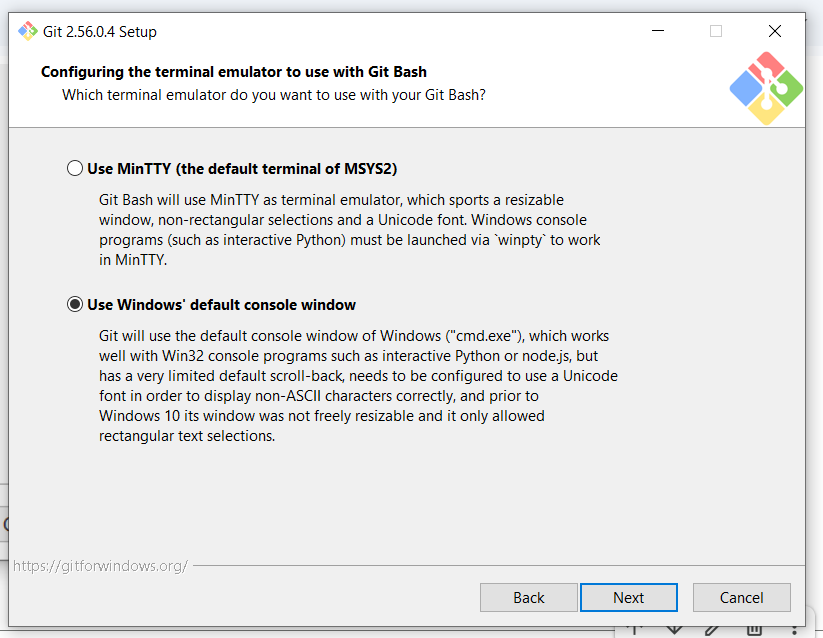

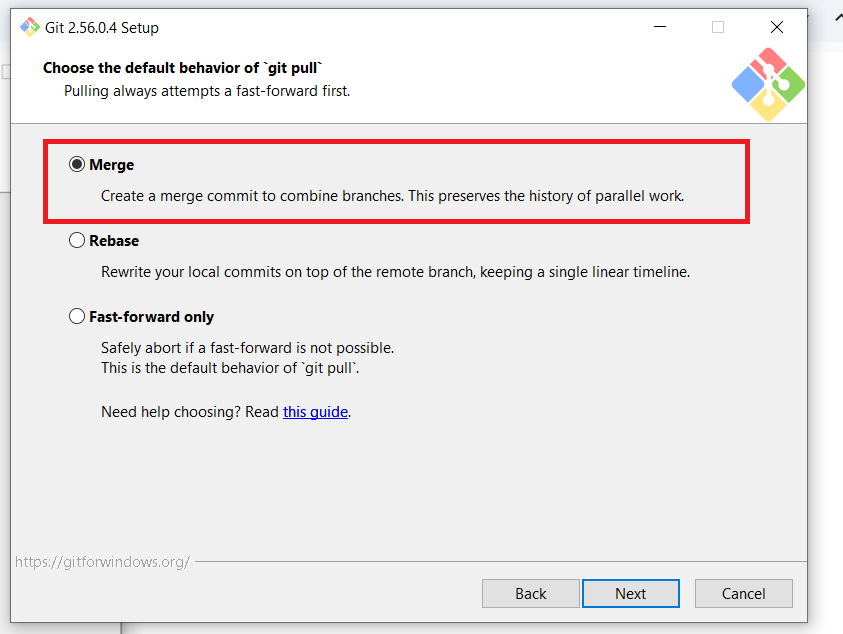

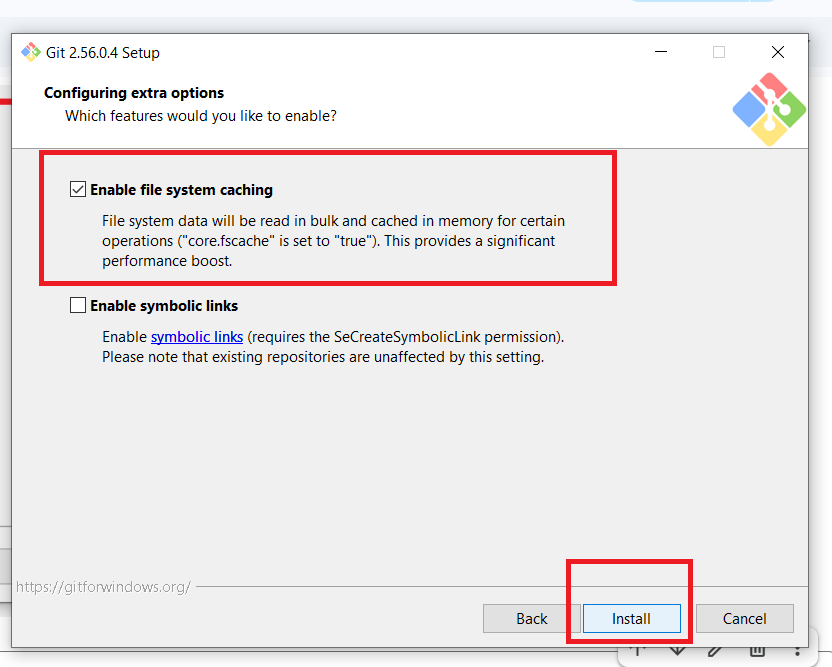

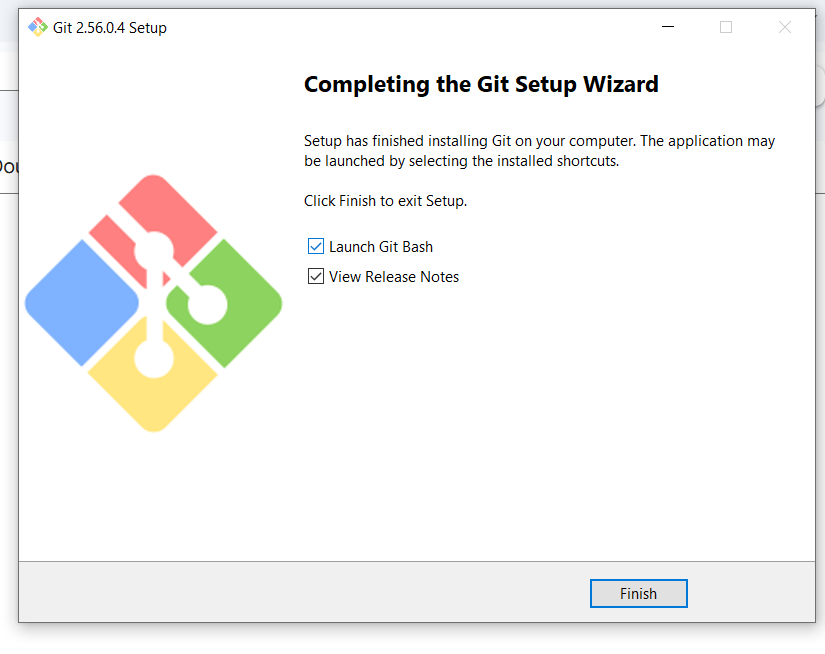